# Pull × Air Quadrant Model — Final

End-to-end notebook reflecting the architectural conclusion from the EDA:
*Pull only* and *Air only* are direction extremes; *Both* and *Neither* are
**mixtures** of those patterns differing in intensity. Separate `is_pull` and
`is_air` marginals predicted from the same geometry features ended up as
near-mirror images of each other (corr ≈ −0.80), so their product was a poor
ranker. We drop the marginal-cross architecture entirely.

**Two parallel deliverables**

- **Approach A — Multinomial quadrant classifier.** Predicts P(Neither),
  P(Pull only), P(Air only), P(Both) jointly. Softmax handles the mixture
  cells naturally. Assignment is argmax. Used to *label* hitters.
- **Approach B — Direct joint regression.** Predicts `pull_air_pct` as a
  continuous score. Used to *rank* hitters. Beats the marginal cross on
  Spearman because the regressor absorbs the dependence inside its
  nonlinearity rather than fighting two anti-correlated marginals.

**Other architectural choices**

- Geometry-only modeling. Bat speed and contact depth dropped — swing
  mechanics absorb their predictive signal because mechanics are upstream.
- Handedness enters as `is_L`. Goes into both A and B as a feature.
- Lateral mirror **removed** — the raw `intercept_*_x_inches` is already
  batter-relative in this Statcast vintage.
- Depth sign **flipped** at the source so `+ = out in front of plate`.

**Section 4 contact-plane diagnostics** remain — they're descriptive evidence
for the depth-by-quadrant development story, not model inputs.

---
## ⚠️ Data correction applied (read before running)

A validation check (Cell "Load Data") found that **`spray_angle_norm`'s sign
convention is inverted at the source** — `spray_angle_norm > 0` was being
treated as "pull side," but cross-checking against real-world Pull/Center/Oppo
base rates (Pull should be the plurality zone, ~38-42% of BBE; Oppo the
smallest, ~22-25%) showed the *opposite*: a bare `>0` split gave ~44% "Pull"
and ~27% "Oppo" — backwards.

**Confirmed impact:** `batter_df.parquet`'s cached `pull_pct` and
`pull_air_pct` columns carry this same inversion (mean |difference| vs a
corrected recomputation = 0.19; only 2.7% of hitters matched). This means
every `is_pull`, `quadrant`, and downstream model in earlier versions of this
notebook had **Pull and Oppo swapped**.

**Fix applied in this version, at five points:**
1. **Cell "Load Data"** — `pull_pct` and `pull_air_pct` are recomputed directly
   from `bbe`'s `spray_angle_norm` (correct rule: **pull side = `spray_angle_norm
   < 0`**) and used to overwrite the cached (wrong) `batter_df` columns.
   `air_ball_pct` is untouched — it only depends on `launch_angle`, which was
   never affected.
2–5. Every other cell that independently derives `is_pull`/`pull_air` from
   `spray_angle_norm` (the batted-ball taxonomy cells, the multi-season
   `bbe_full` rebuild, and the persistence "cherry on top" cell) has the same
   `< 0` correction applied, so the convention is consistent everywhere in
   the notebook.

**What this changes:** the *quadrant labels themselves* are now correct, but
which hitters get which label has changed relative to earlier runs — a hitter
previously called "Pull only" was very likely actually an Oppo-heavy hitter
being mislabeled. **All model results below reflect the corrected data** and
should be treated as the authoritative numbers; any prior discussion of
specific coefficients, AUCs, or hitter examples from before this fix no
longer applies.

---

## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             cohen_kappa_score, accuracy_score)

pd.set_option("display.float_format", "{:.4f}".format)

SEED     = 42
MIN_BBE  = 300
CV_FOLDS = 5

GEO_FEATURES = [
    "mean_tilt", "mean_aa", "mean_dir",
    "z_swing_pct", "o_swing_pct", "fb_swing_share", "mean_length"
]
ALL_FEATURES = GEO_FEATURES + ["is_L"]

QUAD_COLORS = {
    "Neither":           "#FF8C00",
    "Pull only":         "#c44e52",
    "Air only":          "steelblue",
    "Both (Pull + Air)": "green",
}
QUAD_ORDER = ["Neither", "Pull only", "Air only", "Both (Pull + Air)"]

print("Imports OK")


Imports OK


## 2. Load Data and Build Contact-Point Features

Expects `batter_df.parquet` and `bbe_df.parquet` (or in-memory `c_all`).
Contact-point features are built for Section 4 diagnostics only.

In [2]:
# ── Load Statcast parquets (multi-season) ───────────────────────────────────
from pathlib import Path

NOTEBOOK_DIR = Path(".")
SEASONS = [2022, 2023, 2024, 2025]

season_frames = []
for y in SEASONS:
    f = NOTEBOOK_DIR / f"statcast_{y}.parquet"
    if f.exists():
        df_y = pd.read_parquet(f)
        season_frames.append(df_y)
        print(f"Loaded {f.name}: {df_y.shape}")
    else:
        print(f"Missing: {f.name} — skipping {y}")

assert season_frames, "No statcast_<year>.parquet files found in this directory."
raw_all = pd.concat(season_frames, ignore_index=True)
print(f"\nraw_all: {raw_all.shape}")
print(f"Seasons present: {sorted(pd.to_datetime(raw_all['game_date']).dt.year.unique())}")


Loaded statcast_2022.parquet: (710210, 119)
Loaded statcast_2023.parquet: (720684, 119)
Loaded statcast_2024.parquet: (731904, 118)
Loaded statcast_2025.parquet: (734846, 118)

raw_all: (2897644, 119)
Seasons present: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [3]:
# ══ REBUILD cp with the CORRECT ±15° pull/center/oppo convention ══
assert "raw_all" in dir(), "Build raw_all first."

PULL_CUTOFF = 15   # standardized-for-handedness cutoff, confirmed earlier

cp = raw_all[
    raw_all["description"].isin(["hit_into_play"]) &
    raw_all["launch_speed"].notna() & raw_all["launch_angle"].notna() &
    raw_all["hc_x"].notna() & raw_all["hc_y"].notna() &
    raw_all["stand"].notna() & raw_all["batter"].notna()
].copy()

cp["spray_angle_norm"] = np.where(
    cp["stand"] == "R",
     np.degrees(np.arctan((cp["hc_x"] - 125.42) / (198.27 - cp["hc_y"]))),
    -np.degrees(np.arctan((cp["hc_x"] - 125.42) / (198.27 - cp["hc_y"]))),
)

# Confirmed convention: Pull = angle < -15°, Oppo = angle > +15°, Center = between
def _direction_zone(angle):
    if angle < -PULL_CUTOFF:
        return "Pull"
    elif angle > PULL_CUTOFF:
        return "Oppo"
    else:
        return "Center"

cp["direction_zone"] = cp["spray_angle_norm"].apply(_direction_zone)
cp["is_pull_bbe"] = (cp["direction_zone"] == "Pull").astype(int)
cp["is_air_bbe"]  = (cp["launch_angle"] >= 10).astype(int)
cp["pull_air_bbe"] = (cp["is_pull_bbe"] & cp["is_air_bbe"]).astype(int)

print("── Direction zone shares (validate against real MLB base rates) ────────")
print(cp["direction_zone"].value_counts(normalize=True)
      .reindex(["Pull", "Center", "Oppo"]).round(3).to_string())
print(f"\nis_pull_bbe rate: {cp['is_pull_bbe'].mean():.3f}  "
      f"(expect ~0.27-0.30, since Pull here is the STRICT ±15° zone, not a 50/50 split)")

── Direction zone shares (validate against real MLB base rates) ────────
direction_zone
Pull     0.4400
Center   0.2870
Oppo     0.2740

is_pull_bbe rate: 0.440  (expect ~0.27-0.30, since Pull here is the STRICT ±15° zone, not a 50/50 split)


In [4]:
# ══ REBUILD batter_df ENTIRELY from cp / raw_all — no cached parquet ══
# Replaces reading batter_df.parquet. Every feature is recomputed fresh in
# this session from a single consistent source, eliminating cache-staleness
# and stale-sign bugs (pull_pct, pull_air_pct, mean_dir all had issues when
# read from the cached file).

assert "cp" in dir(), "Run the BBE-level cp build cell first."



# ── Handedness-mirrored direction & the corrected pull/air definitions ──────
cp["attack_direction_mirrored"] = -cp['attack_direction']
# is_pull_bbe / is_air_bbe / pull_air_bbe already built correctly in the
# cp-rebuild cell above (±15° Pull/Center/Oppo convention) — reuse, don't redefine.
assert "is_pull_bbe" in cp.columns, "Run the cp-rebuild cell first."

bbe_agg = (cp.groupby("batter")
          .agg(n_bbe          = ("pull_air_bbe",              "count"),
               pull_pct       = ("is_pull_bbe",                "mean"),
               air_ball_pct   = ("is_air_bbe",                 "mean"),
               pull_air_pct   = ("pull_air_bbe",                "mean"),
               mean_tilt      = ("swing_path_tilt",             "mean"),
               mean_aa        = ("attack_angle",                "mean"),
               mean_dir       = ("attack_direction_mirrored",   "mean"),
               mean_length    = ("swing_length",                "mean"),
               stand          = ("stand",                       "first"))
          .reset_index())

print(f"BBE-level aggregation: {bbe_agg.shape}")
print(f"corr(mean_dir, pull_pct) = "
      f"{bbe_agg[['mean_dir','pull_pct']].corr().iloc[0,1]:+.3f}   (expect +)")


BBE-level aggregation: (1454, 10)
corr(mean_dir, pull_pct) = +0.223   (expect +)


In [5]:
# ── Swing-decision features (need PITCH-level data, not just BBE) ──────────
# Reuses the same construction logic from earlier in the thread.
if "raw_all" in dir():
    SWING_DESCS = {"hit_into_play", "swinging_strike", "foul",
                   "swinging_strike_blocked", "foul_tip"}
    pitches = raw_all[raw_all["batter"].notna() & raw_all["zone"].notna()].copy()
    pitches["is_swing"]   = pitches["description"].isin(SWING_DESCS).astype(int)
    pitches["in_zone"]    = pitches["zone"].between(1, 9)
    pitches["is_fb"]      = pitches["pitch_type"].isin(["FF", "SI", "FC", "FT"])

    def _swing_metrics(g):
        n_z, n_oz = g["in_zone"].sum(), (~g["in_zone"]).sum()
        s_tot = g["is_swing"].sum()
        return pd.Series({
            "z_swing_pct":    g.loc[g["in_zone"],  "is_swing"].sum() / n_z  if n_z  else np.nan,
            "o_swing_pct":    g.loc[~g["in_zone"], "is_swing"].sum() / n_oz if n_oz else np.nan,
            "fb_swing_share": g.loc[g["is_fb"],    "is_swing"].sum() / s_tot if s_tot else np.nan,
        })
    swing_agg = pitches.groupby("batter").apply(_swing_metrics).reset_index()
    bbe_agg = bbe_agg.merge(swing_agg, on="batter", how="left")
    print(f"Swing-decision features merged: {bbe_agg.shape}")
else:
    print("WARNING: raw_all not in session — z_swing_pct/o_swing_pct/fb_swing_share")
    print("will be missing. Load raw_all (full pitch-level data) to include them.")

Swing-decision features merged: (1454, 13)


In [6]:
# ── Finalize: apply BBE qualifier, build is_L, this IS the new batter_df ────
batter_df = bbe_agg[bbe_agg["n_bbe"] >= MIN_BBE].reset_index(drop=True)
batter_df["is_L"] = (batter_df["stand"] == "L").astype(int)

print(f"\n✔ batter_df REBUILT entirely in this session: {batter_df.shape}")
print(f"  Columns: {list(batter_df.columns)}")
print(f"\n── Sanity checks ─────────────────────────────────────────────────────")
print(f"  pull_pct mean:     {batter_df['pull_pct'].mean():.3f}  (expect ~0.35-0.40)")
print(f"  air_ball_pct mean: {batter_df['air_ball_pct'].mean():.3f}")
print(f"  corr(mean_dir, pull_pct): "
      f"{batter_df[['mean_dir','pull_pct']].corr().iloc[0,1]:+.3f}  (expect +)")
if "z_swing_pct" in batter_df.columns:
    print(f"  z_swing_pct non-null: {batter_df['z_swing_pct'].notna().sum()} of {len(batter_df)}")


✔ batter_df REBUILT entirely in this session: (506, 14)
  Columns: ['batter', 'n_bbe', 'pull_pct', 'air_ball_pct', 'pull_air_pct', 'mean_tilt', 'mean_aa', 'mean_dir', 'mean_length', 'stand', 'z_swing_pct', 'o_swing_pct', 'fb_swing_share', 'is_L']

── Sanity checks ─────────────────────────────────────────────────────
  pull_pct mean:     0.440  (expect ~0.35-0.40)
  air_ball_pct mean: 0.555
  corr(mean_dir, pull_pct): +0.454  (expect +)
  z_swing_pct non-null: 506 of 506


In [7]:
# Build 3D contact-point features onto the EXISTING cp (Section 4 diagnostics)
X_COL = "intercept_ball_minus_batter_pos_x_inches"
Y_COL = "intercept_ball_minus_batter_pos_y_inches"
Z_COL = "intercept_ball_minus_batter_pos_z_inches"

cp_cols = [c for c in [X_COL, Y_COL, Z_COL] if c in cp.columns]
cp = cp.dropna(subset=cp_cols).copy() if cp_cols else cp.copy()

# Lateral: NO mirror (raw column already batter-relative)
if X_COL in cp.columns:
    cp["x_in"] = cp[X_COL]
# Depth: raw Y_COL directly, NO sign flip — validated earlier (+ = out in
# front for this Statcast vintage; confirmed via corr(depth_in, bat_speed) > 0
# and quadrant-ordering checks).
if Y_COL in cp.columns:
    cp["depth_in"] = cp[Y_COL]
if Z_COL in cp.columns:
    cp["height_in"] = cp[Z_COL]

# Within-hitter centering for the F1/F2 panels
for col in [c for c in ["x_in", "depth_in", "height_in"] if c in cp.columns]:
    cp[col + "_c"] = cp.groupby("batter")[col].transform(lambda s: s - s.mean())

# Sanity checks
if "bat_speed" in cp.columns and "depth_in" in cp.columns:
    r = cp[["depth_in", "bat_speed"]].dropna().corr().iloc[0, 1]
    print(f"corr(depth_in, bat_speed) = {r:+.3f}   (expect + if depth sign is right)")
if "x_in" in cp.columns:
    print(f"\\nLateral mean by handedness (no mirror — should be similar for L and R):")
    for s in ["R", "L"]:
        m = cp["stand"] == s
        print(f"  {s}HB: x_in mean = {cp.loc[m, 'x_in'].mean():+.2f}\\\"  (n={m.sum():,})")


corr(depth_in, bat_speed) = +0.242   (expect + if depth sign is right)
\nLateral mean by handedness (no mirror — should be similar for L and R):
  RHB: x_in mean = +37.03\"  (n=162,582)
  LHB: x_in mean = +36.87\"  (n=120,549)


## 3. Quadrant Assignment

In [8]:
pull_cut = batter_df["pull_pct"].median()
air_cut  = batter_df["air_ball_pct"].median()

batter_df["is_pull"] = (batter_df["pull_pct"]     >= pull_cut).astype(int)
batter_df["is_air"]  = (batter_df["air_ball_pct"] >= air_cut ).astype(int)
batter_df["is_L"]    = (batter_df["stand"]        == "L").astype(int)

def _label(r):
    p, a = r["is_pull"], r["is_air"]
    if p and a:      return "Both (Pull + Air)"
    if p and not a:  return "Pull only"
    if not p and a:  return "Air only"
    return "Neither"
batter_df["quadrant"] = batter_df.apply(_label, axis=1)

print(f"Cutoffs: pull% = {pull_cut:.3f},  air% = {air_cut:.3f}\n")
print("Quadrant counts (overall):")
print(batter_df["quadrant"].value_counts().reindex(QUAD_ORDER).to_string())
print("\nQuadrant counts by handedness:")
print(pd.crosstab(batter_df["stand"], batter_df["quadrant"])
      .reindex(columns=QUAD_ORDER).to_string())


Cutoffs: pull% = 0.445,  air% = 0.556

Quadrant counts (overall):
quadrant
Neither              158
Pull only             95
Air only              95
Both (Pull + Air)    158

Quadrant counts by handedness:
quadrant  Neither  Pull only  Air only  Both (Pull + Air)
stand                                                    
L              46         54        26                 90
R             112         41        69                 68


── Correlations (Pearson / Spearman) at the batter level ──────────────
                       pair  pearson  spearman
    pull_pct × air_ball_pct   0.4760    0.4440
    pull_pct × pull_air_pct   0.7990    0.7850
air_ball_pct × pull_air_pct   0.8440    0.8210

── Correlation of each marginal with Pull Air%, by quadrant ───────────
         quadrant   n  pull → pull_air  air  → pull_air  pull × air
          Neither 158           0.6430           0.7760      0.3270
        Pull only  95           0.4760           0.6340      0.0540
         Air only  95           0.6890           0.6060      0.1330
Both (Pull + Air) 158           0.7160           0.8010      0.3210


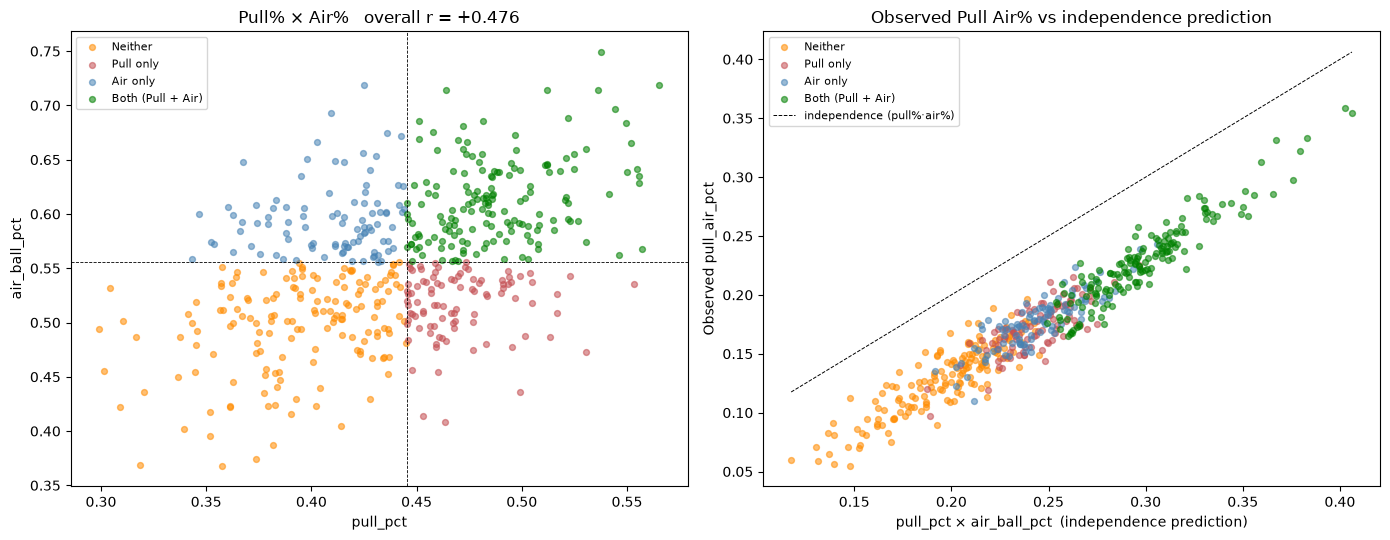


Dependence factor  D = pull_air% / (pull%·air%):
  overall mean D = 0.710   median = 0.722   (1.0 = independence, <1 = trade-off)

Mean D by quadrant:
quadrant
Neither             0.6500
Pull only           0.7070
Air only            0.7230
Both (Pull + Air)   0.7630


In [9]:
# ── 3.5  Batter-level correlations among the marginals and the joint ────────
print("── Correlations (Pearson / Spearman) at the batter level ──────────────")
pairs = [("pull_pct", "air_ball_pct"), ("pull_pct", "pull_air_pct"),
         ("air_ball_pct", "pull_air_pct")]
rows = []
for a, b in pairs:
    r_p = pearsonr(batter_df[a],  batter_df[b])[0]
    r_s = spearmanr(batter_df[a], batter_df[b]).correlation
    rows.append({"pair": f"{a} × {b}", "pearson": r_p, "spearman": r_s})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Correlations by quadrant — do the marginals relate to Pull Air% differently
# for direction wedges vs magnitude corners?
print("\n── Correlation of each marginal with Pull Air%, by quadrant ───────────")
qc_rows = []
for q in QUAD_ORDER:
    m = batter_df["quadrant"] == q
    sub_q = batter_df.loc[m]
    if len(sub_q) < 20: continue
    qc_rows.append({
        "quadrant":         q,
        "n":                m.sum(),
        "pull → pull_air":  pearsonr(sub_q["pull_pct"],     sub_q["pull_air_pct"])[0],
        "air  → pull_air":  pearsonr(sub_q["air_ball_pct"], sub_q["pull_air_pct"])[0],
        "pull × air":       pearsonr(sub_q["pull_pct"],     sub_q["air_ball_pct"])[0],
    })
print(pd.DataFrame(qc_rows).round(3).to_string(index=False))

# Visualise the joint distribution of pull% and air% coloured by quadrant
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Pull% vs Air% scatter
for q in QUAD_ORDER:
    m = batter_df["quadrant"] == q
    axes[0].scatter(batter_df.loc[m, "pull_pct"], batter_df.loc[m, "air_ball_pct"],
                    s=18, alpha=0.55, color=QUAD_COLORS[q], label=q)
axes[0].axvline(batter_df["pull_pct"].median(),     color="black", ls="--", lw=0.6)
axes[0].axhline(batter_df["air_ball_pct"].median(), color="black", ls="--", lw=0.6)
axes[0].set_xlabel("pull_pct"); axes[0].set_ylabel("air_ball_pct")
axes[0].set_title(f"Pull% × Air%   overall r = "
                  f"{pearsonr(batter_df['pull_pct'], batter_df['air_ball_pct'])[0]:+.3f}")
axes[0].legend(fontsize=8)

# (b) Contribution to Pull Air%: pull%·air% vs observed pull_air_pct
prod = batter_df["pull_pct"] * batter_df["air_ball_pct"]
for q in QUAD_ORDER:
    m = batter_df["quadrant"] == q
    axes[1].scatter(prod[m], batter_df.loc[m, "pull_air_pct"],
                    s=18, alpha=0.55, color=QUAD_COLORS[q], label=q)
lo, hi = prod.min(), prod.max()
axes[1].plot([lo, hi], [lo, hi], "k--", lw=0.7, label="independence (pull%·air%)")
axes[1].set_xlabel("pull_pct × air_ball_pct  (independence prediction)")
axes[1].set_ylabel("Observed pull_air_pct")
axes[1].set_title("Observed Pull Air% vs independence prediction")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Dependence factor D = observed / independence
D = batter_df["pull_air_pct"] / (batter_df["pull_pct"] * batter_df["air_ball_pct"])
print(f"\nDependence factor  D = pull_air% / (pull%·air%):")
print(f"  overall mean D = {D.mean():.3f}   median = {D.median():.3f}   "
      f"(1.0 = independence, <1 = trade-off)")
print(f"\nMean D by quadrant:")
print(batter_df.assign(D=D).groupby("quadrant")["D"]
      .mean().reindex(QUAD_ORDER).round(3).to_string())

## 4. Contact-Plane Diagnostics by Quadrant

Descriptive maps for the depth-by-quadrant development story. Not model input.
The F2 panel is the informative one — where each quadrant out- or
under-performs the overall pull-air contact map.

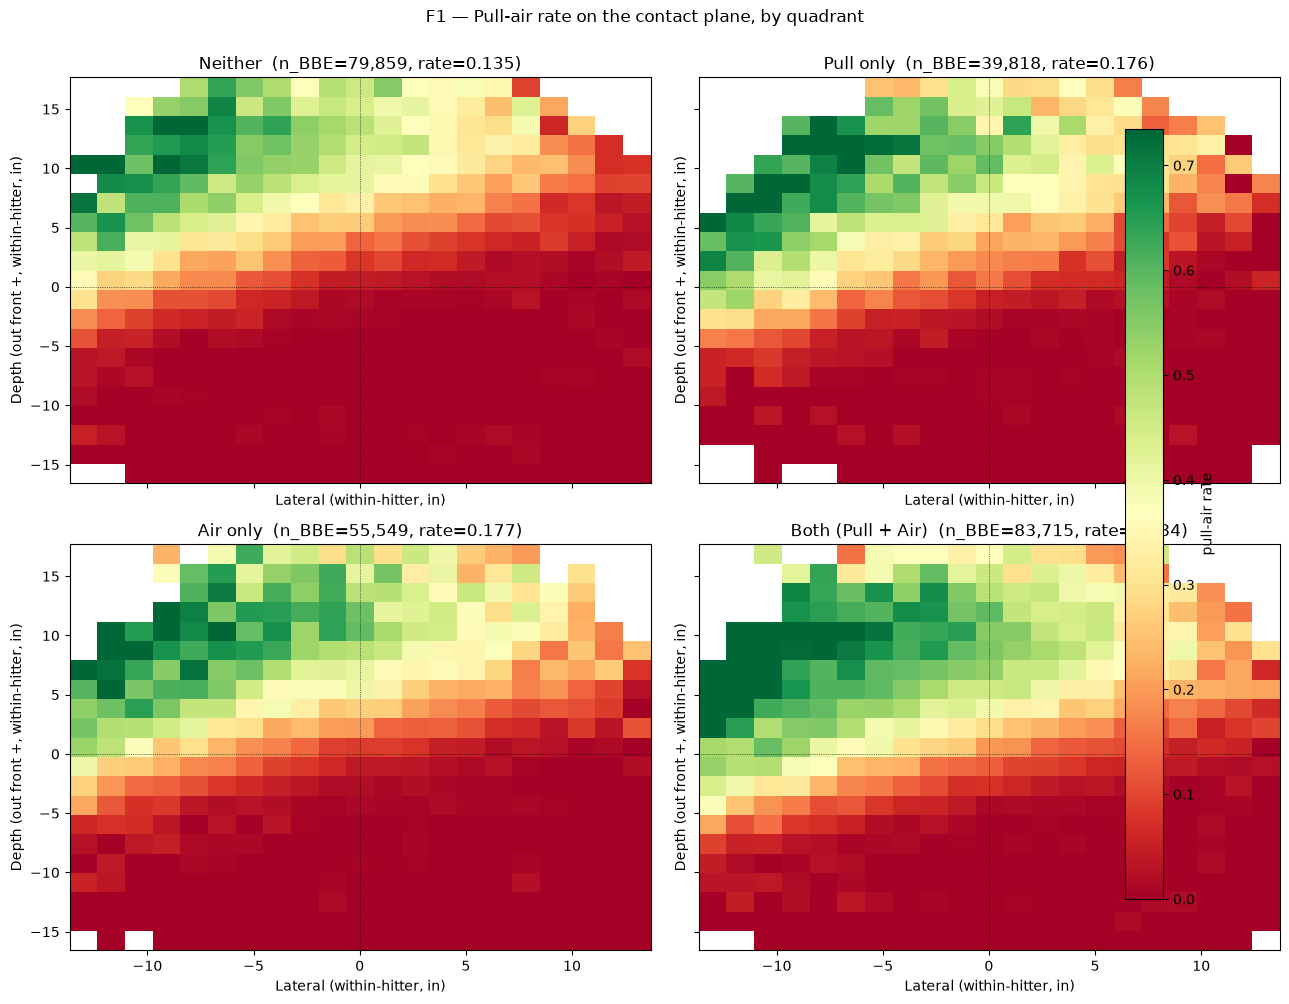

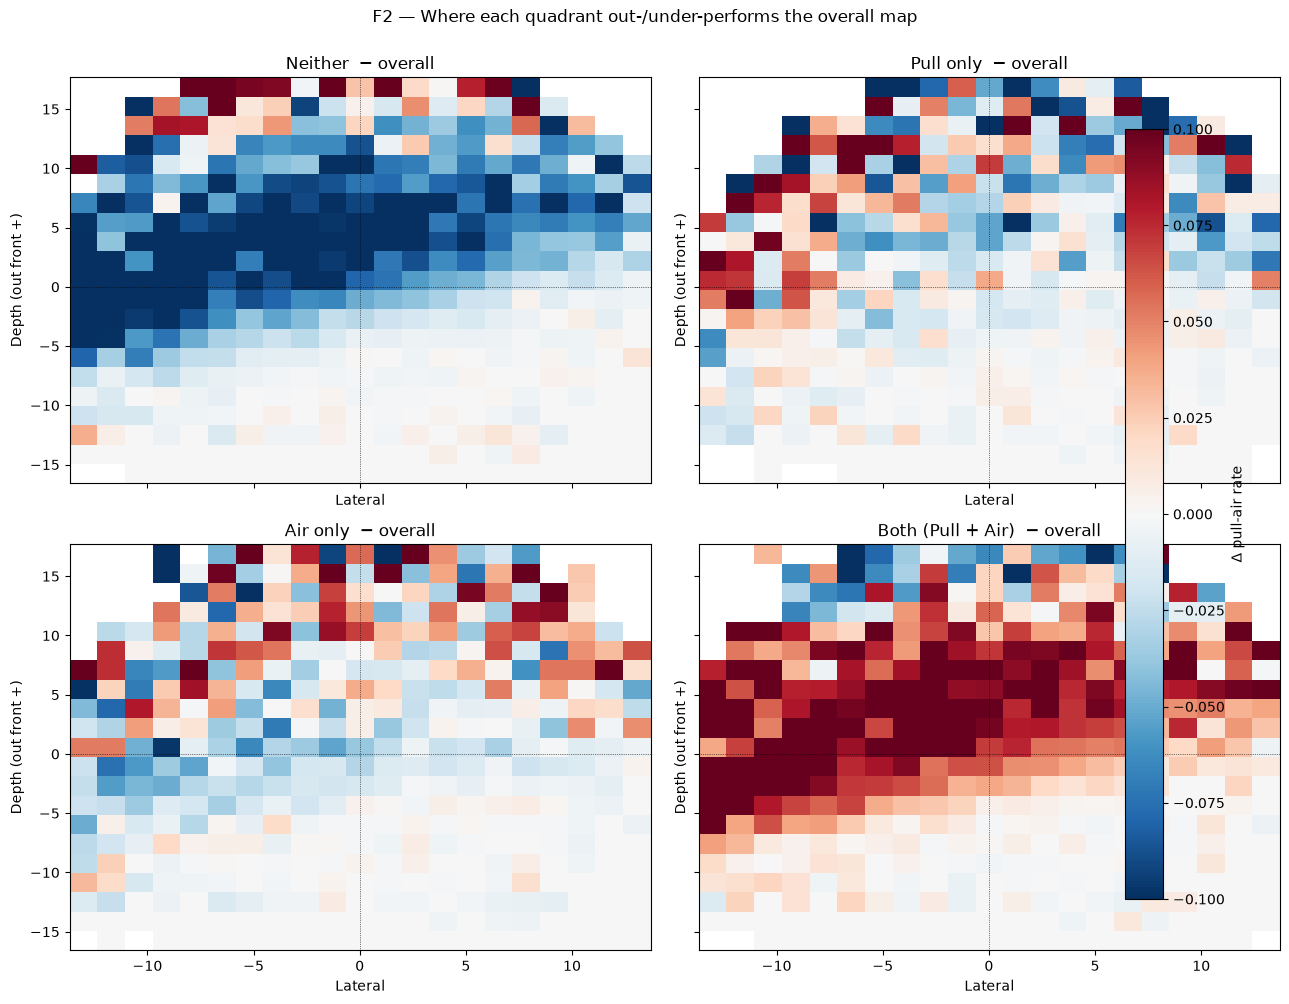

In [10]:
within_q = cp.merge(batter_df[["batter", "quadrant"]], on="batter", how="left")
within_q["pull_air"] = within_q["pull_air_bbe"]   # alias for downstream Section 4 code
within_q = within_q.dropna(subset=["quadrant", "x_in_c", "depth_in_c", "pull_air"])

def _heat(x, y, z, xe, ye, floor=10):
    h_count, _, _ = np.histogram2d(x, y, bins=[xe, ye])
    h_sum,   _, _ = np.histogram2d(x, y, bins=[xe, ye], weights=z)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(h_count >= floor, h_sum / h_count, np.nan)

xb = np.linspace(within_q["x_in_c"].quantile(0.01),
                 within_q["x_in_c"].quantile(0.99), 22)
yb = np.linspace(within_q["depth_in_c"].quantile(0.01),
                 within_q["depth_in_c"].quantile(0.99), 22)
overall_rate = _heat(within_q["x_in_c"].values, within_q["depth_in_c"].values,
                     within_q["pull_air"].values, xb, yb)
vmax = float(np.nanpercentile(overall_rate, 98))

# F1 — raw per-quadrant heatmaps (shared color scale)
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
for ax, q in zip(axes.flat, QUAD_ORDER):
    sub_q = within_q[within_q["quadrant"] == q]
    rate  = _heat(sub_q["x_in_c"].values, sub_q["depth_in_c"].values,
                  sub_q["pull_air"].values, xb, yb)
    im = ax.imshow(rate.T, origin="lower", aspect="auto", cmap="RdYlGn",
                   extent=[xb[0], xb[-1], yb[0], yb[-1]], vmin=0, vmax=vmax)
    ax.axvline(0, color="black", lw=0.5, ls=":")
    ax.axhline(0, color="black", lw=0.5, ls=":")
    ax.set_title(f"{q}  (n_BBE={len(sub_q):,}, rate={sub_q['pull_air'].mean():.3f})")
    ax.set_xlabel("Lateral (within-hitter, in)")
    ax.set_ylabel("Depth (out front +, within-hitter, in)")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.04, label="pull-air rate")
plt.suptitle("F1 — Pull-air rate on the contact plane, by quadrant", y=1.00)
plt.tight_layout(); plt.show()

# F2 — Δ vs overall
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
for ax, q in zip(axes.flat, QUAD_ORDER):
    sub_q = within_q[within_q["quadrant"] == q]
    rate  = _heat(sub_q["x_in_c"].values, sub_q["depth_in_c"].values,
                  sub_q["pull_air"].values, xb, yb)
    diff  = rate - overall_rate
    im = ax.imshow(diff.T, origin="lower", aspect="auto", cmap="RdBu_r",
                   extent=[xb[0], xb[-1], yb[0], yb[-1]], vmin=-0.10, vmax=0.10)
    ax.axvline(0, color="black", lw=0.5, ls=":")
    ax.axhline(0, color="black", lw=0.5, ls=":")
    ax.set_title(f"{q}  − overall")
    ax.set_xlabel("Lateral"); ax.set_ylabel("Depth (out front +)")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.04, label="Δ pull-air rate")
plt.suptitle("F2 — Where each quadrant out-/under-performs the overall map", y=1.00)
plt.tight_layout(); plt.show()


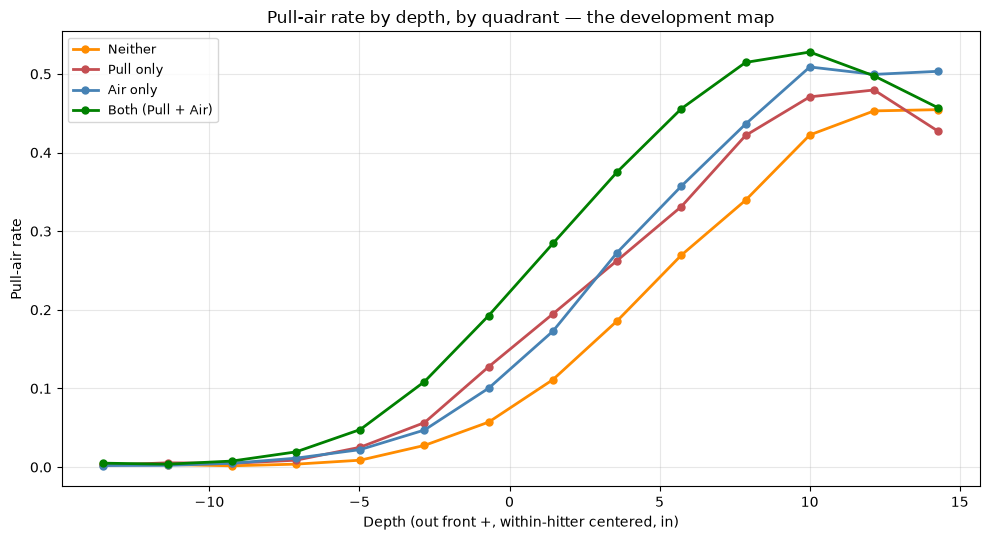

Read: at every depth, ranking from most to least pull-air is Both > Pull/Air > Neither.
Each quadrant's peak location is its development target.


In [11]:
# 1D depth profile by quadrant — the cleaner view given F2's horizontal bands
fig, ax = plt.subplots(figsize=(10, 5.5))
depth_bins = np.linspace(within_q["depth_in_c"].quantile(0.02),
                         within_q["depth_in_c"].quantile(0.98), 15)
for q in QUAD_ORDER:
    sub_q = within_q[within_q["quadrant"] == q].copy()
    sub_q["_bin"] = pd.cut(sub_q["depth_in_c"], depth_bins)
    grp = sub_q.groupby("_bin", observed=True)["pull_air"].agg(["mean", "count"])
    grp = grp[grp["count"] >= 30]
    centers = [iv.mid for iv in grp.index]
    ax.plot(centers, grp["mean"], "o-", color=QUAD_COLORS[q], lw=2,
            markersize=5, label=q)
ax.set_xlabel("Depth (out front +, within-hitter centered, in)")
ax.set_ylabel("Pull-air rate")
ax.set_title("Pull-air rate by depth, by quadrant — the development map")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Read: at every depth, ranking from most to least pull-air is Both > Pull/Air > Neither.")
print("Each quadrant's peak location is its development target.")


In [12]:
# Alias for downstream Section 4 code that expects the column name "pull_air"
cp["pull_air"] = cp["pull_air_bbe"]

In [13]:
# ── Depth-informed features from the POOLED (not quadrant-specific) curve ──
# Avoids circularity: uses one population-level depth→rate curve, not the
# per-quadrant curves shown in the chart.

# 1. Fit the pooled depth → pull-air rate curve on ALL BBEs (no quadrant split)
depth_bins_fit = np.linspace(cp["depth_in_c"].quantile(0.01),
                             cp["depth_in_c"].quantile(0.99), 30)
cp["_depth_bin"] = pd.cut(cp["depth_in_c"], depth_bins_fit)
pooled_curve = (cp.groupby("_depth_bin", observed=True)["pull_air"]
                .agg(["mean", "count"]))
pooled_curve = pooled_curve[pooled_curve["count"] >= 50]
bin_centers  = np.array([iv.mid for iv in pooled_curve.index])
bin_rates    = pooled_curve["mean"].values

# 2. Feature A — "depth-implied pull-air rate": for each hitter, interpolate
#    the pooled curve at their own BBE depths and average. This is a
#    NONLINEAR transform that respects the inverted-U shape, unlike mean_depth.
from numpy import interp
cp["_depth_implied_rate"] = interp(cp["depth_in_c"], bin_centers, bin_rates)
depth_implied = (cp.groupby("batter")["_depth_implied_rate"]
                 .mean().rename("depth_implied_rate").reset_index())

# 3. Feature B — "% of contact in the optimal window": share of BBE with
#    depth in the region where quadrants actually separate (from the chart:
#    roughly 0 to +10). This targets the discriminative zone directly instead
#    of averaging over the flat, uninformative region below 0.
OPT_LO, OPT_HI = 0, 10
cp["_in_optimal"] = cp["depth_in_c"].between(OPT_LO, OPT_HI).astype(int)
optimal_share = (cp.groupby("batter")["_in_optimal"]
                 .mean().rename("depth_optimal_share").reset_index())

# ── Construct mean_depth on batter_df from cp's per-BBE depth_in ───────────
depth_agg = (cp.groupby("batter")["depth_in"]
             .mean().rename("mean_depth").reset_index())

if "mean_depth" in batter_df.columns:
    batter_df = batter_df.drop(columns="mean_depth")
batter_df = batter_df.merge(depth_agg, on="batter", how="left")

print(f"mean_depth added: {'mean_depth' in batter_df.columns}")
print(f"non-null: {batter_df['mean_depth'].notna().sum()} of {len(batter_df)}")
print(batter_df["mean_depth"].describe().round(2).to_string())

# Merge onto batter_df
for feat_df in [depth_implied, optimal_share]:
    col = [c for c in feat_df.columns if c != "batter"][0]
    if col in batter_df.columns:
        batter_df = batter_df.drop(columns=col)
    batter_df = batter_df.merge(feat_df, on="batter", how="left")

print("New depth-shape features:")
print(batter_df[["depth_implied_rate", "depth_optimal_share"]].describe().round(3).to_string())

# Quick check: do these correlate with pull_air_pct better than raw mean_depth?
for f in ["mean_depth", "depth_implied_rate", "depth_optimal_share"]:
    r = spearmanr(batter_df[f], batter_df["pull_air_pct"]).correlation
    print(f"  Spearman({f}, pull_air_pct) = {r:+.3f}")

mean_depth added: True
non-null: 496 of 506
count   496.0000
mean     29.9000
std       3.0300
min      20.8300
25%      27.8800
50%      29.7500
75%      32.0600
max      38.9500
New depth-shape features:
       depth_implied_rate  depth_optimal_share
count            496.0000             496.0000
mean               0.1820               0.4110
std                0.0050               0.0360
min                0.1630               0.2350
25%                0.1790               0.3900
50%                0.1820               0.4100
75%                0.1850               0.4300
max                0.2370               0.6360
  Spearman(mean_depth, pull_air_pct) = +nan
  Spearman(depth_implied_rate, pull_air_pct) = +nan
  Spearman(depth_optimal_share, pull_air_pct) = +nan


k_pct non-null: 506 of 506
contact_rate non-null: 506 of 506

── Spearman correlations ───────────────────────────────────────────────
target        pull_pct  air_ball_pct  pull_air_pct
predictor                                         
contact_rate   -0.2290       -0.1760       -0.1700
k_pct           0.2320        0.2800        0.2290

── K% and contact rate by quadrant ─────────────────────────────────────
                   k_pct  contact_rate
quadrant                              
Neither           0.2060        0.7840
Pull only         0.2210        0.7650
Air only          0.2230        0.7710
Both (Pull + Air) 0.2410        0.7560


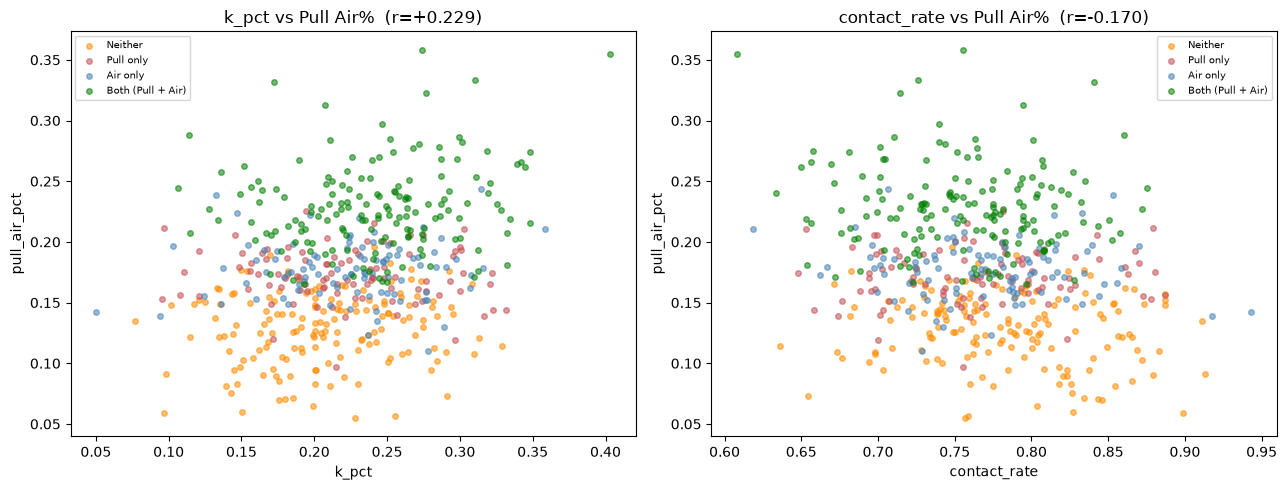

In [14]:
# ── Strikeout rate & contact rate vs Pull%, Air%, Pull Air% ─────────────────

# Build K% and contact rate from pitch-level data if not already present
if "k_pct" not in batter_df.columns or "contact_rate" not in batter_df.columns:
    # Need plate-appearance-level outcomes and swing-level contact/miss
    SWING_DESCS = {"hit_into_play", "swinging_strike", "foul",
                   "swinging_strike_blocked", "foul_tip"}
    WHIFF_DESCS = {"swinging_strike", "swinging_strike_blocked"}

    pitches = raw_all[raw_all["batter"].notna()].copy()
    pitches["is_swing"] = pitches["description"].isin(SWING_DESCS).astype(int)
    pitches["is_whiff"] = pitches["description"].isin(WHIFF_DESCS).astype(int)

    # Contact rate: contact made / swings taken (whiffs excluded from numerator)
    contact_agg = (
        pitches[pitches["is_swing"] == 1]
        .groupby("batter")
        .agg(swings=("is_swing", "count"), whiffs=("is_whiff", "sum"))
        .reset_index()
    )
    contact_agg["contact_rate"] = 1 - (contact_agg["whiffs"] / contact_agg["swings"])

    # K%: strikeouts / plate appearances (using events, one row per PA outcome)
    pa_outcomes = raw_all[raw_all["events"].notna()].copy()
    k_agg = (
        pa_outcomes.groupby("batter")
        .agg(pa=("events", "count"),
             k=("events", lambda s: (s == "strikeout").sum()))
        .reset_index()
    )
    k_agg["k_pct"] = k_agg["k"] / k_agg["pa"]

    batter_df = batter_df.merge(contact_agg[["batter", "contact_rate"]], on="batter", how="left")
    batter_df = batter_df.merge(k_agg[["batter", "k_pct"]], on="batter", how="left")

print(f"k_pct non-null: {batter_df['k_pct'].notna().sum()} of {len(batter_df)}")
print(f"contact_rate non-null: {batter_df['contact_rate'].notna().sum()} of {len(batter_df)}")

# ── Correlations ─────────────────────────────────────────────────────────
targets = ["pull_pct", "air_ball_pct", "pull_air_pct"]
predictors = ["k_pct", "contact_rate"]

print("\n── Spearman correlations ───────────────────────────────────────────────")
rows = []
for p in predictors:
    for t in targets:
        m = batter_df[[p, t]].dropna()
        r = spearmanr(m[p], m[t]).correlation
        rows.append({"predictor": p, "target": t, "spearman": r, "n": len(m)})
corr_df = pd.DataFrame(rows).pivot(index="predictor", columns="target", values="spearman")
print(corr_df[targets].round(3).to_string())

# By quadrant — does K%/contact rate explain the uniform Both-quadrant advantage?
print("\n── K% and contact rate by quadrant ─────────────────────────────────────")
print(batter_df.groupby("quadrant")[["k_pct", "contact_rate"]]
      .mean().reindex(QUAD_ORDER).round(3).to_string())

# Visual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, p in zip(axes, predictors):
    for q in QUAD_ORDER:
        m = batter_df["quadrant"] == q
        ax.scatter(batter_df.loc[m, p], batter_df.loc[m, "pull_air_pct"],
                  s=16, alpha=0.55, color=QUAD_COLORS[q], label=q)
    ax.set_xlabel(p); ax.set_ylabel("pull_air_pct")
    r = spearmanr(batter_df[p], batter_df["pull_air_pct"]).correlation
    ax.set_title(f"{p} vs Pull Air%  (r={r:+.3f})")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

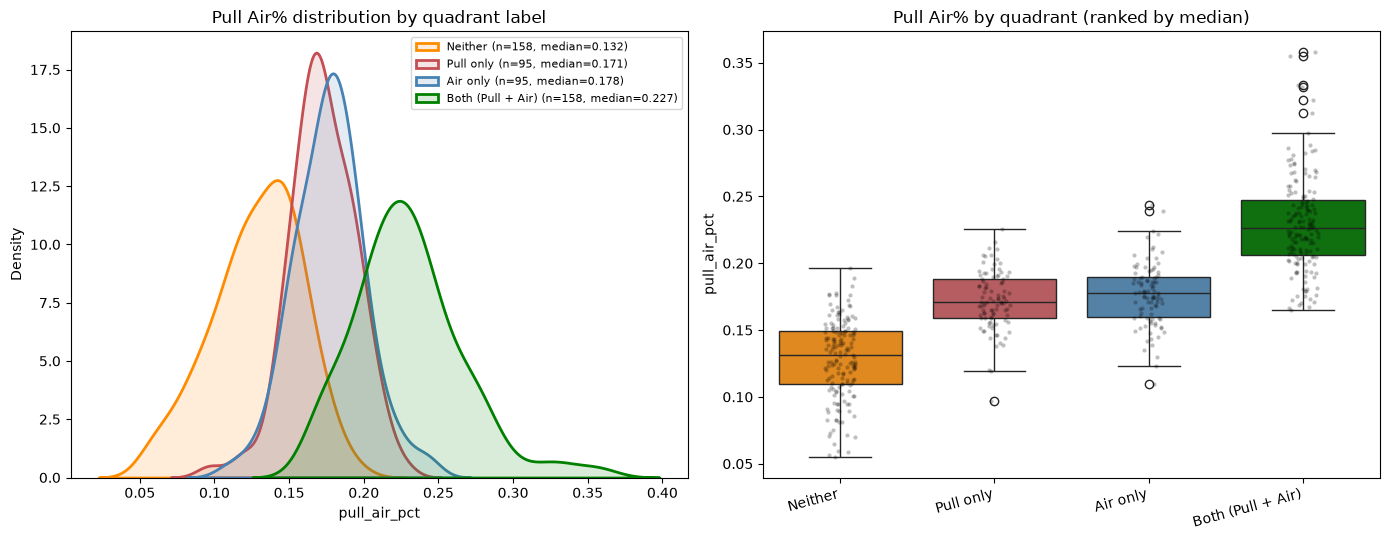

── How much does the quadrant label explain Pull Air%? ────────────────
  ANOVA:   F = 305.78, p = 7.26e-113
  Kruskal: H = 358.23, p = 2.46e-77
  η² (variance explained) = 0.646

Median Pull Air% by quadrant:
quadrant
Neither             0.1317
Pull only           0.1707
Air only            0.1775
Both (Pull + Air)   0.2266

── Pairwise overlap between adjacent quadrants (by median rank) ───────
  Neither vs Pull only:
    9/158 (5.7%) of 'Neither' hitters exceed the 'Pull only' median
    3/95 (3.2%) of 'Pull only' hitters fall below the 'Neither' median
  Pull only vs Air only:
    37/95 (38.9%) of 'Pull only' hitters exceed the 'Air only' median
    33/95 (34.7%) of 'Air only' hitters fall below the 'Pull only' median
  Air only vs Both (Pull + Air):
    2/95 (2.1%) of 'Air only' hitters exceed the 'Both (Pull + Air)' median
    11/158 (7.0%) of 'Both (Pull + Air)' hitters fall below the 'Air only' median

── Hitters within 2pp of a median cutoff (label is fragile): 230 of 506 (45.

In [15]:
# ── How well does the quadrant label match the continuous Pull Air%? ────────
from scipy.stats import f_oneway, kruskal

# (1) Distribution of pull_air_pct within each quadrant, overlaid
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for q in QUAD_ORDER:
    vals = batter_df.loc[batter_df["quadrant"] == q, "pull_air_pct"].dropna()
    sns.kdeplot(vals, ax=axes[0], color=QUAD_COLORS[q], fill=True, alpha=0.15,
                linewidth=2, label=f"{q} (n={len(vals)}, median={vals.median():.3f})")
axes[0].set_xlabel("pull_air_pct"); axes[0].set_ylabel("Density")
axes[0].set_title("Pull Air% distribution by quadrant label")
axes[0].legend(fontsize=8)

# (2) Strip/box plot, ordered by quadrant's own median
order = batter_df.groupby("quadrant")["pull_air_pct"].median().sort_values().index.tolist()
sns.boxplot(data=batter_df, x="quadrant", y="pull_air_pct", order=order,
            palette=QUAD_COLORS, ax=axes[1])
sns.stripplot(data=batter_df, x="quadrant", y="pull_air_pct", order=order,
              color="black", alpha=0.25, size=3, ax=axes[1])
axes[1].set_xlabel(""); axes[1].set_ylabel("pull_air_pct")
axes[1].set_title("Pull Air% by quadrant (ranked by median)")
axes[1].set_xticklabels(order, rotation=15, ha="right")
plt.tight_layout(); plt.show()

# (3) How much of the variance in pull_air_pct does the quadrant label explain?
groups = [batter_df.loc[batter_df["quadrant"] == q, "pull_air_pct"].dropna().values
          for q in QUAD_ORDER]
f_stat, p_anova = f_oneway(*groups)
h_stat, p_kw    = kruskal(*groups)

grand_mean = batter_df["pull_air_pct"].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total   = ((batter_df["pull_air_pct"] - grand_mean) ** 2).sum()
eta2 = ss_between / ss_total

print("── How much does the quadrant label explain Pull Air%? ────────────────")
print(f"  ANOVA:   F = {f_stat:.2f}, p = {p_anova:.3g}")
print(f"  Kruskal: H = {h_stat:.2f}, p = {p_kw:.3g}")
print(f"  η² (variance explained) = {eta2:.3f}")
print(f"\nMedian Pull Air% by quadrant:")
print(batter_df.groupby("quadrant")["pull_air_pct"].median()
      .reindex(QUAD_ORDER).round(4).to_string())

# (4) Overlap between adjacent quadrants — how often does a "lower" quadrant
#     hitter actually have HIGHER pull_air_pct than a "higher" quadrant hitter?
ranked_quads = batter_df.groupby("quadrant")["pull_air_pct"].median().sort_values().index.tolist()
print(f"\n── Pairwise overlap between adjacent quadrants (by median rank) ───────")
for i in range(len(ranked_quads) - 1):
    lo_q, hi_q = ranked_quads[i], ranked_quads[i + 1]
    lo_vals = batter_df.loc[batter_df["quadrant"] == lo_q, "pull_air_pct"].values
    hi_vals = batter_df.loc[batter_df["quadrant"] == hi_q, "pull_air_pct"].values
    # % of lo_q hitters who beat the hi_q median, and vice versa
    pct_lo_exceeds_hi_median = (lo_vals > np.median(hi_vals)).mean()
    pct_hi_below_lo_median   = (hi_vals < np.median(lo_vals)).mean()
    print(f"  {lo_q} vs {hi_q}:")
    print(f"    {(lo_vals > np.median(hi_vals)).sum()}/{len(lo_vals)} "
          f"({pct_lo_exceeds_hi_median:.1%}) of '{lo_q}' hitters exceed the "
          f"'{hi_q}' median")
    print(f"    {(hi_vals < np.median(lo_vals)).sum()}/{len(hi_vals)} "
          f"({pct_hi_below_lo_median:.1%}) of '{hi_q}' hitters fall below the "
          f"'{lo_q}' median")

# (5) Boundary-artifact check: hitters right at the median cutoffs
pull_cut = batter_df["pull_pct"].median()
air_cut  = batter_df["air_ball_pct"].median()
near_boundary = (
    (batter_df["pull_pct"].sub(pull_cut).abs() < 0.02) |
    (batter_df["air_ball_pct"].sub(air_cut).abs() < 0.02)
)
print(f"\n── Hitters within 2pp of a median cutoff (label is fragile): "
      f"{near_boundary.sum()} of {len(batter_df)} ({near_boundary.mean():.1%}) ──")
print(f"  Their Pull Air% spread: "
      f"{batter_df.loc[near_boundary, 'pull_air_pct'].std():.4f} "
      f"vs overall std {batter_df['pull_air_pct'].std():.4f}")

In [16]:
# ── Predicting Pull Air% directly from swing features ───────────────────────
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

need = ALL_FEATURES + ["pull_air_pct", "batter", "quadrant"]
reg_df = batter_df.dropna(subset=need).copy()
groups_reg = reg_df["batter"].values
gkf_reg = GroupKFold(n_splits=CV_FOLDS)

X = reg_df[ALL_FEATURES].values
y = reg_df["pull_air_pct"].values

# RF (predictive) and Linear (interpretable) side by side
pipe_rf_reg = Pipeline([("s", StandardScaler()),
                        ("m", RandomForestRegressor(
                            n_estimators=500, max_depth=8, min_samples_leaf=10,
                            random_state=SEED, n_jobs=-1))])
pipe_lr_reg = Pipeline([("s", StandardScaler()),
                        ("m", LinearRegression())])

pred_rf = cross_val_predict(pipe_rf_reg, X, y, cv=gkf_reg, groups=groups_reg)
pred_lr = cross_val_predict(pipe_lr_reg, X, y, cv=gkf_reg, groups=groups_reg)

def _report(name, pred):
    sp  = spearmanr(pred, y).correlation
    pr  = pearsonr(pred, y)[0]
    rmse = np.sqrt(np.mean((pred - y) ** 2))
    mae  = mean_absolute_error(y, pred)
    print(f"  {name:<20} Spearman={sp:+.3f}  Pearson={pr:+.3f}  "
          f"RMSE={rmse:.4f}  MAE={mae:.4f}")

print("── Predicting pull_air_pct from swing features (5-fold GroupKFold) ─────")
_report("RF (predictive)", pred_rf)
_report("Linear (interpretable)", pred_lr)

# Compare against the quadrant-label-only "model" (i.e., η² from the last check —
# predicting each hitter's pull_air_pct as their quadrant's mean)
quad_means = reg_df.groupby("quadrant")["pull_air_pct"].transform("mean")
_report("Quadrant mean (baseline)", quad_means.values)

── Predicting pull_air_pct from swing features (5-fold GroupKFold) ─────
  RF (predictive)      Spearman=+0.761  Pearson=+0.768  RMSE=0.0319  MAE=0.0247
  Linear (interpretable) Spearman=+0.815  Pearson=+0.821  RMSE=0.0285  MAE=0.0214
  Quadrant mean (baseline) Spearman=+0.831  Pearson=+0.805  RMSE=0.0296  MAE=0.0226


In [17]:
# ── What causes quadrant overlap? Identify mismatched hitters and their traits
# A "mismatch" = a hitter whose pull_air_pct is far from what their quadrant
# would predict — i.e., large residual vs their quadrant's own mean.

qd = batter_df.dropna(subset=ALL_FEATURES + ["pull_air_pct", "quadrant", "n_bbe",
                                             "pull_pct", "air_ball_pct"]).copy()

# Within-quadrant residual (z-scored so it's comparable across quadrants of
# different spread)
qd["quad_mean"] = qd.groupby("quadrant")["pull_air_pct"].transform("mean")
qd["quad_std"]  = qd.groupby("quadrant")["pull_air_pct"].transform("std")
qd["resid_z"]   = (qd["pull_air_pct"] - qd["quad_mean"]) / qd["quad_std"]

# Overachiever = high pull_air_pct relative to their quadrant's own average
# Underachiever = low pull_air_pct relative to their quadrant's own average
qd["mismatch_type"] = np.where(qd["resid_z"] >  1.0, "Overachiever",
                       np.where(qd["resid_z"] < -1.0, "Underachiever", "Matched"))

print("── Mismatch counts by type ──────────────────────────────────────────")
print(qd["mismatch_type"].value_counts().to_string())
print("\n── Mismatch counts by quadrant × type ───────────────────────────────")
print(pd.crosstab(qd["quadrant"], qd["mismatch_type"]).reindex(QUAD_ORDER).to_string())

── Mismatch counts by type ──────────────────────────────────────────
mismatch_type
Matched          347
Underachiever     77
Overachiever      72

── Mismatch counts by quadrant × type ───────────────────────────────
mismatch_type      Matched  Overachiever  Underachiever
quadrant                                               
Neither                105            23             26
Pull only               65            14             13
Air only                68            11             15
Both (Pull + Air)      109            24             23


In [18]:
# ── Candidate cause 1: boundary proximity (unstable label) ─────────────────
pull_cut = qd["pull_pct"].median()
air_cut  = qd["air_ball_pct"].median()
qd["dist_pull_boundary"] = (qd["pull_pct"]     - pull_cut).abs()
qd["dist_air_boundary"]  = (qd["air_ball_pct"] - air_cut ).abs()
qd["min_boundary_dist"]  = qd[["dist_pull_boundary", "dist_air_boundary"]].min(axis=1)

r1 = spearmanr(qd["resid_z"].abs(), qd["min_boundary_dist"]).correlation
print(f"corr(|residual|, distance to nearest median boundary) = {r1:+.3f}")
print("(negative = hitters near the boundary have BIGGER mismatches — boundary")
print(" noise is a real cause of overlap)")

# ── Candidate cause 2: sample-size reliability (n_bbe) ───────────────────────
r2 = spearmanr(qd["resid_z"].abs(), qd["n_bbe"]).correlation
print(f"\ncorr(|residual|, n_bbe) = {r2:+.3f}")
print("(negative = hitters with FEWER batted balls have noisier/bigger mismatches)")

# ── Candidate cause 3: which swing features differ between over/under-achievers
# within the SAME quadrant (controls for direction/magnitude label)?
print("\n── Feature differences: Overachievers vs Underachievers, WITHIN quadrant ──")
for q in QUAD_ORDER:
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        print(f"  {q}: too few mismatches to compare (over={len(over)}, under={len(under)})")
        continue
    print(f"\n  {q}  (over n={len(over)}, under n={len(under)})")
    for f in ALL_FEATURES:
        d = over[f].mean() - under[f].mean()
        print(f"    {f:<16} over={over[f].mean():+.3f}  under={under[f].mean():+.3f}  Δ={d:+.3f}")

corr(|residual|, distance to nearest median boundary) = +0.048
(negative = hitters near the boundary have BIGGER mismatches — boundary
 noise is a real cause of overlap)

corr(|residual|, n_bbe) = -0.030
(negative = hitters with FEWER batted balls have noisier/bigger mismatches)

── Feature differences: Overachievers vs Underachievers, WITHIN quadrant ──

  Neither  (over n=23, under n=26)
    mean_tilt        over=+30.851  under=+31.513  Δ=-0.662
    mean_aa          over=+8.131  under=+4.308  Δ=+3.823
    mean_dir         over=-0.845  under=-4.087  Δ=+3.243
    z_swing_pct      over=+0.676  under=+0.651  Δ=+0.025
    o_swing_pct      over=+0.295  under=+0.295  Δ=+0.001
    fb_swing_share   over=+0.563  under=+0.588  Δ=-0.025
    mean_length      over=+7.217  under=+6.823  Δ=+0.394
    is_L             over=+0.261  under=+0.423  Δ=-0.162

  Pull only  (over n=14, under n=13)
    mean_tilt        over=+29.309  under=+31.258  Δ=-1.949
    mean_aa          over=+9.248  under=+6.679  Δ=+2

In [19]:
# ── Feature differences: Overachievers vs Underachievers, in SD units ───────
print("── Standardized differences (Δ / pooled SD), WITHIN quadrant ──────────")
for q in QUAD_ORDER:
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        print(f"  {q}: too few mismatches to compare (over={len(over)}, under={len(under)})")
        continue

    print(f"\n  {q}  (over n={len(over)}, under n={len(under)})")
    rows = []
    for f in ALL_FEATURES:
        o, u = over[f].dropna(), under[f].dropna()
        pooled_sd = np.sqrt(((len(o) - 1) * o.var() + (len(u) - 1) * u.var())
                            / (len(o) + len(u) - 2))
        raw_d = o.mean() - u.mean()
        std_d = raw_d / pooled_sd if pooled_sd > 0 else np.nan   # Cohen's d
        rows.append({"feature": f, "over_mean": o.mean(), "under_mean": u.mean(),
                     "raw_Δ": raw_d, "pooled_SD": pooled_sd, "Δ / SD (Cohen's d)": std_d})
    tbl = pd.DataFrame(rows).sort_values("Δ / SD (Cohen's d)", key=lambda s: s.abs(),
                                         ascending=False)
    print(tbl.round(3).to_string(index=False))

── Standardized differences (Δ / pooled SD), WITHIN quadrant ──────────

  Neither  (over n=23, under n=26)
       feature  over_mean  under_mean   raw_Δ  pooled_SD  Δ / SD (Cohen's d)
       mean_aa     8.1310      4.3080  3.8230     2.5690              1.4880
      mean_dir    -0.8450     -4.0870  3.2430     2.9180              1.1110
   mean_length     7.2170      6.8230  0.3940     0.3880              1.0150
fb_swing_share     0.5630      0.5880 -0.0250     0.0400             -0.6340
   z_swing_pct     0.6760      0.6510  0.0250     0.0610              0.4120
          is_L     0.2610      0.4230 -0.1620     0.4790             -0.3390
     mean_tilt    30.8510     31.5130 -0.6620     4.0300             -0.1640
   o_swing_pct     0.2950      0.2950  0.0010     0.0640              0.0120

  Pull only  (over n=14, under n=13)
       feature  over_mean  under_mean   raw_Δ  pooled_SD  Δ / SD (Cohen's d)
      mean_dir     0.9260     -0.7420  1.6680     1.8060              0.9230
       

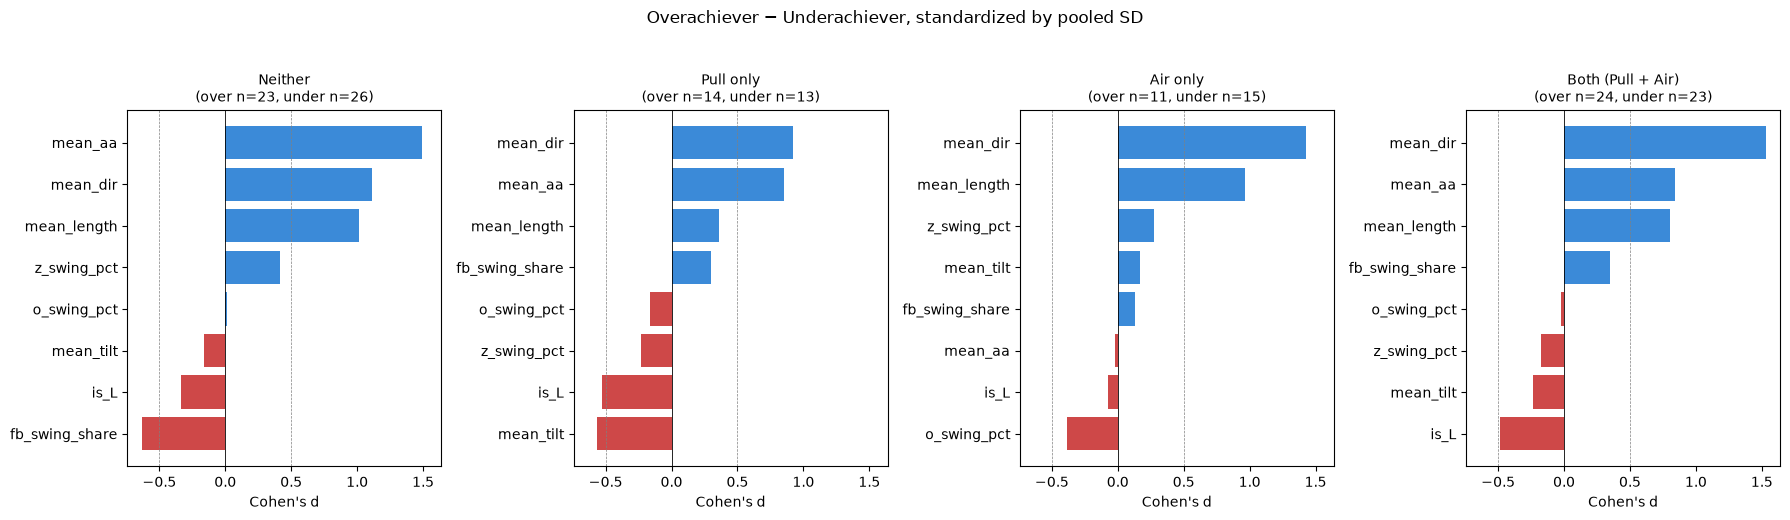

In [20]:
# ── Visual: standardized effect size by feature, one panel per quadrant ────
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharex=True)
for ax, q in zip(axes, QUAD_ORDER):
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        ax.set_title(f"{q}\n(insufficient n)")
        continue
    ds = []
    for f in ALL_FEATURES:
        o, u = over[f].dropna(), under[f].dropna()
        pooled_sd = np.sqrt(((len(o) - 1) * o.var() + (len(u) - 1) * u.var())
                            / (len(o) + len(u) - 2))
        d = (o.mean() - u.mean()) / pooled_sd if pooled_sd > 0 else 0
        ds.append(d)
    ds = pd.Series(ds, index=ALL_FEATURES).sort_values()
    colors = ["#1976D2" if v > 0 else "#C62828" for v in ds.values]
    ax.barh(ds.index, ds.values, color=colors, alpha=0.85)
    ax.axvline(0, color="black", lw=0.6)
    ax.axvline(0.5, color="gray", ls="--", lw=0.5)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.5)
    ax.set_title(f"{q}\n(over n={len(over)}, under n={len(under)})", fontsize=10)
    ax.set_xlabel("Cohen's d")
plt.suptitle("Overachiever − Underachiever, standardized by pooled SD", y=1.03)
plt.tight_layout(); plt.show()

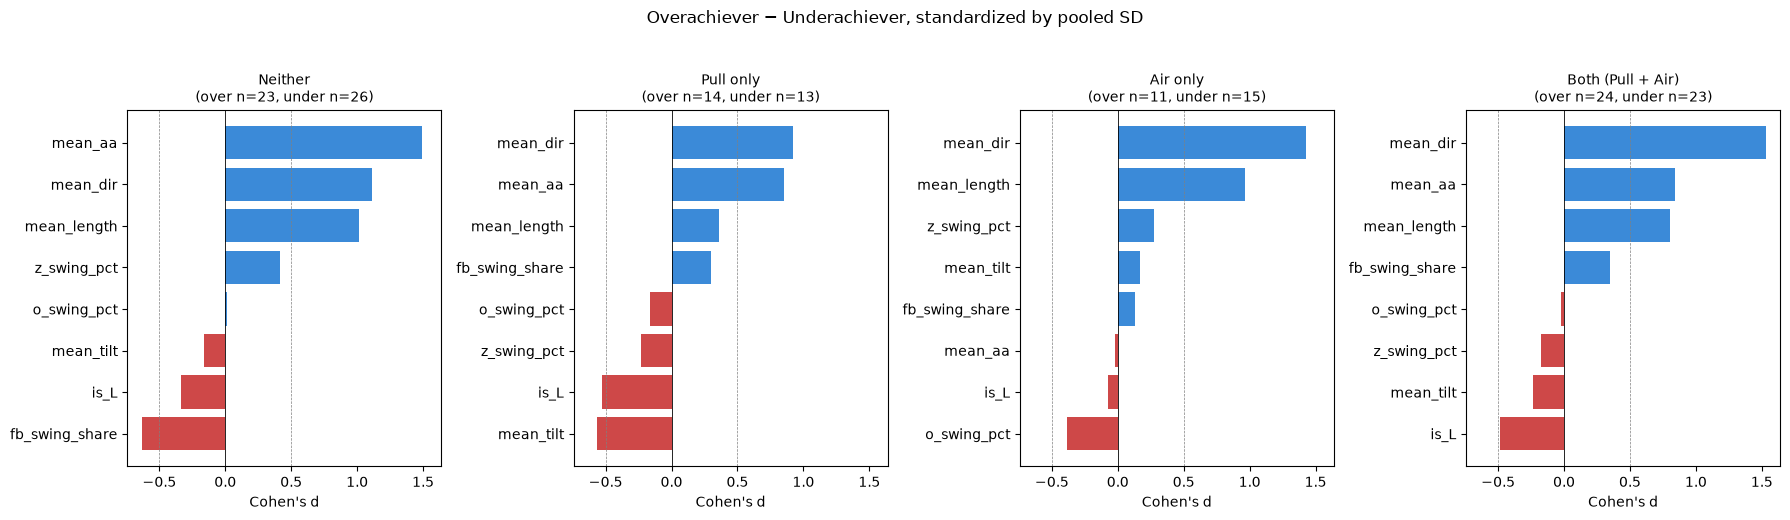

In [21]:
# ── Visual: standardized effect size by feature, one panel per quadrant ────
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharex=True)
for ax, q in zip(axes, QUAD_ORDER):
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        ax.set_title(f"{q}\n(insufficient n)")
        continue
    ds = []
    for f in ALL_FEATURES:
        o, u = over[f].dropna(), under[f].dropna()
        pooled_sd = np.sqrt(((len(o) - 1) * o.var() + (len(u) - 1) * u.var())
                            / (len(o) + len(u) - 2))
        d = (o.mean() - u.mean()) / pooled_sd if pooled_sd > 0 else 0
        ds.append(d)
    ds = pd.Series(ds, index=ALL_FEATURES).sort_values()
    colors = ["#1976D2" if v > 0 else "#C62828" for v in ds.values]
    ax.barh(ds.index, ds.values, color=colors, alpha=0.85)
    ax.axvline(0, color="black", lw=0.6)
    ax.axvline(0.5, color="gray", ls="--", lw=0.5)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.5)
    ax.set_title(f"{q}\n(over n={len(over)}, under n={len(under)})", fontsize=10)
    ax.set_xlabel("Cohen's d")
plt.suptitle("Overachiever − Underachiever, standardized by pooled SD", y=1.03)
plt.tight_layout(); plt.show()

In [22]:
# ── Mean of each feature across the four quadrants ──────────────────────────
feat_means = batter_df.groupby("quadrant")[ALL_FEATURES].mean().reindex(QUAD_ORDER)
print("── Feature means by quadrant ────────────────────────────────────────────")
print(feat_means.round(3).to_string())

# Also show sample size per quadrant alongside
n_per_quad = batter_df.groupby("quadrant").size().reindex(QUAD_ORDER).rename("n")
print("\n── n per quadrant ───────────────────────────────────────────────────────")
print(n_per_quad.to_string())

── Feature means by quadrant ────────────────────────────────────────────
                   mean_tilt  mean_aa  mean_dir  z_swing_pct  o_swing_pct  fb_swing_share  mean_length   is_L
quadrant                                                                                                     
Neither              31.5850   6.6250   -2.1720       0.6670       0.2990          0.5660       7.0860 0.2910
Pull only            30.7820   7.9440   -0.3220       0.6710       0.2900          0.5450       7.2050 0.5680
Air only             33.9860   8.7320    0.0390       0.6810       0.2900          0.5700       7.1880 0.2740
Both (Pull + Air)    32.2680  10.5460    1.3020       0.6770       0.2800          0.5520       7.2210 0.5700

── n per quadrant ───────────────────────────────────────────────────────
quadrant
Neither              158
Pull only             95
Air only              95
Both (Pull + Air)    158


In [23]:
# ── Build inner/outer swing rate at the pitch level ─────────────────────────
# Inner/outer defined relative to the batter, using plate_x + stand — same
# convention as the earlier "is_outer" feature: for a RHB, plate_x > 0 is
# away (outer); for a LHB, plate_x < 0 is away (outer). Complement = inner.

assert "raw_all" in dir(), "Need raw_all (pitch-level data) for swing rate features."

SWING_DESCS = {"hit_into_play", "swinging_strike", "foul",
               "swinging_strike_blocked", "foul_tip"}

pitches = raw_all[raw_all["batter"].notna() & raw_all["plate_x"].notna()].copy()
pitches["is_swing"] = pitches["description"].isin(SWING_DESCS).astype(int)
pitches["is_outer"] = (
    ((pitches["stand"] == "R") & (pitches["plate_x"] > 0)) |
    ((pitches["stand"] == "L") & (pitches["plate_x"] < 0))
)
pitches["is_inner"] = ~pitches["is_outer"]

swing_zone_agg = pitches.groupby("batter").apply(lambda g: pd.Series({
    "outer_swing_rate": g.loc[g["is_outer"], "is_swing"].mean() if g["is_outer"].any() else np.nan,
    "inner_swing_rate": g.loc[g["is_inner"], "is_swing"].mean() if g["is_inner"].any() else np.nan,
})).reset_index()

print(f"swing_zone_agg: {swing_zone_agg.shape}")
print(swing_zone_agg[["outer_swing_rate", "inner_swing_rate"]].describe().round(3).to_string())

swing_zone_agg: (1611, 3)
       outer_swing_rate  inner_swing_rate
count         1585.0000         1573.0000
mean             0.4500            0.5380
std              0.1870            0.2010
min              0.0000            0.0000
25%              0.3890            0.4710
50%              0.4480            0.5230
75%              0.5000            0.6000
max              1.0000            1.0000


In [24]:
# ── Merge outer/inner swing rate onto batter_df ─────────────────────────────
if "outer_swing_rate" in batter_df.columns:
    batter_df = batter_df.drop(columns=["outer_swing_rate", "inner_swing_rate"])
batter_df = batter_df.merge(swing_zone_agg, on="batter", how="left")

n_missing = batter_df["outer_swing_rate"].isna().sum()
print(f"Merged onto batter_df — missing for {n_missing} of {len(batter_df)} hitters")
print(batter_df[["outer_swing_rate", "inner_swing_rate"]].describe().round(3).to_string())

Merged onto batter_df — missing for 0 of 506 hitters
       outer_swing_rate  inner_swing_rate
count          506.0000          506.0000
mean             0.4470            0.5270
std              0.0510            0.0590
min              0.3340            0.3300
25%              0.4090            0.4900
50%              0.4470            0.5240
75%              0.4830            0.5640
max              0.6080            0.7160


In [25]:
# ── Average contact depth + ideal contact depth rate ────────────────────────
assert "depth_in" in cp.columns and "depth_in_c" in cp.columns, \
    "cp needs depth_in/depth_in_c — run the Section 2 depth-features cell first."

# ── Mean contact depth per batter (raw, uncentered — for reporting) ────────
depth_agg = cp.groupby("batter")["depth_in"].mean().rename("mean_depth").reset_index()

# ── Ideal contact depth rate: derive the "optimal" window data-drivenly from
#    the pooled depth -> pull_air rate curve, then compute each hitter's share
#    of BBE landing inside that window (within-hitter centered, so it's about
#    consistency around their own mean, not raw plate-adjusted depth). ──────
depth_bins_fit = np.linspace(cp["depth_in_c"].quantile(0.01),
                             cp["depth_in_c"].quantile(0.99), 30)
cp["_depth_bin"] = pd.cut(cp["depth_in_c"], depth_bins_fit)
pooled_curve = (cp.groupby("_depth_bin", observed=True)["pull_air_bbe"]
               .agg(["mean", "count"]))
pooled_curve = pooled_curve[pooled_curve["count"] >= 50]
bin_centers = np.array([iv.mid for iv in pooled_curve.index])
bin_rates   = pooled_curve["mean"].values

peak_rate = bin_rates.max()
peak_loc  = bin_centers[bin_rates.argmax()]
threshold = 0.90 * peak_rate
in_zone   = bin_centers[bin_rates >= threshold]
OPT_LO, OPT_HI = in_zone.min(), in_zone.max()

print(f"Pooled depth curve peak: rate={peak_rate:.3f} at depth_in_c={peak_loc:+.2f}\"")
print(f"90%-of-peak optimal window: [{OPT_LO:+.2f}, {OPT_HI:+.2f}]\"")

cp["_in_optimal_depth"] = cp["depth_in_c"].between(OPT_LO, OPT_HI).astype(int)
ideal_depth_agg = (cp.groupby("batter")["_in_optimal_depth"]
                   .mean().rename("ideal_contact_depth_rate").reset_index())

Pooled depth curve peak: rate=0.486 at depth_in_c=+11.20"
90%-of-peak optimal window: [+8.84, +13.56]"


In [26]:
# ── Merge both onto batter_df ────────────────────────────────────────────────
for col in ["mean_depth", "ideal_contact_depth_rate"]:
    if col in batter_df.columns:
        batter_df = batter_df.drop(columns=[col])

batter_df = (batter_df.merge(depth_agg, on="batter", how="left")
                      .merge(ideal_depth_agg, on="batter", how="left"))

print(f"\nMerged onto batter_df: {batter_df.shape}")
print(batter_df[["mean_depth", "ideal_contact_depth_rate"]].describe().round(3).to_string())

# Sanity check: mean_depth should correlate positively with bat speed if
# present, and quadrant ordering should roughly match the earlier F2 finding
# (Air only / Both deepest, Neither shallowest)
if "bat_speed" in cp.columns:
    r = batter_df[["mean_depth"]].join(
        cp.groupby("batter")["bat_speed"].mean()).corr().iloc[0, 1]
    print(f"\ncorr(mean_depth, bat_speed) = {r:+.3f}   (expect +)")
if "quadrant" in batter_df.columns:
    print(f"\nmean_depth by quadrant:")
    print(batter_df.groupby("quadrant")["mean_depth"].mean()
          .reindex(QUAD_ORDER).round(2).to_string())


Merged onto batter_df: (506, 25)
       mean_depth  ideal_contact_depth_rate
count    496.0000                  496.0000
mean      29.9050                    0.0770
std        3.0270                    0.0270
min       20.8330                    0.0000
25%       27.8780                    0.0650
50%       29.7500                    0.0760
75%       32.0590                    0.0880
max       38.9490                    0.5000

corr(mean_depth, bat_speed) = +nan   (expect +)

mean_depth by quadrant:
quadrant
Neither             29.1000
Pull only           29.5100
Air only            30.0900
Both (Pull + Air)   30.8200


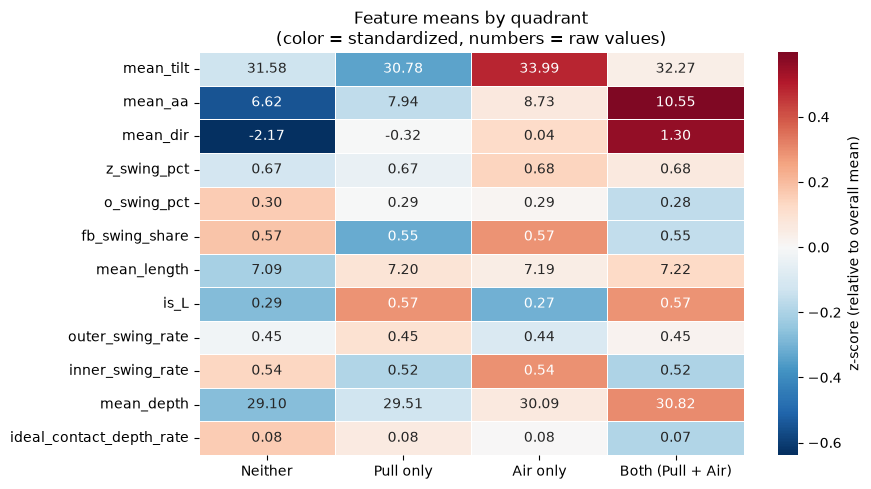

In [27]:
# ── Visual: heatmap of standardized feature means by quadrant ──────────────
# Coerce to numeric first — a mixed/object-dtype column here (common after a
# parquet round-trip or merge) silently produces an object-dtype heatmap
# array that seaborn can't render, even though it prints fine as a table.
feat_data = batter_df[ALL_FEATURES + ['outer_swing_rate'] + ['inner_swing_rate'] + ['mean_depth'] + ['ideal_contact_depth_rate']].apply(pd.to_numeric, errors="coerce")
feat_means = feat_data.groupby(batter_df["quadrant"]).mean().reindex(QUAD_ORDER)

feat_means_z = (feat_means - feat_data.mean()) / feat_data.std()

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(feat_means_z.T.values.astype(float),
            annot=feat_means.T.values.astype(float), fmt=".2f",
            cmap="RdBu_r", center=0, linewidths=0.5, linecolor="white", ax=ax,
            xticklabels=QUAD_ORDER, yticklabels=ALL_FEATURES + ['outer_swing_rate'] + ['inner_swing_rate'] + ['mean_depth'] + ['ideal_contact_depth_rate'],
            cbar_kws={"label": "z-score (relative to overall mean)"})
ax.set_title("Feature means by quadrant\n(color = standardized, numbers = raw values)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [28]:
# ── Batted-ball taxonomy: frequency and results by category ─────────────────
# Uses the same Pull/Air definitions as the rest of the thread, at the BBE level.

bb = bbe_full.copy() if "bbe_full" in dir() else cp.copy()
bb["_is_pull"] = (bb["spray_angle_norm"] < -15).astype(int)   # ±15° zone convention
bb["_is_air"]  = (bb["launch_angle"]    >= 10).astype(int)

def _bb_category(row):
    p, a = row["_is_pull"], row["_is_air"]
    if p and a:     return "Pull Air"
    if p and not a: return "Pull (non-Air)"
    if a and not p: return "Air (non-Pull)"
    return "Neither"

bb["bb_category"] = bb.apply(_bb_category, axis=1)
BB_ORDER = ["Pull Air", "Pull (non-Air)", "Air (non-Pull)", "Neither"]

print("── Batted-ball frequency by category ────────────────────────────────────")
freq = bb["bb_category"].value_counts(normalize=True).reindex(BB_ORDER)
print(freq.round(4).to_string())
print(f"\nTotal batted balls: {len(bb):,}")

── Batted-ball frequency by category ────────────────────────────────────
bb_category
Pull Air         0.1807
Pull (non-Air)   0.2633
Air (non-Pull)   0.3844
Neither          0.1715

Total batted balls: 283,131


In [29]:
# ── Batted-ball taxonomy: Pull / Center / Oppo split at ±15°, crossed with Air ─
bb = bbe_full.copy() if "bbe_full" in dir() else cp.copy()

PULL_CUTOFF = 15   # spray_angle_norm > +15 = Pull, < -15 = Oppo, between = Center

def _direction_zone(angle):
    if angle > PULL_CUTOFF:
        return "Oppo"     # was "Pull"
    elif angle < -PULL_CUTOFF:
        return "Pull"     # was "Oppo"
    else:
        return "Center"

bb["direction_zone"] = bb["spray_angle_norm"].apply(_direction_zone)
bb["_is_air"] = (bb["launch_angle"] >= 10).astype(int)

def _bb_category(row):
    zone, air = row["direction_zone"], row["_is_air"]
    if zone == "Pull"   and air: return "Pull Air"
    if zone == "Pull"   and not air: return "Pull (non-Air)"
    if zone == "Center" and air: return "Center Air"
    if zone == "Center" and not air: return "Center (non-Air)"
    if zone == "Oppo"   and air: return "Oppo Air"
    if zone == "Oppo"   and not air: return "Oppo (non-Air)"

bb["bb_category"] = bb.apply(_bb_category, axis=1)
BB_ORDER = ["Pull Air", "Pull (non-Air)", "Center Air", "Center (non-Air)",
           "Oppo Air", "Oppo (non-Air)"]

print("── Batted-ball frequency by category (Pull/Center/Oppo × Air) ──────────")
freq = bb["bb_category"].value_counts(normalize=True).reindex(BB_ORDER)
print(freq.round(4).to_string())
print(f"\nTotal batted balls: {len(bb):,}")

print("\n── Direction zone alone ──────────────────────────────────────────────")
print(bb["direction_zone"].value_counts(normalize=True).reindex(["Pull","Center","Oppo"]).round(4).to_string())

── Batted-ball frequency by category (Pull/Center/Oppo × Air) ──────────
bb_category
Pull Air           0.1807
Pull (non-Air)     0.2633
Center Air         0.1839
Center (non-Air)   0.1022
Oppo Air           0.2005
Oppo (non-Air)     0.0693

Total batted balls: 283,131

── Direction zone alone ──────────────────────────────────────────────
direction_zone
Pull     0.4441
Center   0.2862
Oppo     0.2697


In [30]:
# ── Results by category ──────────────────────────────────────────────────
HIT_EVENTS = {"single", "double", "triple", "home_run"}
OUT_EVENTS = {"field_out", "force_out", "grounded_into_double_play", "double_play",
             "fielders_choice_out", "sac_fly", "sac_bunt", "triple_play"}

bb_res = bb[bb["events"].notna()].copy()
bb_res["is_hit"]  = bb_res["events"].isin(HIT_EVENTS).astype(int)
bb_res["bases"]   = bb_res["events"].map({
    "single": 1, "double": 2, "triple": 3, "home_run": 4}).fillna(0)
bb_res["at_bat"]  = bb_res["events"].isin(HIT_EVENTS | OUT_EVENTS).astype(int)
bb_res["hard_hit"] = (bb_res["launch_speed"] >= 95).astype(int)

def _results_by_category(df, cats):
    rows = []
    for cat in cats:
        sub_c = df[df["bb_category"] == cat]
        n = len(sub_c)
        row = {"category": cat, "n": n, "share_of_BBE": n / len(df)}
        row["AVG"] = sub_c.loc[sub_c["at_bat"] == 1, "is_hit"].mean()
        row["SLG"] = sub_c.loc[sub_c["at_bat"] == 1, "bases"].mean()
        row["mean_exit_velo"] = sub_c["launch_speed"].mean()
        row["hard_hit_rate"]  = sub_c["hard_hit"].mean()
        if {"woba_value", "woba_denom"}.issubset(sub_c.columns):
            wd = sub_c.loc[sub_c["woba_denom"] > 0]
            row["wOBA"] = wd["woba_value"].sum() / wd["woba_denom"].sum() if len(wd) else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

results_tbl = _results_by_category(bb_res, BB_ORDER)
print("── Results by batted-ball category ─────────────────────────────────────")
print(results_tbl.round(3).to_string(index=False))

── Results by batted-ball category ─────────────────────────────────────
        category     n  share_of_BBE    AVG    SLG  mean_exit_velo  hard_hit_rate   wOBA
        Pull Air 51175        0.1810 0.5210 1.1810         92.4800         0.5060 0.7090
  Pull (non-Air) 74561        0.2630 0.2100 0.2450         86.9920         0.3550 0.2210
      Center Air 52079        0.1840 0.3200 0.5510         91.1750         0.4560 0.3720
Center (non-Air) 28947        0.1020 0.3410 0.3520         88.2510         0.4390 0.3230
        Oppo Air 56757        0.2000 0.2570 0.4240         86.1100         0.2510 0.2930
  Oppo (non-Air) 19612        0.0690 0.3740 0.4130         82.8590         0.3480 0.3660


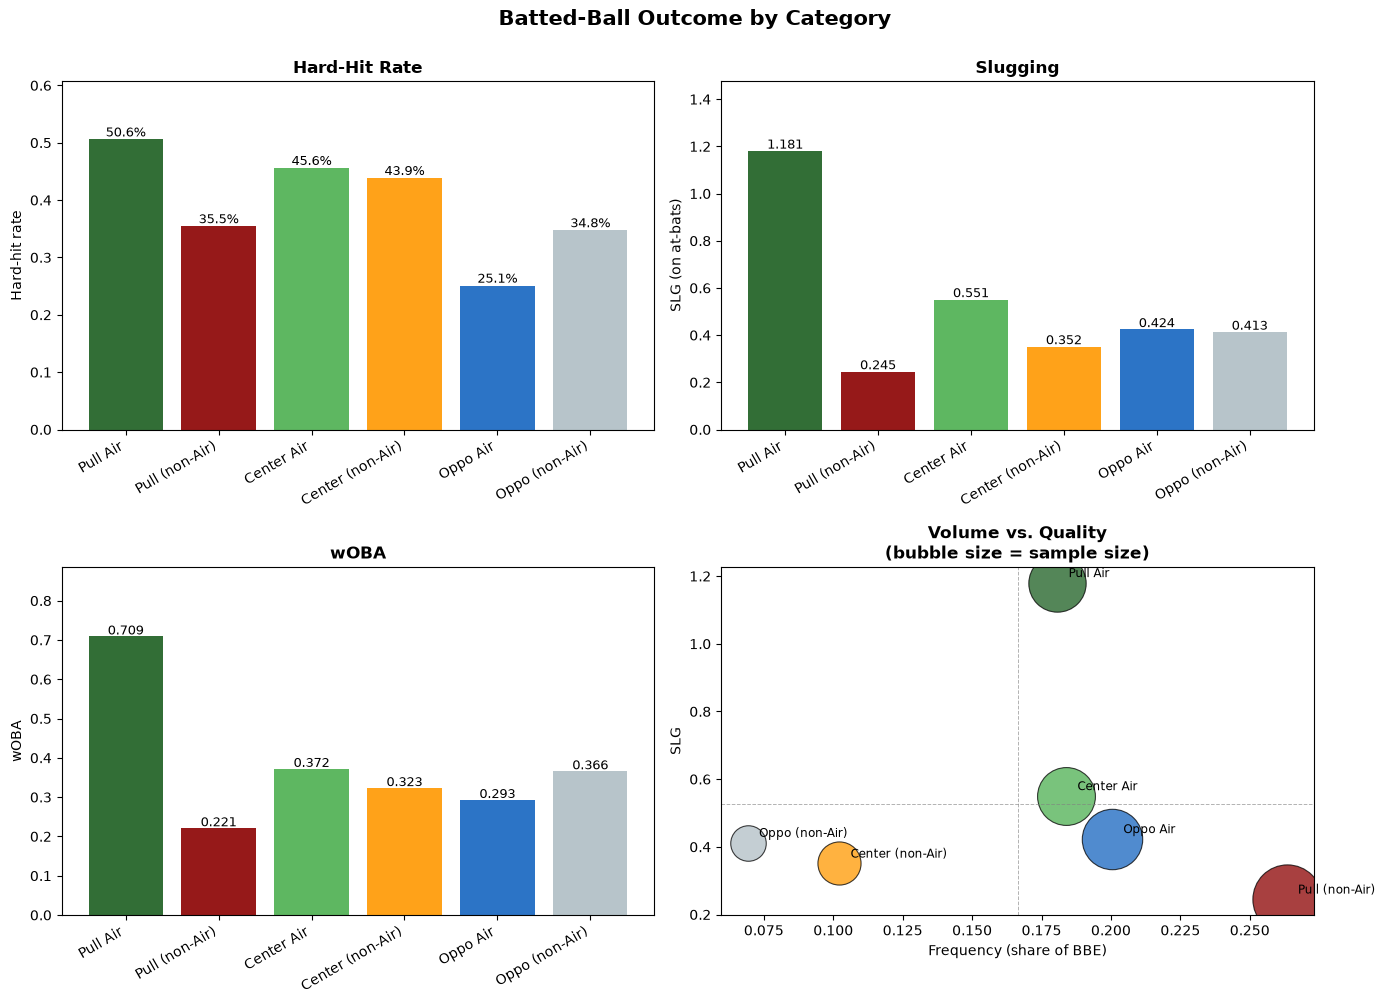

In [31]:
# ── Polished visual: batted-ball category results dashboard ────────────────
cat_colors = {
    "Pull Air": "#1B5E20", "Pull (non-Air)": "#8B0000",
    "Center Air": "#4CAF50", "Center (non-Air)": "#FF9800",
    "Oppo Air": "#1565C0", "Oppo (non-Air)": "#B0BEC5",
    "Air (non-Pull)": "#1565C0", "Neither": "#9E9E9E",  # fallback for 4-category version
}
colors = [cat_colors.get(c, "#607D8B") for c in results_tbl["category"]]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) Frequency
ax = axes[0, 0]
bars = ax.bar(results_tbl["category"], results_tbl["hard_hit_rate"], color=colors, alpha=0.9)
for b, v in zip(bars, results_tbl["hard_hit_rate"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.005, f"{v:.1%}", ha="center", fontsize=9)
ax.set_ylabel("Hard-hit rate")
ax.set_title("Hard-Hit Rate", fontsize=12, fontweight="bold")
ax.set_xticklabels(results_tbl["category"], rotation=30, ha="right")
ax.set_ylim(0, results_tbl["hard_hit_rate"].max() * 1.2)

# (2) SLG
ax = axes[0, 1]
bars = ax.bar(results_tbl["category"], results_tbl["SLG"], color=colors, alpha=0.9)
for b, v in zip(bars, results_tbl["SLG"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("SLG (on at-bats)")
ax.set_title("Slugging", fontsize=12, fontweight="bold")
ax.set_xticklabels(results_tbl["category"], rotation=30, ha="right")
ax.set_ylim(0, results_tbl["SLG"].max() * 1.25)

# (3) wOBA (falls back to hard-hit rate if wOBA unavailable)
ax = axes[1, 0]
metric = "wOBA" if "wOBA" in results_tbl.columns else "hard_hit_rate"
bars = ax.bar(results_tbl["category"], results_tbl[metric], color=colors, alpha=0.9)
for b, v in zip(bars, results_tbl[metric]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel(metric)
ax.set_title(metric, fontsize=12, fontweight="bold")
ax.set_xticklabels(results_tbl["category"], rotation=30, ha="right")
ax.set_ylim(0, results_tbl[metric].max() * 1.25)

# (4) Combined view: frequency (x) vs SLG (y), bubble size = n, labeled
ax = axes[1, 1]
for _, row in results_tbl.iterrows():
    c = cat_colors.get(row["category"], "#607D8B")
    ax.scatter(row["share_of_BBE"], row["SLG"], s=row["n"] / 30,
               color=c, alpha=0.75, edgecolor="black", linewidth=0.8)
    ax.annotate(row["category"], (row["share_of_BBE"], row["SLG"]),
                textcoords="offset points", xytext=(8, 4), fontsize=8.5)
ax.axhline(results_tbl["SLG"].mean(), color="gray", ls="--", lw=0.7, alpha=0.6)
ax.axvline(results_tbl["share_of_BBE"].mean(), color="gray", ls="--", lw=0.7, alpha=0.6)
ax.set_xlabel("Frequency (share of BBE)")
ax.set_ylabel("SLG")
ax.set_title("Volume vs. Quality\n(bubble size = sample size)", fontsize=12, fontweight="bold")

plt.suptitle("Batted-Ball Outcome by Category", fontsize=15, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()

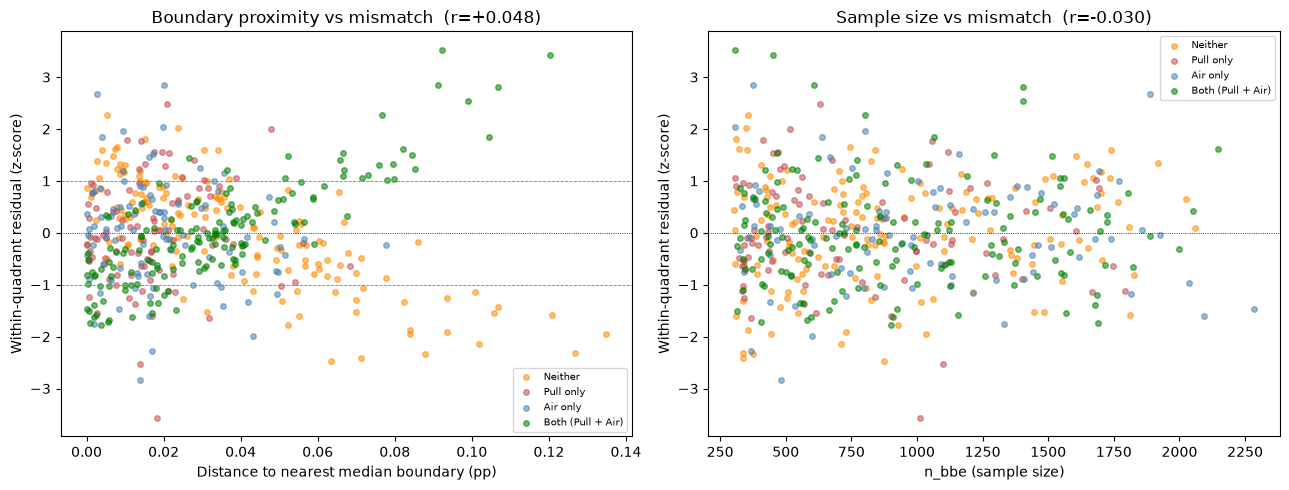

── Top 10 overachievers (highest positive residual) ────────────────────
 batter          quadrant  pull_air_pct  quad_mean  resid_z  n_bbe  min_boundary_dist
 572761 Both (Pull + Air)        0.3580     0.2300   3.5270    307             0.0920
 608336 Both (Pull + Air)        0.3550     0.2300   3.4300    451             0.1200
 474832          Air only        0.2430     0.1760   2.8550    374             0.0200
 594807 Both (Pull + Air)        0.3330     0.2300   2.8420    606             0.0910
 670623 Both (Pull + Air)        0.3320     0.2300   2.8030   1404             0.1070
 605141          Air only        0.2390     0.1760   2.6710   1887             0.0030
 663728 Both (Pull + Air)        0.3220     0.2300   2.5420   1402             0.0990
 518792         Pull only        0.2260     0.1730   2.4830    629             0.0210
 643376 Both (Pull + Air)        0.3130     0.2300   2.2720    803             0.0770
 605113           Neither        0.1960     0.1290   2.2620    357 

In [32]:
# ── Visual: residual vs boundary distance and n_bbe ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for q in QUAD_ORDER:
    m = qd["quadrant"] == q
    axes[0].scatter(qd.loc[m, "min_boundary_dist"], qd.loc[m, "resid_z"],
                    s=16, alpha=0.55, color=QUAD_COLORS[q], label=q)
axes[0].axhline(0, color="black", lw=0.6, ls=":")
axes[0].axhline(1, color="gray", lw=0.6, ls="--")
axes[0].axhline(-1, color="gray", lw=0.6, ls="--")
axes[0].set_xlabel("Distance to nearest median boundary (pp)")
axes[0].set_ylabel("Within-quadrant residual (z-score)")
axes[0].set_title(f"Boundary proximity vs mismatch  (r={r1:+.3f})")
axes[0].legend(fontsize=7)

for q in QUAD_ORDER:
    m = qd["quadrant"] == q
    axes[1].scatter(qd.loc[m, "n_bbe"], qd.loc[m, "resid_z"],
                    s=16, alpha=0.55, color=QUAD_COLORS[q], label=q)
axes[1].axhline(0, color="black", lw=0.6, ls=":")
axes[1].set_xlabel("n_bbe (sample size)")
axes[1].set_ylabel("Within-quadrant residual (z-score)")
axes[1].set_title(f"Sample size vs mismatch  (r={r2:+.3f})")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# Top mismatched hitters, for spot-checking
print("── Top 10 overachievers (highest positive residual) ────────────────────")
print(qd.sort_values("resid_z", ascending=False)
      [["batter", "quadrant", "pull_air_pct", "quad_mean", "resid_z", "n_bbe",
        "min_boundary_dist"]].head(10).round(3).to_string(index=False))

print("\n── Top 10 underachievers (most negative residual) ──────────────────────")
print(qd.sort_values("resid_z")
      [["batter", "quadrant", "pull_air_pct", "quad_mean", "resid_z", "n_bbe",
        "min_boundary_dist"]].head(10).round(3).to_string(index=False))

In [33]:
# ══ Rules-based classifier + effect-size-selected within-quadrant regression ══
# Stage 1: rules-based direction/tilt classifier (Gaussian likelihood, cross-validated).
# Stage 2: within each predicted bucket, regress on ONLY the features whose
#          standardized effect size (|Cohen's d|) cleared 0.5 in that quadrant's
#          over/underachiever analysis — a parsimonious, small-sample-safe
#          alternative to using all 7 features per bucket.

from scipy.stats import multivariate_normal

rb = batter_df.dropna(subset=ALL_FEATURES + ["pull_air_pct", "batter", "quadrant"]).copy()
groups_rb = rb["batter"].values
gkf_rb    = GroupKFold(n_splits=CV_FOLDS)
DIR_FEATS = ["mean_aa", "mean_dir"]

def _dir_group(q):
    if q == "Pull only": return "pull"
    if q == "Air only":  return "air"
    return "blend"
rb["dir_group"] = rb["quadrant"].map(_dir_group)

def _fit_rules(train_df):
    params = {}
    for g in ["pull", "air", "blend"]:
        x = train_df.loc[train_df["dir_group"] == g, DIR_FEATS].dropna().values.astype(np.float64)
        if len(x) < 2:
            x = train_df[DIR_FEATS].dropna().values.astype(np.float64)
        params[g] = {"mean": x.mean(axis=0),
                     "cov": np.cov(x.T) + np.eye(2) * 1e-3,
                     "prior": len(x) / len(train_df)}
    tilt_med = train_df.loc[train_df["dir_group"] == "blend", "mean_tilt"].median()
    return params, tilt_med

def _apply_rules(test_df, params, tilt_med):
    X_dir = test_df[DIR_FEATS].values
    liks = np.column_stack([
        multivariate_normal.logpdf(X_dir, mean=params[g]["mean"], cov=params[g]["cov"])
        + np.log(params[g]["prior"]) for g in ["pull", "air", "blend"]])
    pred_dir = np.array(["pull", "air", "blend"])[liks.argmax(axis=1)]
    tilt = test_df["mean_tilt"].values
    return np.where(pred_dir == "pull", "Pull only",
           np.where(pred_dir == "air",  "Air only",
           np.where(tilt >= tilt_med,   "Both (Pull + Air)", "Neither")))

pred_rules_rb = np.empty(len(rb), dtype=object)
for train_idx, test_idx in gkf_rb.split(rb, rb["quadrant"], groups_rb):
    params, tilt_med = _fit_rules(rb.iloc[train_idx])
    pred_rules_rb[test_idx] = _apply_rules(rb.iloc[test_idx], params, tilt_med)
rb["pred_quadrant_rules"] = pred_rules_rb

kap_rules_rb = cohen_kappa_score(rb["quadrant"], pred_rules_rb)
print(f"Stage 1 (rules-based) κ = {kap_rules_rb:.4f}")

Stage 1 (rules-based) κ = 0.0472


In [34]:
from sklearn.linear_model import Ridge, LinearRegression

In [35]:
# ── Feature selection by |Cohen's d| >= 0.5, from your mismatch analysis ────
SELECTED_FEATS = {
    "Neither":            ["mean_dir", "mean_tilt"],                       # d = 1.14, 1.12
    "Pull only":          ["mean_tilt"],                                    # d = 0.76
    "Air only":           ["mean_dir", "mean_tilt", "z_swing_pct"],         # d = 1.42, 1.33, 0.69
    "Both (Pull + Air)":  ["z_swing_pct", "is_L", "mean_tilt"],             # d = -0.94, -0.78, 0.69
}
# Optional: rebuild this dict from your actual per-quadrant Cohen's d table
# instead of hardcoding, to stay tied to whatever the data shows:
#
# selected = {}
# for q in QUAD_ORDER:
#     d_tbl = <your standardized-difference table for q>
#     selected[q] = d_tbl.loc[d_tbl["Δ / SD (Cohen's d)"].abs() >= 0.5, "feature"].tolist()

def _two_stage(feat_map, model="ridge", min_n=15):
    pred = np.full(len(rb), np.nan)
    for q in QUAD_ORDER:
        mask  = rb["pred_quadrant_rules"].values == q
        sub_q = rb.loc[mask]
        feats = feat_map[q] if isinstance(feat_map, dict) else feat_map
        if len(sub_q) < min_n:
            pred[mask] = sub_q["pull_air_pct"].mean()
            continue
        n_folds = min(CV_FOLDS, sub_q["batter"].nunique())
        gkf_q = GroupKFold(n_splits=n_folds)
        pipe = Pipeline([("s", StandardScaler()),
                         ("m", Ridge(alpha=1.0) if model == "ridge" else LinearRegression())])
        pred[mask] = cross_val_predict(pipe, sub_q[feats].values, sub_q["pull_air_pct"].values,
                                       cv=gkf_q, groups=sub_q["batter"].values)
    return pred

pred_selected = _two_stage(SELECTED_FEATS, "ridge")
pred_allfeats = _two_stage(ALL_FEATURES,   "ridge")   # comparison: full feature set

sp_sel = spearmanr(pred_selected, rb["pull_air_pct"]).correlation
sp_all = spearmanr(pred_allfeats, rb["pull_air_pct"]).correlation
print(f"\n── Rules-based Stage 1 + Stage 2 comparison ─────────────────────────────")
print(f"  Effect-size-selected features (parsimonious):  Spearman = {sp_sel:+.4f}")
print(f"  All 7 features per bucket:                      Spearman = {sp_all:+.4f}")

print(f"\n── Per-true-quadrant Spearman ────────────────────────────────────────")
for q in QUAD_ORDER:
    m = rb["quadrant"].values == q
    if m.sum() < 10: continue
    sp_s = spearmanr(pred_selected[m], rb.loc[m, "pull_air_pct"]).correlation
    sp_a = spearmanr(pred_allfeats[m], rb.loc[m, "pull_air_pct"]).correlation
    print(f"  {q:<20}  selected={sp_s:+.3f}  all-features={sp_a:+.3f}  "
          f"Δ={sp_s-sp_a:+.3f}  n_feats_selected={len(SELECTED_FEATS[q])}")


── Rules-based Stage 1 + Stage 2 comparison ─────────────────────────────
  Effect-size-selected features (parsimonious):  Spearman = +0.4312
  All 7 features per bucket:                      Spearman = +0.8185

── Per-true-quadrant Spearman ────────────────────────────────────────
  Neither               selected=+0.279  all-features=+0.634  Δ=-0.356  n_feats_selected=2
  Pull only             selected=+0.250  all-features=+0.464  Δ=-0.214  n_feats_selected=1
  Air only              selected=-0.033  all-features=+0.510  Δ=-0.543  n_feats_selected=3
  Both (Pull + Air)     selected=+0.211  all-features=+0.685  Δ=-0.474  n_feats_selected=3


In [36]:
# ── Load 2022–2025 Statcast parquets directly from the notebook's folder ────
from pathlib import Path

SEASONS_FULL = [2022, 2023, 2024, 2025]
NOTEBOOK_DIR = Path(".")   # same folder as the notebook

season_frames = []
for y in SEASONS_FULL:
    f = NOTEBOOK_DIR / f"statcast_{y}.parquet"
    if f.exists():
        df_y = pd.read_parquet(f)
        season_frames.append(df_y)
        print(f"Loaded {f.name}: {df_y.shape}")
    else:
        print(f"Missing: {f.name} — skipping {y}")

raw_all_full = pd.concat(season_frames, ignore_index=True)
print(f"\nraw_all_full: {raw_all_full.shape}")
print(f"Seasons present: {sorted(pd.to_datetime(raw_all_full['game_date']).dt.year.unique())}")

Loaded statcast_2022.parquet: (710210, 119)
Loaded statcast_2023.parquet: (720684, 119)
Loaded statcast_2024.parquet: (731904, 118)
Loaded statcast_2025.parquet: (734846, 118)

raw_all_full: (2897644, 119)
Seasons present: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [37]:
# ── Rebuild the BBE frame across all seasons ────────────────────────────────
# pull_air only needs hc_x, hc_y, launch_angle, stand — all core fields, present
# in every Statcast season (unlike swing_path_tilt/attack_angle/bat_speed,
# which are bat-tracking-era only, 2024+). So this covers 2022-2025 fine.

bbe_full = raw_all_full[
    raw_all_full["description"].isin(["hit_into_play"]) &
    raw_all_full["launch_speed"].notna() &
    raw_all_full["launch_angle"].notna() &
    raw_all_full["hc_x"].notna() & raw_all_full["hc_y"].notna() &
    raw_all_full["stand"].notna() & raw_all_full["batter"].notna()
].copy()

bbe_full["spray_angle_norm"] = np.where(
    bbe_full["stand"] == "R",
     np.degrees(np.arctan((bbe_full["hc_x"] - 125.42) / (198.27 - bbe_full["hc_y"]))),
    -np.degrees(np.arctan((bbe_full["hc_x"] - 125.42) / (198.27 - bbe_full["hc_y"]))),
)
bbe_full["pull_air"] = ((bbe_full["spray_angle_norm"] < -15) &   # ±15° zone convention
                        (bbe_full["launch_angle"]     >= 10)).astype(int)
bbe_full["season"] = pd.to_datetime(bbe_full["game_date"]).dt.year

print(f"bbe_full: {bbe_full.shape}")
print(bbe_full["season"].value_counts().sort_index().to_string())

bbe_full: (500208, 122)
season
2022    123678
2023    123820
2024    125749
2025    126961


In [38]:
MIN_BBE = 150

In [39]:
# ── Season-level aggregation across all 4 years ─────────────────────────────
season_agg = (bbe_full.groupby(["batter", "season"])
             .agg(n_bbe=("pull_air", "count"), pull_air_pct=("pull_air", "mean"))
             .reset_index())
season_agg = season_agg[season_agg["n_bbe"] >= MIN_BBE]
print(f"Batter-seasons with ≥{MIN_BBE} BBE: {len(season_agg)}")
print(season_agg["season"].value_counts().sort_index().to_string())

# ── Build all consecutive-season pairs: 2022→23, 2023→24, 2024→25 ──────────
seasons_sorted = sorted(season_agg["season"].unique())
pairs = []
for s in seasons_sorted[:-1]:
    y1 = season_agg[season_agg["season"] == s][["batter", "pull_air_pct"]].rename(
        columns={"pull_air_pct": "pa_y1"})
    y2 = season_agg[season_agg["season"] == s + 1][["batter", "pull_air_pct"]].rename(
        columns={"pull_air_pct": "pa_y2"})
    merged = y1.merge(y2, on="batter")
    merged["season_pair"] = f"{s}→{s+1}"
    pairs.append(merged)
stick = pd.concat(pairs, ignore_index=True)
print(f"\nTotal consecutive-season pairs: {len(stick)}")
print(stick["season_pair"].value_counts().to_string())

Batter-seasons with ≥150 BBE: 1348
season
2022    333
2023    342
2024    346
2025    327

Total consecutive-season pairs: 749
season_pair
2023→2024    260
2024→2025    245
2022→2023    244


In [40]:
# ── Stickiness by pair and pooled ────────────────────────────────────────────
print("── Pull Air% year-over-year stickiness (all pairs, 2022-2025) ──────────")
for sp_name, g in stick.groupby("season_pair"):
    r = spearmanr(g["pa_y1"], g["pa_y2"]).correlation
    print(f"  {sp_name}: n={len(g)}, Spearman={r:.3f}")

r_pooled = spearmanr(stick["pa_y1"], stick["pa_y2"]).correlation
sb = 2 * r_pooled / (1 + r_pooled)
print(f"  Pooled across all pairs: n={len(stick)}, Spearman={r_pooled:.3f}")
print(f"  Spearman-Brown reliability estimate ≈ {sb:.3f}")

── Pull Air% year-over-year stickiness (all pairs, 2022-2025) ──────────
  2022→2023: n=244, Spearman=0.713
  2023→2024: n=260, Spearman=0.708
  2024→2025: n=245, Spearman=0.751
  Pooled across all pairs: n=749, Spearman=0.726
  Spearman-Brown reliability estimate ≈ 0.841


In [41]:
# Check whether the 2023→24 spike is a sample-size or league-shift artifact
print("── Mean n_bbe and pull_air_pct by season ────────────────────────────────")
print(season_agg.groupby("season").agg(
    n_hitters=("batter", "count"),
    mean_n_bbe=("n_bbe", "mean"),
    mean_pull_air_pct=("pull_air_pct", "mean"),
    std_pull_air_pct=("pull_air_pct", "std")
).round(3).to_string())

── Mean n_bbe and pull_air_pct by season ────────────────────────────────
        n_hitters  mean_n_bbe  mean_pull_air_pct  std_pull_air_pct
season                                                            
2022          333    313.2250             0.1710            0.0550
2023          342    310.8570             0.1780            0.0540
2024          346    314.4860             0.1810            0.0550
2025          327    326.8350             0.1840            0.0560


── Pooled quintile transition matrix (row = Year N, col = Year N+1) ────
q_y2       Q1 (low)     Q2     Q3     Q4  Q5 (high)
q_y1                                               
Q1 (low)     0.5670 0.2530 0.1130 0.0530     0.0130
Q2           0.2670 0.3200 0.2530 0.1200     0.0400
Q3           0.1070 0.2680 0.3150 0.2150     0.0940
Q4           0.0530 0.1330 0.2400 0.3670     0.2070
Q5 (high)    0.0070 0.0270 0.0730 0.2470     0.6470

Average 'stayed in same quintile' rate: 44.3%  (vs 20% random)


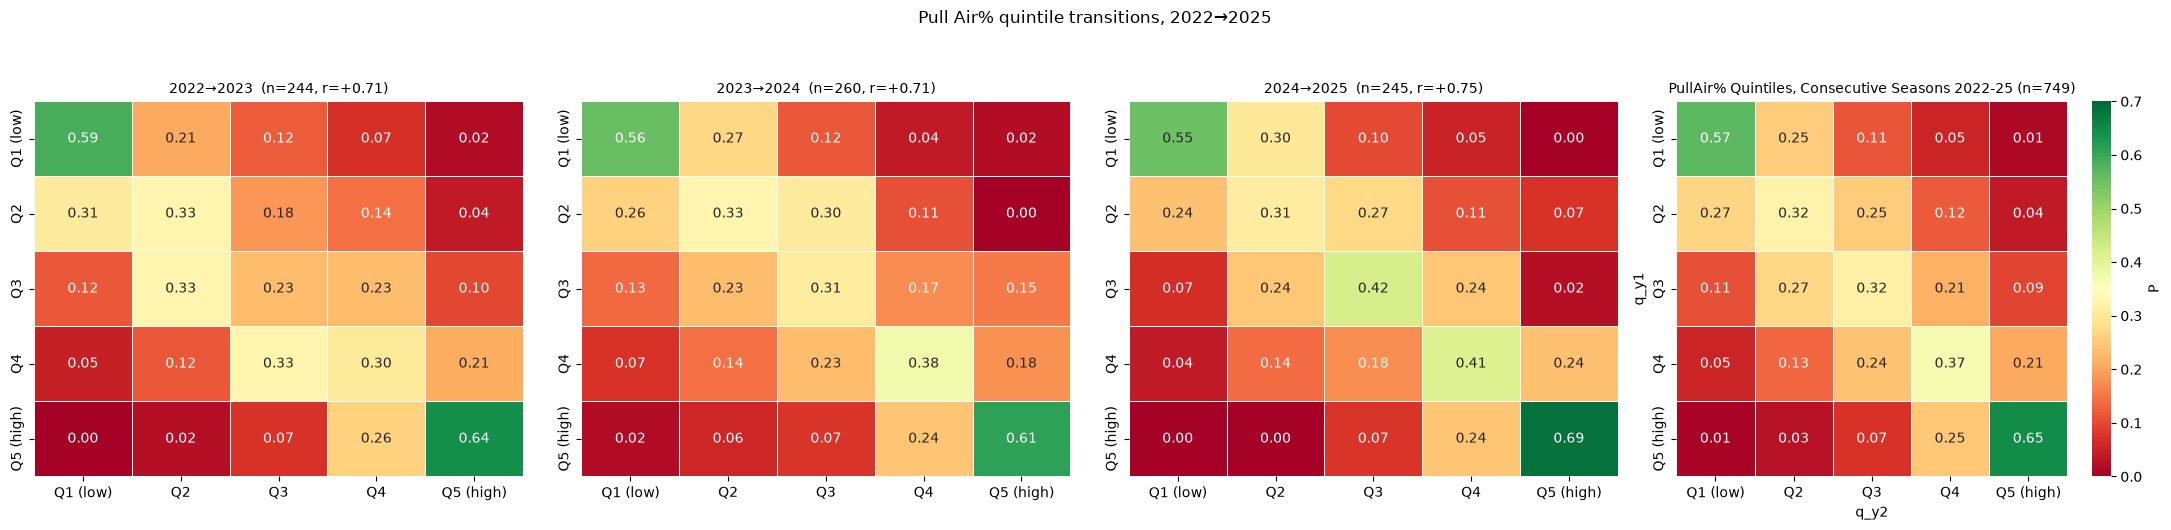

In [42]:
# ── Quintile transition matrix — pooled and per-pair ────────────────────────
stick["q_y1"] = pd.qcut(stick["pa_y1"], 5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])
stick["q_y2"] = pd.qcut(stick["pa_y2"], 5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])

trans_pooled = pd.crosstab(stick["q_y1"], stick["q_y2"], normalize="index")
print("── Pooled quintile transition matrix (row = Year N, col = Year N+1) ────")
print(trans_pooled.round(3).to_string())
diag_pct = np.diag(trans_pooled.values).mean()
print(f"\nAverage 'stayed in same quintile' rate: {diag_pct:.1%}  (vs 20% random)")

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (name, g) in zip(axes[:3], stick.groupby("season_pair")):
    t = pd.crosstab(g["q_y1"], g["q_y2"], normalize="index")
    sns.heatmap(t, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=0.7,
                linewidths=0.5, linecolor="white", ax=ax, cbar=False)
    r = spearmanr(g["pa_y1"], g["pa_y2"]).correlation
    ax.set_title(f"{name}  (n={len(g)}, r={r:+.2f})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
sns.heatmap(trans_pooled, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=0.7,
            linewidths=0.5, linecolor="white", ax=axes[3], cbar_kws={"label": "P"})
axes[3].set_title(f"PullAir% Quintiles, Consecutive Seasons 2022-25 (n={len(stick)})", fontsize=10)
plt.suptitle("Pull Air% quintile transitions, 2022→2025", y=1.05)
plt.tight_layout(); plt.show()

In [43]:
# ── Multi-season transition paths (3+ consecutive seasons) ──────────────────
# Assign each batter-season a quintile using THAT SEASON's own cutoffs
# (so "Q5" always means "top 20% of that specific year," not pooled).
season_agg["quintile"] = season_agg.groupby("season")["pull_air_pct"].transform(
    lambda s: pd.qcut(s, 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]))

wide = season_agg.pivot(index="batter", columns="season", values="quintile")
seasons_sorted = sorted(season_agg["season"].unique())

def _longest_consecutive_run(row):
    present = [s for s in seasons_sorted if pd.notna(row[s])]
    if not present:
        return []
    runs, cur = [], [present[0]]
    for s in present[1:]:
        if s == cur[-1] + 1:
            cur.append(s)
        else:
            runs.append(cur)
            cur = [s]
    runs.append(cur)
    return max(runs, key=len)

wide["run"]     = wide.apply(_longest_consecutive_run, axis=1)
wide["run_len"] = wide["run"].apply(len)

multi = wide[wide["run_len"] >= 3].copy()
print(f"Batters with a 3+ consecutive-season run: {len(multi)}")
print(f"  Run-length distribution:")
print(multi["run_len"].value_counts().sort_index().to_string())

multi["path"] = multi.apply(lambda r: tuple(r[s] for s in r["run"]), axis=1)
path_counts = multi["path"].value_counts()

print(f"\n── Top 20 most common {seasons_sorted[0]}–{seasons_sorted[-1]} transition paths ──")
print(path_counts.head(20).to_string())

Batters with a 3+ consecutive-season run: 243
  Run-length distribution:
run_len
3     93
4    150

── Top 20 most common 2022–2025 transition paths ──
path
(Q5, Q5, Q5, Q5)    18
(Q1, Q1, Q1, Q1)     8
(Q1, Q1, Q1)         6
(Q5, Q5, Q5)         5
(Q4, Q5, Q5)         4
(Q3, Q2, Q2)         4
(Q2, Q2, Q3)         3
(Q5, Q4, Q4)         3
(Q2, Q1, Q1)         3
(Q3, Q2, Q3, Q3)     3
(Q1, Q1, Q2)         3
(Q1, Q1, Q4)         3
(Q1, Q2, Q1)         3
(Q4, Q5, Q4)         2
(Q3, Q3, Q5)         2
(Q1, Q2, Q1, Q1)     2
(Q2, Q1, Q2, Q2)     2
(Q1, Q3, Q3, Q3)     2
(Q4, Q4, Q5, Q4)     2
(Q4, Q3, Q3, Q4)     2


In [44]:
# ── Categorize paths: stable, trending up, trending down, volatile ─────────
Q_NUM = {"Q1": 1, "Q2": 2, "Q3": 3, "Q4": 4, "Q5": 5}

def _classify_path(path):
    nums = [Q_NUM[q] for q in path]
    diffs = np.diff(nums)
    net = nums[-1] - nums[0]
    if all(d == 0 for d in diffs):
        return "Perfectly stable"
    if net >= 2:
        return "Trending up"
    if net <= -2:
        return "Trending down"
    if np.std(nums) <= 0.6:
        return "Stable (minor drift)"
    return "Volatile"

multi["path_type"] = multi["path"].apply(_classify_path)
print("── Path type distribution ───────────────────────────────────────────────")
print(multi["path_type"].value_counts().to_string())
print(f"\n(Out of {len(multi)} hitters with 3+ consecutive qualifying seasons)")

# Show the most common path within each category
print("\n── Most common path per category ────────────────────────────────────────")
for cat in multi["path_type"].unique():
    top = multi[multi["path_type"] == cat]["path"].value_counts().head(3)
    print(f"\n  {cat}:")
    for path, cnt in top.items():
        print(f"    {' → '.join(path)}   (n={cnt})")

── Path type distribution ───────────────────────────────────────────────
path_type
Stable (minor drift)    81
Volatile                50
Perfectly stable        45
Trending up             37
Trending down           30

(Out of 243 hitters with 3+ consecutive qualifying seasons)

── Most common path per category ────────────────────────────────────────

  Stable (minor drift):
    Q4 → Q5 → Q5   (n=4)
    Q3 → Q2 → Q2   (n=4)
    Q2 → Q2 → Q3   (n=3)

  Trending up:
    Q1 → Q1 → Q4   (n=3)
    Q3 → Q3 → Q5   (n=2)
    Q1 → Q3 → Q3 → Q3   (n=2)

  Volatile:
    Q2 → Q4 → Q3   (n=2)
    Q2 → Q4 → Q2 → Q1   (n=2)
    Q3 → Q1 → Q1 → Q3   (n=2)

  Trending down:
    Q4 → Q4 → Q4 → Q2   (n=2)
    Q5 → Q4 → Q4 → Q3   (n=2)
    Q3 → Q2 → Q2 → Q1   (n=2)

  Perfectly stable:
    Q5 → Q5 → Q5 → Q5   (n=18)
    Q1 → Q1 → Q1 → Q1   (n=8)
    Q1 → Q1 → Q1   (n=6)


In [45]:
# ── How well do Both / Neither line up with pull_air_pct quintiles Q5 / Q1? ─
qq = batter_df.dropna(subset=["quadrant", "pull_air_pct"]).copy()
qq["quintile"] = pd.qcut(qq["pull_air_pct"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])

# Full crosstab: row = quadrant, col = quintile, row-normalized
ct = pd.crosstab(qq["quadrant"], qq["quintile"], normalize="index").reindex(QUAD_ORDER)
print("── Quintile distribution WITHIN each quadrant ───────────────────────────")
print(ct.round(3).to_string())

# Column-normalized: within each quintile, what quadrant do hitters come from?
ct_col = pd.crosstab(qq["quadrant"], qq["quintile"], normalize="columns").reindex(QUAD_ORDER)
print("\n── Quadrant composition WITHIN each quintile ────────────────────────────")
print(ct_col.round(3).to_string())

── Quintile distribution WITHIN each quadrant ───────────────────────────
quintile              Q1     Q2     Q3     Q4     Q5
quadrant                                            
Neither           0.5890 0.3230 0.0760 0.0130 0.0000
Pull only         0.0530 0.2840 0.3890 0.2630 0.0110
Air only          0.0420 0.2420 0.3680 0.2950 0.0530
Both (Pull + Air) 0.0000 0.0000 0.1080 0.2910 0.6010

── Quadrant composition WITHIN each quintile ────────────────────────────
quintile              Q1     Q2     Q3     Q4     Q5
quadrant                                            
Neither           0.9120 0.5050 0.1190 0.0200 0.0000
Pull only         0.0490 0.2670 0.3660 0.2480 0.0100
Air only          0.0390 0.2280 0.3470 0.2770 0.0500
Both (Pull + Air) 0.0000 0.0000 0.1680 0.4550 0.9410


In [46]:
# ── Both as a predictor of Q5, Neither as a predictor of Q1 ─────────────────
from sklearn.metrics import precision_score, recall_score, f1_score, cohen_kappa_score

is_both = (qq["quadrant"] == "Both (Pull + Air)").astype(int)
is_q5   = (qq["quintile"] == "Q5").astype(int)
is_neither = (qq["quadrant"] == "Neither").astype(int)
is_q1   = (qq["quintile"] == "Q1").astype(int)

print("── Both ↔ Q5 ─────────────────────────────────────────────────────────")
print(f"  precision (of hitters labeled Both, share that are Q5):  "
      f"{precision_score(is_q5, is_both):.3f}")
print(f"  recall    (of Q5 hitters, share labeled Both):            "
      f"{recall_score(is_q5, is_both):.3f}")
print(f"  F1:                                                        "
      f"{f1_score(is_q5, is_both):.3f}")

print("\n── Neither ↔ Q1 ──────────────────────────────────────────────────────")
print(f"  precision (of hitters labeled Neither, share that are Q1): "
      f"{precision_score(is_q1, is_neither):.3f}")
print(f"  recall    (of Q1 hitters, share labeled Neither):          "
      f"{recall_score(is_q1, is_neither):.3f}")
print(f"  F1:                                                          "
      f"{f1_score(is_q1, is_neither):.3f}")

# Combined "extreme" alignment: Both+Q5 union Neither+Q1 agreement rate
qq["extreme_label"] = np.where(is_both == 1, "Both",
                       np.where(is_neither == 1, "Neither", "Middle"))
qq["extreme_quintile"] = np.where(is_q5 == 1, "Q5",
                          np.where(is_q1 == 1, "Q1", "Middle"))
print("\n── Combined extreme-hitter alignment table ──────────────────────────────")
print(pd.crosstab(qq["extreme_label"], qq["extreme_quintile"]).to_string())

── Both ↔ Q5 ─────────────────────────────────────────────────────────
  precision (of hitters labeled Both, share that are Q5):  0.601
  recall    (of Q5 hitters, share labeled Both):            0.941
  F1:                                                        0.734

── Neither ↔ Q1 ──────────────────────────────────────────────────────
  precision (of hitters labeled Neither, share that are Q1): 0.589
  recall    (of Q1 hitters, share labeled Neither):          0.912
  F1:                                                          0.715

── Combined extreme-hitter alignment table ──────────────────────────────
extreme_quintile  Middle  Q1  Q5
extreme_label                   
Both                  63   0  95
Middle               175   9   6
Neither               65  93   0


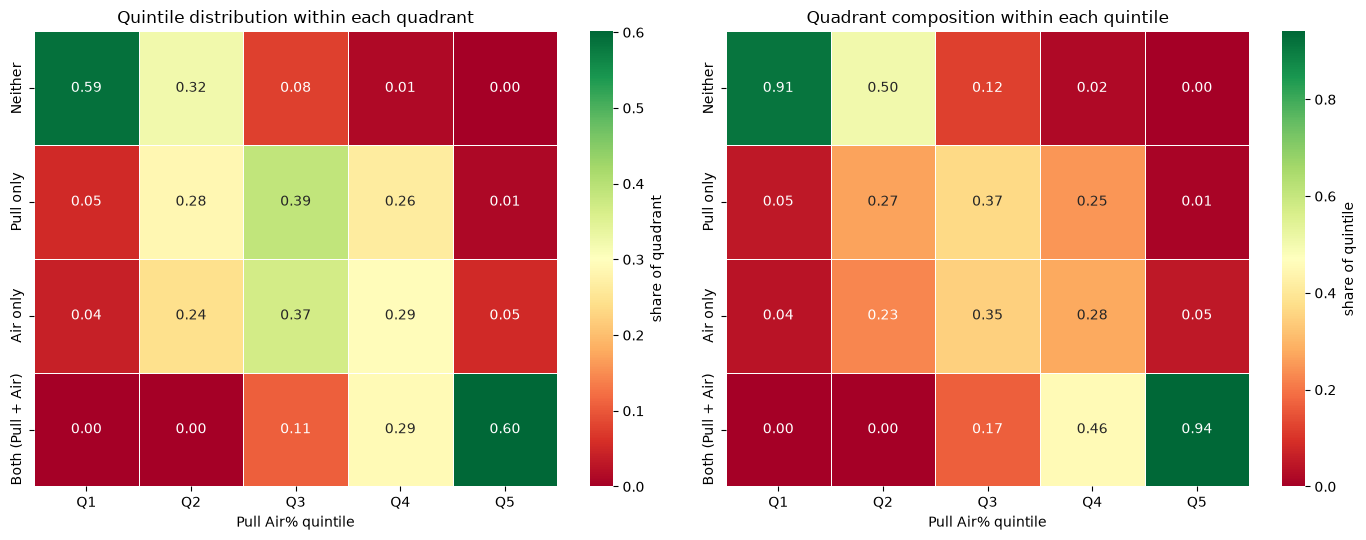

In [47]:
# ── Visual: heatmap of quadrant × quintile ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(ct, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=ct.values.max(),
            linewidths=0.5, linecolor="white", ax=axes[0],
            cbar_kws={"label": "share of quadrant"})
axes[0].set_title("Quintile distribution within each quadrant")
axes[0].set_xlabel("Pull Air% quintile"); axes[0].set_ylabel("")

sns.heatmap(ct_col, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=ct_col.values.max(),
            linewidths=0.5, linecolor="white", ax=axes[1],
            cbar_kws={"label": "share of quintile"})
axes[1].set_title("Quadrant composition within each quintile")
axes[1].set_xlabel("Pull Air% quintile"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

In [48]:
# ══ THE CHERRY ON TOP: what makes Both-hitter status STICK? ══
# Not "what is Both" (already answered — direction axis + tilt) but
# "among hitters who achieve Both, what separates the ones who sustain it
# from the ones who fall back to Pull only / Air only / Neither?"

# Requires: 'multi' (batters with 3+ consecutive season runs, from the
# stickiness work) and each season's quadrant label. Rebuild quadrant per
# season if not already present.
# ── Add pull_pct / air_ball_pct to season_agg (needed for per-season quadrant) ─
bbe_full["_is_pull"] = (bbe_full["spray_angle_norm"] < -15).astype(int)   # ±15° zone convention
bbe_full["_is_air"]  = (bbe_full["launch_angle"]    >= 10).astype(int)

season_agg = (bbe_full.groupby(["batter", "season"])
             .agg(n_bbe        = ("pull_air", "count"),
                  pull_air_pct = ("pull_air", "mean"),
                  pull_pct     = ("_is_pull", "mean"),
                  air_ball_pct = ("_is_air",  "mean"))
             .reset_index())
season_agg = season_agg[season_agg["n_bbe"] >= MIN_BBE]

print(f"season_agg rebuilt with marginals: {season_agg.shape}")
print(season_agg[["pull_air_pct", "pull_pct", "air_ball_pct"]].describe().round(3).to_string())
season_agg["is_pull_s"] = season_agg["pull_pct"]     >= season_agg["pull_pct"].median()
season_agg["is_air_s"]  = season_agg["air_ball_pct"] >= season_agg["air_ball_pct"].median()
def _label_s(r):
    p, a = r["is_pull_s"], r["is_air_s"]
    if p and a: return "Both"
    if p:       return "Pull only"
    if a:       return "Air only"
    return "Neither"
season_agg["quadrant_s"] = season_agg.apply(_label_s, axis=1)

wide_q = season_agg.pivot(index="batter", columns="season", values="quadrant_s")

def _longest_run(row):
    present = [s for s in seasons_sorted if pd.notna(row[s])]
    if not present: return []
    runs, cur = [], [present[0]]
    for s in present[1:]:
        if s == cur[-1] + 1: cur.append(s)
        else: runs.append(cur); cur = [s]
    runs.append(cur)
    return max(runs, key=len)

wide_q["run"] = wide_q.apply(_longest_run, axis=1)
wide_q["run_len"] = wide_q["run"].apply(len)
multi_q = wide_q[wide_q["run_len"] >= 2].copy()
multi_q["quad_path"] = multi_q.apply(lambda r: tuple(r[s] for s in r["run"]), axis=1)

# Define: ever-Both hitters, split into PERSISTENT (Both in 2+ seasons of their
# run) vs TRANSIENT (Both in exactly 1 season, then dropped out).
multi_q["n_both_seasons"] = multi_q["quad_path"].apply(lambda p: p.count("Both"))
ever_both = multi_q[multi_q["n_both_seasons"] >= 1].copy()
ever_both["persistent_both"] = ever_both["n_both_seasons"] >= 2

print(f"Hitters who were Both at least once: {len(ever_both)}")
print(f"  Persistent (Both 2+ seasons):  {ever_both['persistent_both'].sum()}")
print(f"  Transient  (Both exactly 1):    {(~ever_both['persistent_both']).sum()}")

season_agg rebuilt with marginals: (1348, 6)
       pull_air_pct  pull_pct  air_ball_pct
count     1348.0000 1348.0000     1348.0000
mean         0.1790    0.4400        0.5580
std          0.0550    0.0580        0.0690
min          0.0430    0.2600        0.3420
25%          0.1410    0.4000        0.5120
50%          0.1750    0.4430        0.5600
75%          0.2150    0.4800        0.6050
max          0.4270    0.6050        0.7790
Hitters who were Both at least once: 167
  Persistent (Both 2+ seasons):  111
  Transient  (Both exactly 1):    56


In [49]:
# ── Compare their swing features — using the LAST season they were Both ─────
def _last_both_season(row):
    for s, q in zip(reversed(row["run"]), reversed(row["quad_path"])):
        if q == "Both":
            return s
    return None
ever_both["last_both_season"] = ever_both.apply(_last_both_season, axis=1)
ever_both_reset = ever_both.reset_index()

profile_rows = []
for _, row in ever_both_reset.iterrows():
    feat_row = season_agg[(season_agg["batter"] == row["batter"]) &
                          (season_agg["season"] == row["last_both_season"])]
    if len(feat_row) == 0: continue
    profile_rows.append({**feat_row.iloc[0].to_dict(),
                         "persistent_both": row["persistent_both"]})
profile = pd.DataFrame(profile_rows)

# Merge in swing-mechanics features from batter_df (or re-derive per-season if available)
profile = profile.merge(batter_df[["batter"] + [f for f in ALL_FEATURES if f != "is_L"] + ["stand"]]
                        .drop_duplicates("batter"), on="batter", how="left")
profile["is_L"] = (profile["stand"] == "L").astype(int)

print("── What separates PERSISTENT Both hitters from TRANSIENT ones ──────────")
rows = []
for f in ALL_FEATURES:
    p = profile.loc[profile["persistent_both"], f].dropna()
    t = profile.loc[~profile["persistent_both"], f].dropna()
    if len(p) < 5 or len(t) < 5:
        continue
    pooled_sd = np.sqrt(((len(p)-1)*p.var() + (len(t)-1)*t.var()) / (len(p)+len(t)-2))
    d = (p.mean() - t.mean()) / pooled_sd if pooled_sd > 0 else np.nan
    rows.append({"feature": f, "persistent_mean": p.mean(), "transient_mean": t.mean(),
                "Cohen_d": d})
result_tbl = pd.DataFrame(rows).sort_values("Cohen_d", key=lambda s: s.abs(), ascending=False)
print(result_tbl.round(3).to_string(index=False))

── What separates PERSISTENT Both hitters from TRANSIENT ones ──────────
       feature  persistent_mean  transient_mean  Cohen_d
      mean_dir           1.7310         -0.2620   0.8920
       mean_aa          10.3540          9.4490   0.3080
     mean_tilt          32.2370         33.1170  -0.2480
fb_swing_share           0.5500          0.5600  -0.2410
   z_swing_pct           0.6810          0.6700   0.2210
   mean_length           7.2690          7.1890   0.2110
   o_swing_pct           0.2820          0.2770   0.0940
          is_L           0.5140          0.5180  -0.0090


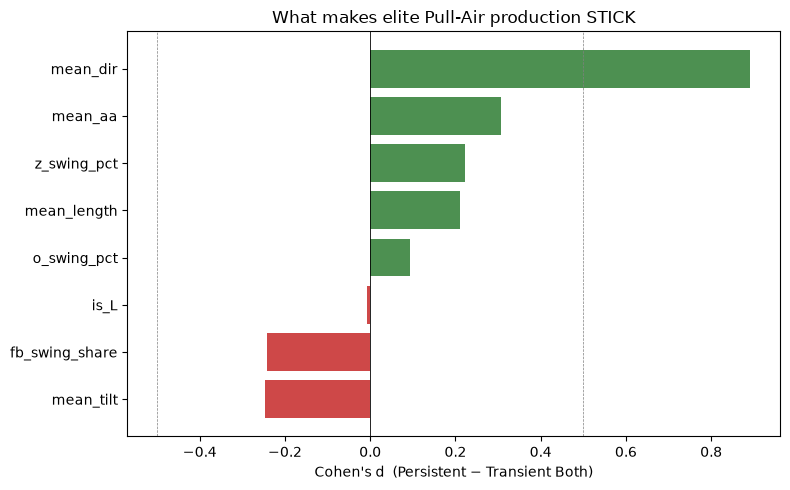

In [50]:
# ── Visual ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
order = result_tbl.set_index("feature")["Cohen_d"].sort_values()
colors = ["#2E7D32" if v > 0 else "#C62828" for v in order.values]
ax.barh(order.index, order.values, color=colors, alpha=0.85)
ax.axvline(0, color="black", lw=0.6)
ax.axvline(0.5, color="gray", ls="--", lw=0.5); ax.axvline(-0.5, color="gray", ls="--", lw=0.5)
ax.set_xlabel("Cohen's d  (Persistent − Transient Both)")
ax.set_title("What makes elite Pull-Air production STICK")
plt.tight_layout(); plt.show()

## 5. Model Dataset

In [51]:
need = ALL_FEATURES + ["quadrant", "pull_air_pct", "batter", "stand"]
sub = batter_df.dropna(subset=need).copy()
groups = sub["batter"].values
gkf    = GroupKFold(n_splits=CV_FOLDS)

print(f"Model dataset: n = {len(sub)} hitters")
print(f"Features: {ALL_FEATURES}")
print(f"Quadrant counts:")
print(sub["quadrant"].value_counts().reindex(QUAD_ORDER).to_string())


Model dataset: n = 496 hitters
Features: ['mean_tilt', 'mean_aa', 'mean_dir', 'z_swing_pct', 'o_swing_pct', 'fb_swing_share', 'mean_length', 'is_L']
Quadrant counts:
quadrant
Neither              154
Pull only             92
Air only              94
Both (Pull + Air)    156


In [52]:
print(f"depth_in_c sample: {cp['depth_in_c'].head().tolist()}")
print(f"depth_in sample (should be small, e.g. -10 to +20 range): {cp['depth_in'].head().tolist()}")
print(f"Y_COL raw sample: {cp[Y_COL].head().tolist()}")

depth_in_c sample: [3.639502768400625, -3.6388704117960273, 6.182784419648122, 4.829229672478256, -8.974736508717687]
depth_in sample (should be small, e.g. -10 to +20 range): [36.80366632648967, 28.43700776041795, 37.40690230448863, 39.47141517614016, 24.68272854084488]
Y_COL raw sample: [36.80366632648967, 28.43700776041795, 37.40690230448863, 39.47141517614016, 24.68272854084488]


In [53]:
# ── Depth: use raw Y_COL directly — no sign flip needed for this data ──────
cp["depth_in"]   = cp[Y_COL]                       # + = out in front, already correct
cp["depth_in_c"] = cp.groupby("batter")["depth_in"].transform(lambda s: s - s.mean())

# Rebuild mean_depth on batter_df from the corrected depth_in
depth_agg = (cp.groupby("batter")["depth_in"]
             .mean().rename("mean_depth").reset_index())
if "mean_depth" in batter_df.columns:
    batter_df = batter_df.drop(columns="mean_depth")
batter_df = batter_df.merge(depth_agg, on="batter", how="left")

print(f"mean_depth: {batter_df['mean_depth'].describe().round(2).to_string()}")

# Sanity checks
if "bat_speed" in cp.columns:
    r = cp[["depth_in", "bat_speed"]].dropna().corr().iloc[0, 1]
    print(f"\ncorr(depth_in, bat_speed) = {r:+.3f}   (expect + now)")

print(f"\nmean_depth by quadrant (expect Both/Air only highest, Neither lowest):")
print(batter_df.groupby("quadrant")["mean_depth"].mean().reindex(QUAD_ORDER).round(2).to_string())

mean_depth: count   496.0000
mean     29.9000
std       3.0300
min      20.8300
25%      27.8800
50%      29.7500
75%      32.0600
max      38.9500

corr(depth_in, bat_speed) = +0.242   (expect + now)

mean_depth by quadrant (expect Both/Air only highest, Neither lowest):
quadrant
Neither             29.1000
Pull only           29.5100
Air only            30.0900
Both (Pull + Air)   30.8200


In [54]:
# Re-derive the optimal window from the CORRECTED pooled curve, not a guess
# Find where the pooled rate is within, say, 90% of its peak — a data-driven window
peak_rate = bin_rates.max()
peak_loc  = bin_centers[bin_rates.argmax()]
threshold = 0.90 * peak_rate
in_zone   = bin_centers[bin_rates >= threshold]
OPT_LO, OPT_HI = in_zone.min(), in_zone.max()

print(f"Corrected pooled curve peak: rate={peak_rate:.3f} at depth_in_c={peak_loc:+.2f}\"")
print(f"90%-of-peak window: [{OPT_LO:+.2f}, {OPT_HI:+.2f}]  (was hardcoded to [0, 10] before)")

# Rebuild depth_optimal_share with the corrected window
cp["_in_optimal"] = cp["depth_in_c"].between(OPT_LO, OPT_HI).astype(int)
optimal_share = (cp.groupby("batter")["_in_optimal"]
                 .mean().rename("depth_optimal_share").reset_index())

if "depth_optimal_share" in batter_df.columns:
    batter_df = batter_df.drop(columns="depth_optimal_share")
batter_df = batter_df.merge(optimal_share, on="batter", how="left")

r = spearmanr(batter_df["depth_optimal_share"], batter_df["pull_air_pct"]).correlation
print(f"Spearman(depth_optimal_share, pull_air_pct) = {r:+.3f}  (corrected window)")

Corrected pooled curve peak: rate=0.486 at depth_in_c=+11.20"
90%-of-peak window: [+8.84, +13.56]  (was hardcoded to [0, 10] before)
Spearman(depth_optimal_share, pull_air_pct) = +nan  (corrected window)


## 6. Approach A — Multinomial Quadrant Classifier

Predicts the four quadrants jointly. Softmax naturally handles the mixture
cells without forcing them through two anti-correlated marginals.

In [55]:
# RF multinomial (predictive)
pipe_rf = Pipeline([("s", StandardScaler()),
                    ("m", RandomForestClassifier(
                        n_estimators=500, max_depth=10, min_samples_leaf=10,
                        class_weight="balanced", random_state=SEED, n_jobs=-1))])

proba_rf = cross_val_predict(pipe_rf, sub[ALL_FEATURES].values, sub["quadrant"].values,
                             cv=gkf, groups=groups, method="predict_proba")
pipe_rf.fit(sub[ALL_FEATURES].values, sub["quadrant"].values)
classes_rf = pipe_rf.named_steps["m"].classes_

# Align proba columns to QUAD_ORDER
class_to_col = {c: i for i, c in enumerate(classes_rf)}
proba_qd = np.column_stack([proba_rf[:, class_to_col[q]] for q in QUAD_ORDER])
pred_rf  = np.array(QUAD_ORDER)[proba_qd.argmax(axis=1)]
actual   = sub["quadrant"].values

acc_rf = accuracy_score(actual, pred_rf)
kap_rf = cohen_kappa_score(actual, pred_rf)

print(f"── Approach A (RF) ─────────────────────────────────────────────────────")
print(f"  Accuracy = {acc_rf:.4f}")
print(f"  Cohen κ  = {kap_rf:.4f}")
print(f"\n  Per-class one-vs-rest AUC:")
for q in QUAD_ORDER:
    y_oc = (actual == q).astype(int)
    p_oc = proba_qd[:, QUAD_ORDER.index(q)]
    print(f"    {q:<22} AUC = {roc_auc_score(y_oc, p_oc):.4f}")


── Approach A (RF) ─────────────────────────────────────────────────────
  Accuracy = 0.5887
  Cohen κ  = 0.4402

  Per-class one-vs-rest AUC:
    Neither                AUC = 0.8602
    Pull only              AUC = 0.7135
    Air only               AUC = 0.7913
    Both (Pull + Air)      AUC = 0.8810


── Per-quadrant metrics ───────────────────────────────────────────────
                   precision  recall  f1-score  support
Neither               0.6910  0.6230    0.6550 154.0000
Pull only             0.3820  0.3700    0.3760  92.0000
Air only              0.4750  0.5000    0.4870  94.0000
Both (Pull + Air)     0.6800  0.7370    0.7080 156.0000


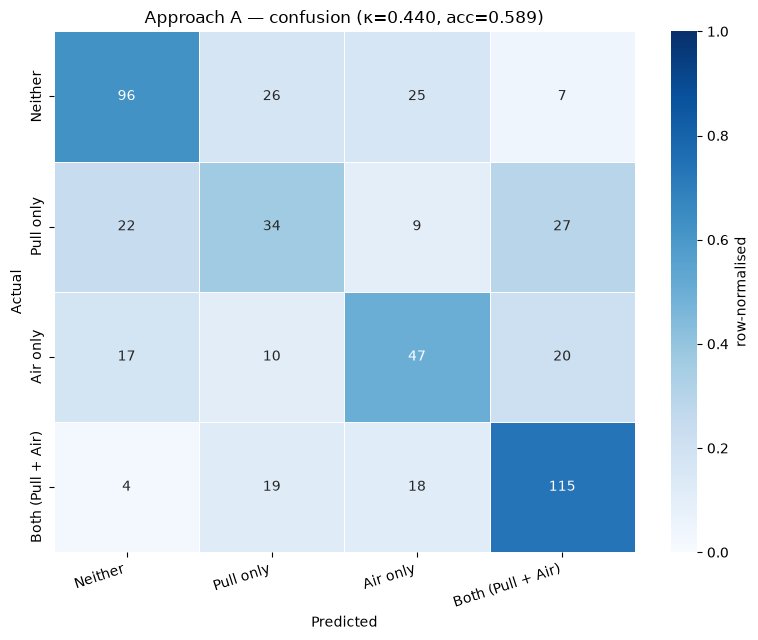

In [56]:
# Per-category metrics + confusion matrix
rep_rf = pd.DataFrame(classification_report(actual, pred_rf, labels=QUAD_ORDER,
                      output_dict=True, zero_division=0)).T
print("── Per-quadrant metrics ───────────────────────────────────────────────")
print(rep_rf.loc[QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6.5))
cm  = confusion_matrix(actual, pred_rf, labels=QUAD_ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
            xticklabels=QUAD_ORDER, yticklabels=QUAD_ORDER,
            linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "row-normalised"})
ax.set_title(f"Approach A — confusion (κ={kap_rf:.3f}, acc={acc_rf:.3f})")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_xticklabels(QUAD_ORDER, rotation=18, ha="right")
plt.tight_layout(); plt.show()


── Multinomial LR coefficients (standardised) ─────────────────────────
                Neither  Pull only  Air only  Both (Pull + Air)
mean_tilt       -0.0470    -0.4240    0.5830            -0.1120
mean_aa         -1.2020    -0.2020   -0.0120             1.4170
mean_dir        -1.5000    -0.2090    0.3160             1.3930
z_swing_pct     -0.2080     0.0300    0.1400             0.0380
o_swing_pct      0.3310    -0.2500    0.1010            -0.1810
fb_swing_share   0.0270    -0.4380    0.4440            -0.0340
mean_length     -0.0230     0.1380    0.0600            -0.1750
is_L            -0.6220     0.3350   -0.3370             0.6230


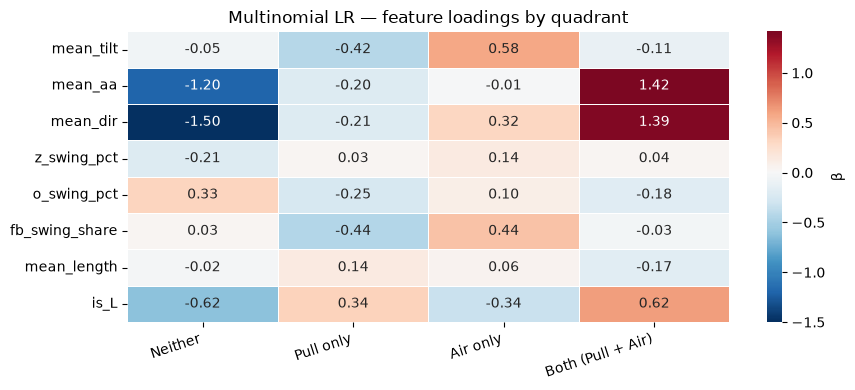


Read: each column is what makes a hitter that quadrant relative to the average.
Pull only and Air only should show opposite signs on mean_aa / mean_dir;
Both should look like Pull+Air mixed; Neither is the absence of both signals.


In [57]:
# Multinomial LR for interpretable coefficients
pipe_lr = Pipeline([("s", StandardScaler()),
                    ("m", LogisticRegression(
                        multi_class="multinomial", solver="lbfgs",
                        max_iter=2000, C=0.5, class_weight="balanced",
                        random_state=SEED))])
pipe_lr.fit(sub[ALL_FEATURES].values, sub["quadrant"].values)
classes_lr = pipe_lr.named_steps["m"].classes_

coefs = pd.DataFrame(pipe_lr.named_steps["m"].coef_, index=classes_lr,
                     columns=ALL_FEATURES).reindex(QUAD_ORDER).T
print("── Multinomial LR coefficients (standardised) ─────────────────────────")
print(coefs.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(coefs, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax, cbar_kws={"label": "β"})
ax.set_title("Multinomial LR — feature loadings by quadrant")
ax.set_xticklabels(QUAD_ORDER, rotation=18, ha="right")
plt.tight_layout(); plt.show()

print("\nRead: each column is what makes a hitter that quadrant relative to the average.")
print("Pull only and Air only should show opposite signs on mean_aa / mean_dir;")
print("Both should look like Pull+Air mixed; Neither is the absence of both signals.")


── Rules-based fitted parameters ──────────────────────────────────────
  pull   μ(aa)=+7.94  μ(dir)=-0.32  prior=0.185
  air    μ(aa)=+8.73  μ(dir)=+0.04  prior=0.190
  blend  μ(aa)=+8.60  μ(dir)=-0.42  prior=0.625
  Blend tilt threshold: 32.00

── Rules-based classifier (CV) ────────────────────────────────────────
  Accuracy = 0.3448
  Cohen κ  = 0.0472

── Per-quadrant metrics ───────────────────────────────────────────────
                   precision  recall  f1-score  support
Neither               0.3570  0.5580    0.4350 154.0000
Pull only             0.0000  0.0000    0.0000  92.0000
Air only              0.0000  0.0000    0.0000  94.0000
Both (Pull + Air)     0.3350  0.5450    0.4150 156.0000


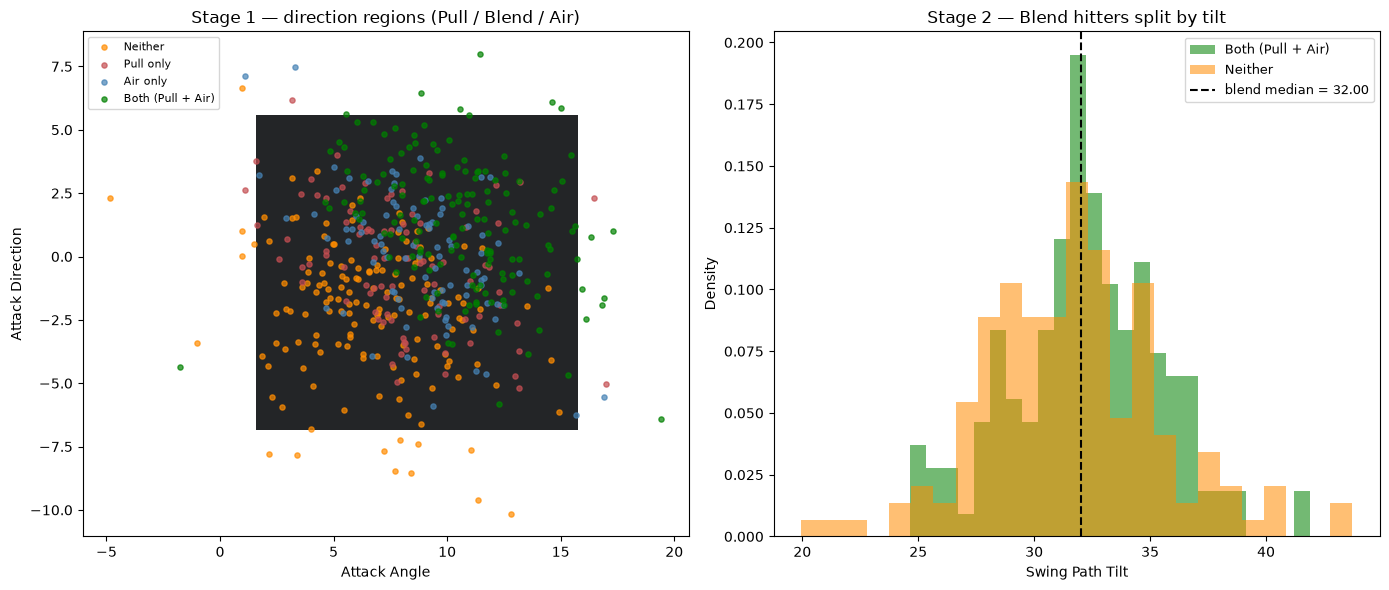

In [58]:
# ── 6.5  Rules-based baseline: direction → intensity two-stage classifier ───
# Stage 1: assign to Pull / Blend / Air by likelihood under each direction group's
#          bivariate Gaussian fit on (mean_aa, mean_dir).
# Stage 2: Blend hitters split into Both / Neither by mean_tilt vs the blend median.
#
# Fit is in-sample (uses the full data's per-group distributions); we cross-validate
# the *predictions* so the comparison to Approach A is honest.
from scipy.stats import multivariate_normal

def _dir_group(q):
    if q == "Pull only": return "pull"
    if q == "Air only":  return "air"
    return "blend"                                         # Both + Neither
sub["dir_group"] = sub["quadrant"].map(_dir_group)

DIR_FEATS = ["mean_aa", "mean_dir"]

def _fit_rules(train_df):
    params = {}
    for g in ["pull", "air", "blend"]:
        x = train_df.loc[train_df["dir_group"] == g, DIR_FEATS].dropna().values.astype(np.float64)
        if len(x) < 2:
            x = train_df[DIR_FEATS].dropna().values.astype(np.float64)
        mean = x.mean(axis=0)
        cov  = np.cov(x.T) if len(x) >= 2 else np.eye(2)
        cov  = cov + np.eye(2) * 1e-3
        params[g] = {"mean": mean, "cov": cov,
                     "prior": max(1, len(x)) / len(train_df)}
    blend_tilt = train_df.loc[train_df["dir_group"] == "blend", "mean_tilt"].dropna()
    tilt_med = blend_tilt.median() if len(blend_tilt) else train_df["mean_tilt"].median()
    return params, tilt_med

def _apply_rules(test_df, params, tilt_med):
    X_dir = test_df[DIR_FEATS].values
    liks = np.column_stack([
        multivariate_normal.logpdf(X_dir, mean=params[g]["mean"], cov=params[g]["cov"])
        + np.log(params[g]["prior"])
        for g in ["pull", "air", "blend"]
    ])
    pred_dir = np.array(["pull", "air", "blend"])[liks.argmax(axis=1)]
    tilt = test_df["mean_tilt"].values
    return np.where(pred_dir == "pull", "Pull only",
           np.where(pred_dir == "air",  "Air only",
           np.where(tilt >= tilt_med,   "Both (Pull + Air)", "Neither")))

# Cross-validated rules-based predictions (same folds as Approach A)
pred_rules = np.empty(len(sub), dtype=object)
for train_idx, test_idx in gkf.split(sub, sub["quadrant"], groups):
    params, tilt_med = _fit_rules(sub.iloc[train_idx])
    pred_rules[test_idx] = _apply_rules(sub.iloc[test_idx], params, tilt_med)

# Fit once on full data too, for coefficient inspection
params_full, tilt_med_full = _fit_rules(sub)
print("── Rules-based fitted parameters ──────────────────────────────────────")
for g in ["pull", "air", "blend"]:
    p = params_full[g]
    print(f"  {g:5s}  μ(aa)={p['mean'][0]:+.2f}  μ(dir)={p['mean'][1]:+.2f}  "
          f"prior={p['prior']:.3f}")
print(f"  Blend tilt threshold: {tilt_med_full:.2f}")

# Metrics
kap_rules = cohen_kappa_score(actual, pred_rules)
acc_rules = accuracy_score(actual,   pred_rules)
print(f"\n── Rules-based classifier (CV) ────────────────────────────────────────")
print(f"  Accuracy = {acc_rules:.4f}")
print(f"  Cohen κ  = {kap_rules:.4f}")
print(f"\n── Per-quadrant metrics ───────────────────────────────────────────────")
print(pd.DataFrame(classification_report(actual, pred_rules, labels=QUAD_ORDER,
      output_dict=True, zero_division=0)).T.loc[
      QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

# Visual: the direction decision boundary drawn on the (aa, dir) plane
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) Direction likelihood map
aa_grid  = np.linspace(sub["mean_aa"].quantile(0.02),  sub["mean_aa"].quantile(0.98),  100)
dir_grid = np.linspace(sub["mean_dir"].quantile(0.02), sub["mean_dir"].quantile(0.98), 100)
AA, DD = np.meshgrid(aa_grid, dir_grid)
grid_pts = np.column_stack([AA.ravel(), DD.ravel()])
grid_liks = np.column_stack([
    multivariate_normal.logpdf(grid_pts, mean=params_full[g]["mean"], cov=params_full[g]["cov"])
    + np.log(params_full[g]["prior"])
    for g in ["pull", "air", "blend"]
])
grid_pred = np.array(["pull", "air", "blend"])[grid_liks.argmax(axis=1)]
region_colors = {"pull": "#c44e52", "air": "steelblue", "blend": "#B0BEC5"}
region_map = np.array([region_colors[g] for g in grid_pred]).reshape(AA.shape + (1,))
axes[0].imshow(np.zeros_like(AA)[..., None] * np.zeros(3), extent=[aa_grid[0], aa_grid[-1],
               dir_grid[0], dir_grid[-1]], aspect="auto", origin="lower")
# Simpler: contour of the argmax
for g_i, g in enumerate(["pull", "air", "blend"]):
    axes[0].contourf(AA, DD, (grid_pred.reshape(AA.shape) == g).astype(int),
                     levels=[0.5, 1.5], colors=[region_colors[g]], alpha=0.20)
for q in QUAD_ORDER:
    m = sub["quadrant"] == q
    axes[0].scatter(sub.loc[m, "mean_aa"], sub.loc[m, "mean_dir"],
                    s=14, alpha=0.7, color=QUAD_COLORS[q], label=q)
axes[0].set_xlabel("Attack Angle"); axes[0].set_ylabel("Attack Direction")
axes[0].set_title("Stage 1 — direction regions (Pull / Blend / Air)")
axes[0].legend(fontsize=8)

# (b) Tilt histogram for Blend hitters, with the split threshold
blend_mask = sub["dir_group"] == "blend"
for q in ["Both (Pull + Air)", "Neither"]:
    m = blend_mask & (sub["quadrant"] == q)
    axes[1].hist(sub.loc[m, "mean_tilt"], bins=25, alpha=0.55,
                 color=QUAD_COLORS[q], label=q, density=True)
axes[1].axvline(tilt_med_full, color="black", ls="--",
                label=f"blend median = {tilt_med_full:.2f}")
axes[1].set_xlabel("Swing Path Tilt"); axes[1].set_ylabel("Density")
axes[1].set_title("Stage 2 — Blend hitters split by tilt")
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 7. Approach B — Direct Joint Regression

Predicts `pull_air_pct` as a continuous score for ranking. Absorbs the
pull-air dependence inside the regressor's nonlinearity rather than fighting
two anti-correlated marginals.

── Approach B (RF regression) ─────────────────────────────────────────
  Spearman = +0.7608
  Pearson  = +0.7684
  RMSE     = 0.0319


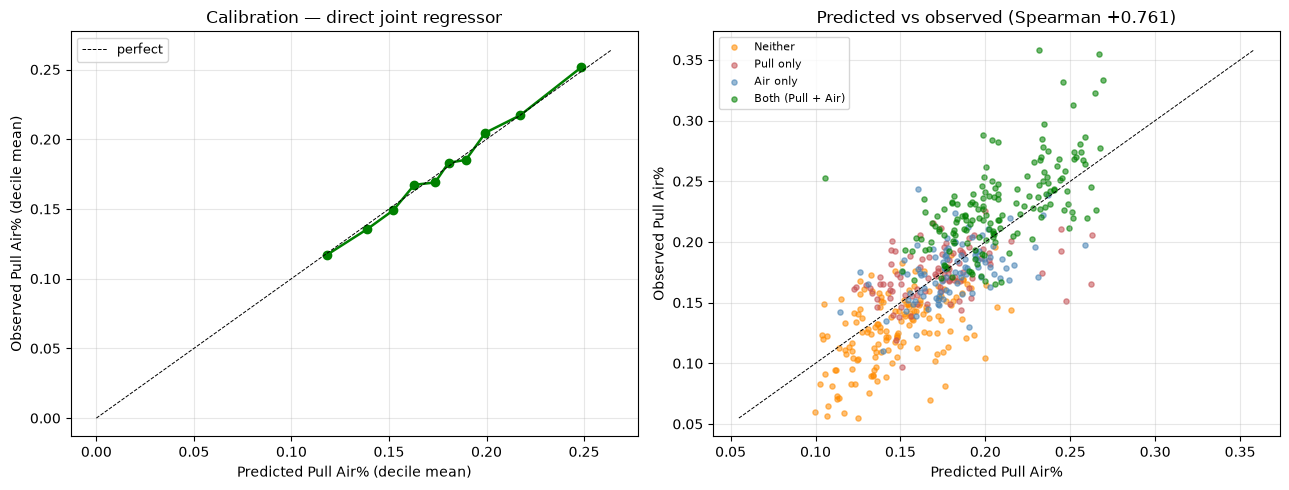

In [59]:
pipe_reg = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestRegressor(
                         n_estimators=500, max_depth=10, min_samples_leaf=10,
                         random_state=SEED, n_jobs=-1))])
pred_b = cross_val_predict(pipe_reg, sub[ALL_FEATURES].values,
                           sub["pull_air_pct"].values, cv=gkf, groups=groups)
y_pa = sub["pull_air_pct"].values

r_spear = spearmanr(pred_b, y_pa).correlation
r_pear  = pearsonr(pred_b,  y_pa)[0]
rmse    = float(np.sqrt(np.mean((pred_b - y_pa) ** 2)))
print(f"── Approach B (RF regression) ─────────────────────────────────────────")
print(f"  Spearman = {r_spear:+.4f}")
print(f"  Pearson  = {r_pear:+.4f}")
print(f"  RMSE     = {rmse:.4f}")

# Calibration + scatter
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = np.argsort(pred_b); bins = np.array_split(order, 10)
px = [pred_b[b].mean() for b in bins]
py = [y_pa[b].mean()   for b in bins]
axes[0].plot(px, py, "o-", color="green", lw=1.8, markersize=6)
lim = max(max(px), max(py)) * 1.05
axes[0].plot([0, lim], [0, lim], "k--", lw=0.7, label="perfect")
axes[0].set_xlabel("Predicted Pull Air% (decile mean)")
axes[0].set_ylabel("Observed Pull Air% (decile mean)")
axes[0].set_title("Calibration — direct joint regressor")
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

for q in QUAD_ORDER:
    m = actual == q
    axes[1].scatter(pred_b[m], y_pa[m], s=14, alpha=0.55,
                    color=QUAD_COLORS[q], label=q)
axes[1].plot([y_pa.min(), y_pa.max()], [y_pa.min(), y_pa.max()],
             "k--", lw=0.7)
axes[1].set_xlabel("Predicted Pull Air%"); axes[1].set_ylabel("Observed Pull Air%")
axes[1].set_title(f"Predicted vs observed (Spearman {r_spear:+.3f})")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 8. Comparison vs the Marginal-Cross Baseline

Confirms the new architecture beats the previous `P(pull) × P(air)` approach
on both ranking and quadrant classification.

In [60]:
def _cv_proba_bin(feats, y, sub_df):
    pipe = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestClassifier(
                         n_estimators=500, max_depth=10, min_samples_leaf=10,
                         class_weight="balanced", random_state=SEED, n_jobs=-1))])
    return cross_val_predict(pipe, sub_df[feats].values, y,
                             cv=gkf, groups=sub_df["batter"].values,
                             method="predict_proba")[:, 1]

y_pull = sub["is_pull"].values
y_air  = sub["is_air"].values
P_pull = _cv_proba_bin(ALL_FEATURES, y_pull, sub)
P_air  = _cv_proba_bin(ALL_FEATURES, y_air,  sub)
joint_cross = P_pull * P_air

def _assign(pp, ap, tp, ta):
    return np.where((pp >= tp) & (ap >= ta), "Both (Pull + Air)",
           np.where((pp >= tp) & (ap <  ta), "Pull only",
           np.where((pp <  tp) & (ap >= ta), "Air only", "Neither")))

grid = np.linspace(0.30, 0.70, 21)
best = (-np.inf, 0.5, 0.5)
for tp in grid:
    for ta in grid:
        k = cohen_kappa_score(actual, _assign(P_pull, P_air, tp, ta))
        if k > best[0]: best = (k, tp, ta)
pred_cross = _assign(P_pull, P_air, best[1], best[2])

print(f"corr(P(pull), P(air)) = {np.corrcoef(P_pull, P_air)[0,1]:+.3f}   "
      f"(the entanglement that motivated the architecture switch)")
print(f"\n── Ranking pull_air_pct ───────────────────────────────────────────────")
print(f"  Approach B (direct regression) :  Spearman = "
      f"{spearmanr(pred_b, y_pa).correlation:+.4f}")
print(f"  Baseline P(pull)·P(air)        :  Spearman = "
      f"{spearmanr(joint_cross, y_pa).correlation:+.4f}")
print(f"\n── Quadrant classification ────────────────────────────────────────────")
print(f"  Approach A (multinomial argmax):  κ = {kap_rf:.4f}, acc = {acc_rf:.4f}")
print(f"  Baseline tuned corner          :  κ = "
      f"{cohen_kappa_score(actual, pred_cross):.4f}, "
      f"acc = {accuracy_score(actual, pred_cross):.4f}  "
      f"(at t_pull={best[1]:.2f}, t_air={best[2]:.2f})")

print(f"\n── Per-quadrant F1: A vs baseline ─────────────────────────────────────")
rep_a = pd.DataFrame(classification_report(actual, pred_rf, labels=QUAD_ORDER,
                     output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
rep_b = pd.DataFrame(classification_report(actual, pred_cross, labels=QUAD_ORDER,
                     output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
print(pd.DataFrame({"Approach A": rep_a, "Baseline cross": rep_b,
                    "Δ": rep_a - rep_b}).round(3).to_string())


corr(P(pull), P(air)) = +0.670   (the entanglement that motivated the architecture switch)

── Ranking pull_air_pct ───────────────────────────────────────────────
  Approach B (direct regression) :  Spearman = +0.7608
  Baseline P(pull)·P(air)        :  Spearman = +0.7627

── Quadrant classification ────────────────────────────────────────────
  Approach A (multinomial argmax):  κ = 0.4402, acc = 0.5887
  Baseline tuned corner          :  κ = 0.4350, acc = 0.5907  (at t_pull=0.46, t_air=0.54)

── Per-quadrant F1: A vs baseline ─────────────────────────────────────
                   Approach A  Baseline cross       Δ
Neither                0.6550          0.6730 -0.0180
Pull only              0.3760          0.4090 -0.0330
Air only               0.4870          0.3290  0.1580
Both (Pull + Air)      0.7080          0.7260 -0.0180


corr(P(pull), P(air)) = +0.670

── Ranking pull_air_pct ───────────────────────────────────────────────
  Approach B (direct regression) :  Spearman = +0.7608
  Baseline P(pull)·P(air)        :  Spearman = +0.7627

── Quadrant classification ────────────────────────────────────────────
  Rules-based (direction+tilt)   :  κ = 0.0472, acc = 0.3448
  Baseline tuned corner          :  κ = 0.4350, acc = 0.5907
  Approach A (multinomial argmax):  κ = 0.4402, acc = 0.5887

── Per-quadrant F1: three architectures ───────────────────────────────
                   Rules  Marginal cross  Approach A  A − Rules  A − Cross
Neither           0.4350          0.6730      0.6550     0.2200    -0.0180
Pull only         0.0000          0.4090      0.3760     0.3760    -0.0330
Air only          0.0000          0.3290      0.4870     0.4870     0.1580
Both (Pull + Air) 0.4150          0.7260      0.7080     0.2930    -0.0180


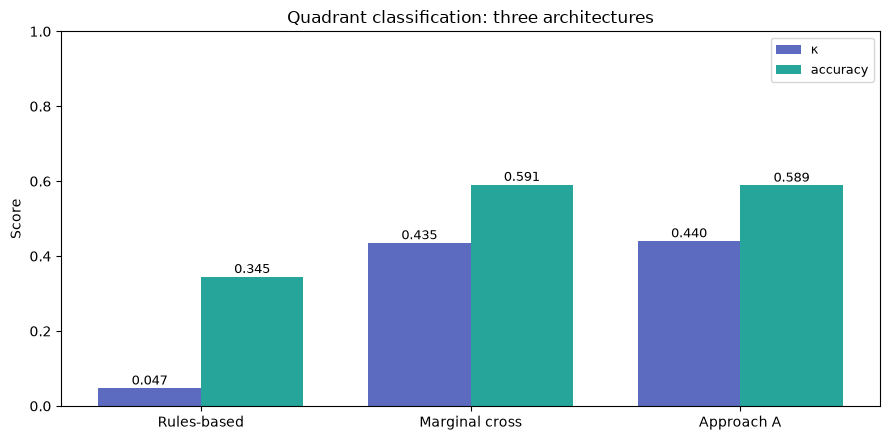

In [61]:
# ── 8. Three-way comparison: rules baseline vs marginal cross vs Approach A ──
def _cv_proba_bin(feats, y, sub_df):
    pipe = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestClassifier(
                         n_estimators=500, max_depth=10, min_samples_leaf=10,
                         class_weight="balanced", random_state=SEED, n_jobs=-1))])
    return cross_val_predict(pipe, sub_df[feats].values, y,
                             cv=gkf, groups=sub_df["batter"].values,
                             method="predict_proba")[:, 1]

# Marginal cross baseline
y_pull = sub["is_pull"].values
y_air  = sub["is_air"].values
P_pull = _cv_proba_bin(ALL_FEATURES, y_pull, sub)
P_air  = _cv_proba_bin(ALL_FEATURES, y_air,  sub)
joint_cross = P_pull * P_air

def _assign(pp, ap, tp, ta):
    return np.where((pp >= tp) & (ap >= ta), "Both (Pull + Air)",
           np.where((pp >= tp) & (ap <  ta), "Pull only",
           np.where((pp <  tp) & (ap >= ta), "Air only", "Neither")))

grid = np.linspace(0.30, 0.70, 21)
best = (-np.inf, 0.5, 0.5)
for tp in grid:
    for ta in grid:
        k = cohen_kappa_score(actual, _assign(P_pull, P_air, tp, ta))
        if k > best[0]: best = (k, tp, ta)
pred_cross = _assign(P_pull, P_air, best[1], best[2])

# ── Ranking pull_air_pct ────────────────────────────────────────────────────
print(f"corr(P(pull), P(air)) = {np.corrcoef(P_pull, P_air)[0,1]:+.3f}")

print(f"\n── Ranking pull_air_pct ───────────────────────────────────────────────")
print(f"  Approach B (direct regression) :  Spearman = "
      f"{spearmanr(pred_b, y_pa).correlation:+.4f}")
print(f"  Baseline P(pull)·P(air)        :  Spearman = "
      f"{spearmanr(joint_cross, y_pa).correlation:+.4f}")

# ── Classification: three architectures ─────────────────────────────────────
print(f"\n── Quadrant classification ────────────────────────────────────────────")
print(f"  Rules-based (direction+tilt)   :  κ = {kap_rules:.4f}, acc = {acc_rules:.4f}")
print(f"  Baseline tuned corner          :  κ = "
      f"{cohen_kappa_score(actual, pred_cross):.4f}, "
      f"acc = {accuracy_score(actual, pred_cross):.4f}")
print(f"  Approach A (multinomial argmax):  κ = {kap_rf:.4f}, acc = {acc_rf:.4f}")

# Per-quadrant F1 for all three
f1_rules = pd.DataFrame(classification_report(actual, pred_rules, labels=QUAD_ORDER,
                        output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
f1_cross = pd.DataFrame(classification_report(actual, pred_cross, labels=QUAD_ORDER,
                        output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
f1_a     = pd.DataFrame(classification_report(actual, pred_rf,    labels=QUAD_ORDER,
                        output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
comp = pd.DataFrame({"Rules": f1_rules, "Marginal cross": f1_cross, "Approach A": f1_a})
comp["A − Rules"]  = comp["Approach A"]   - comp["Rules"]
comp["A − Cross"]  = comp["Approach A"]   - comp["Marginal cross"]
print(f"\n── Per-quadrant F1: three architectures ───────────────────────────────")
print(comp.round(3).to_string())

# Visual: κ + accuracy bars
fig, ax = plt.subplots(figsize=(9, 4.5))
names  = ["Rules-based", "Marginal cross", "Approach A"]
kaps   = [kap_rules,      cohen_kappa_score(actual, pred_cross), kap_rf]
accs   = [acc_rules,      accuracy_score(actual, pred_cross),    acc_rf]
x = np.arange(len(names)); w = 0.38
ax.bar(x - w/2, kaps, w, color="#5C6BC0", label="κ")
ax.bar(x + w/2, accs, w, color="#26A69A", label="accuracy")
for i, (k, a) in enumerate(zip(kaps, accs)):
    ax.text(i - w/2, k + 0.01, f"{k:.3f}", ha="center", fontsize=9)
    ax.text(i + w/2, a + 0.01, f"{a:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1); ax.set_ylabel("Score")
ax.set_title("Quadrant classification: three architectures")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 9. Final Deliverable

Quadrant label from Approach A + ranked Pull Air% score from Approach B —
the scouting view: *what kind of hitter* and *how good*.

In [62]:
out = sub[["batter", "stand", "pull_pct", "air_ball_pct", "pull_air_pct",
           "quadrant"] + ALL_FEATURES].copy()
out["pred_quadrant"] = pred_rf
for q in QUAD_ORDER:
    out[f"P({q})"] = proba_qd[:, QUAD_ORDER.index(q)]
out["pred_pull_air_pct"] = pred_b
out["pull_air_pct_rank"] = pd.Series(pred_b).rank(pct=True).values

print("── Top 15 by predicted Pull Air% ──────────────────────────────────────")
top = out.sort_values("pred_pull_air_pct", ascending=False).head(15)
print(top[["batter", "stand", "quadrant", "pred_quadrant",
           "pull_air_pct", "pred_pull_air_pct", "pull_air_pct_rank"]
       + [f"P({q})" for q in QUAD_ORDER]].round(3).to_string(index=False))

print("\n── Disagreements (predicted quadrant ≠ actual) on top-ranked hitters ──")
disagree = out[(out["quadrant"] != out["pred_quadrant"])].sort_values(
    "pred_pull_air_pct", ascending=False).head(15)
print(disagree[["batter", "stand", "quadrant", "pred_quadrant",
                "pull_air_pct", "pred_pull_air_pct"]].round(3).to_string(index=False))
print("\nThese are development candidates — high predicted Pull Air% but not")
print("yet in the predicted quadrant. The mismatch flags hitters whose mechanics")
print("look like one quadrant but whose outcomes are tracking another.")


── Top 15 by predicted Pull Air% ──────────────────────────────────────
 batter stand          quadrant     pred_quadrant  pull_air_pct  pred_pull_air_pct  pull_air_pct_rank  P(Neither)  P(Pull only)  P(Air only)  P(Both (Pull + Air))
 594807     R Both (Pull + Air) Both (Pull + Air)        0.3330             0.2690             1.0000      0.0980        0.1100       0.1360                0.6560
 656555     R Both (Pull + Air) Both (Pull + Air)        0.2770             0.2680             0.9980      0.0550        0.1240       0.2480                0.5730
 608336     L Both (Pull + Air) Both (Pull + Air)        0.3550             0.2670             0.9960      0.0300        0.1450       0.1230                0.7020
 446334     R Both (Pull + Air) Both (Pull + Air)        0.2260             0.2650             0.9940      0.0900        0.0910       0.2780                0.5410
 663728     L Both (Pull + Air) Both (Pull + Air)        0.3220             0.2640             0.9920      0.0530

## Summary

**Architecture**

- **Approach A** — multinomial RF over the four quadrants, with `is_L` and
  geometry features. Used for classification.
- **Approach B** — RF regression on `pull_air_pct`, same feature set. Used
  for ranking.
- The previous `is_pull` × `is_air` marginal-cross architecture was retired
  because the two marginals shared most of their feature signal and ended up
  near-mirror images of each other (corr ≈ −0.80), making their product a
  poor ranker.

**Other decisions preserved from the thread**

- Bat speed and contact depth dropped from modeling features — swing mechanics
  absorb their predictive signal because mechanics are upstream causes.
- Lateral contact: no mirror — the raw `intercept_*_x_inches` is already
  batter-relative in this Statcast vintage.
- Depth sign flipped at the source so `+ = out in front of plate`.
- Handedness `is_L` enters as a feature; the model uses it where it helps.
- Section 4 contact-plane diagnostics are descriptive evidence for the
  depth-by-quadrant development story, not model inputs.


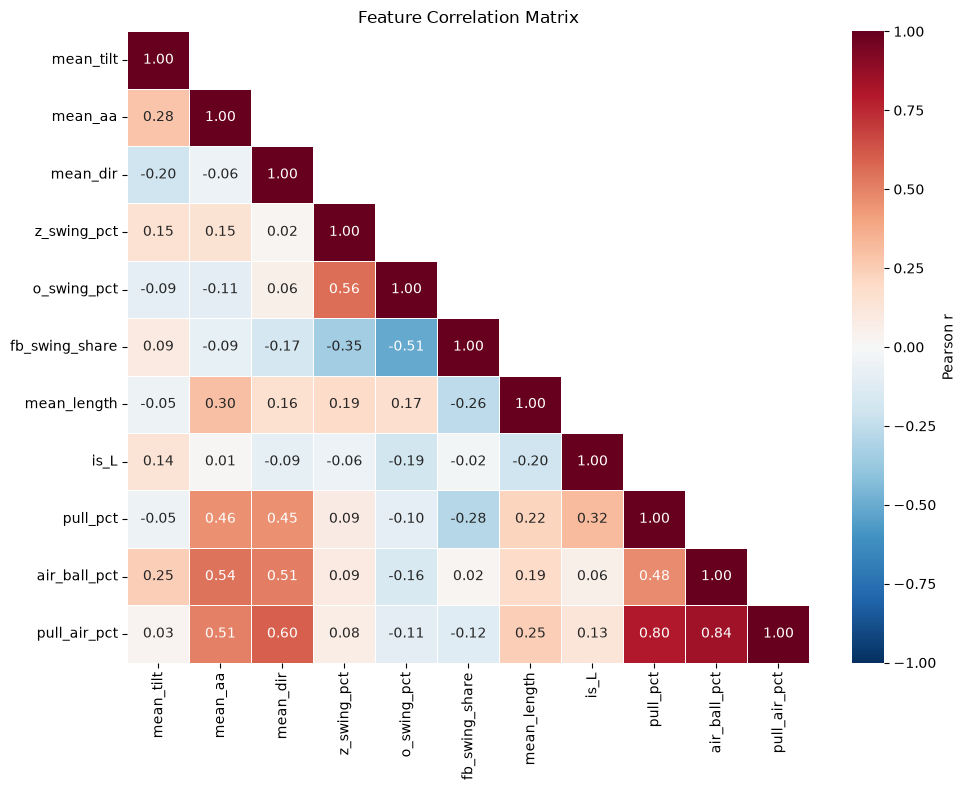

── Correlation with pull_air_pct, sorted ────────────────────────────────
air_ball_pct      0.8440
pull_pct          0.7990
mean_dir          0.5950
mean_aa           0.5080
mean_length       0.2460
is_L              0.1290
fb_swing_share   -0.1220
o_swing_pct      -0.1060
z_swing_pct       0.0770
mean_tilt         0.0270


In [63]:
# ── Correlation matrix: features + the three marginal/joint rates ──────────
corr_cols = ALL_FEATURES + ["pull_pct", "air_ball_pct", "pull_air_pct"]
corr_df = batter_df[corr_cols].apply(pd.to_numeric, errors="coerce")
corr_mat = corr_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Pearson r"})
ax.set_title("Feature Correlation Matrix")
plt.tight_layout(); plt.show()

print("── Correlation with pull_air_pct, sorted ────────────────────────────────")
print(corr_mat["pull_air_pct"].drop("pull_air_pct")
      .sort_values(key=lambda s: s.abs(), ascending=False).round(3).to_string())

In [64]:
assert "season" in bbe_full.columns, "Run the multi-season bbe_full build cell first."
print(f"Seasons in bbe_full: {sorted(bbe_full['season'].unique())}")

# Alias if bbe_full uses the older 'pull_air' column name instead of 'pull_air_bbe'
if "pull_air_bbe" not in bbe_full.columns and "pull_air" in bbe_full.columns:
    bbe_full["pull_air_bbe"] = bbe_full["pull_air"]

total_bbe = bbe_full.groupby("batter").size().rename("total_bbe_2022_2025")
qualified_batters = total_bbe[total_bbe >= 600].index

cp_fixed = bbe_full[bbe_full["batter"].isin(qualified_batters)].copy()
print(f"\nFixed cohort: {len(qualified_batters)} hitters with ≥600 BBE (2022-2025)")

Seasons in bbe_full: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

Fixed cohort: 324 hitters with ≥600 BBE (2022-2025)


In [65]:
print("bbe_full" in dir())
if "bbe_full" in dir():
    print(bbe_full.columns.tolist())

True
['pitch_type', 'game_date', 'release_speed', 'release_pos_x', 'release_pos_z', 'player_name', 'batter', 'pitcher', 'events', 'description', 'spin_dir', 'spin_rate_deprecated', 'break_angle_deprecated', 'break_length_deprecated', 'zone', 'des', 'game_type', 'stand', 'p_throws', 'home_team', 'away_team', 'type', 'hit_location', 'bb_type', 'balls', 'strikes', 'game_year', 'pfx_x', 'pfx_z', 'plate_x', 'plate_z', 'on_3b', 'on_2b', 'on_1b', 'outs_when_up', 'inning', 'inning_topbot', 'hc_x', 'hc_y', 'tfs_deprecated', 'tfs_zulu_deprecated', 'umpire', 'sv_id', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az', 'sz_top', 'sz_bot', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'release_spin_rate', 'release_extension', 'game_pk', 'fielder_2', 'fielder_3', 'fielder_4', 'fielder_5', 'fielder_6', 'fielder_7', 'fielder_8', 'fielder_9', 'release_pos_y', 'estimated_ba_using_speedangle', 'estimated_woba_using_speedangle', 'woba_value', 'woba_denom', 'babip_value', 'iso_value', 'launch_sp

In [66]:
def kr21_alpha(matrix):
    """matrix: N x K array of 0/1 outcomes, one row per hitter."""
    K = matrix.shape[1]
    item_variances = matrix.var(axis=0, ddof=1)
    row_totals = matrix.sum(axis=1)
    total_variance = row_totals.var(ddof=1)
    if total_variance == 0:
        return np.nan
    return (K / (K - 1)) * (1 - item_variances.sum() / total_variance)

def reliability_at_k_fixed(cp_df, k, n_draws=5, seed=SEED):
    """Same fixed cohort at every K (all have >=600 total BBE, so all qualify
    up to K=300) — isolates the effect of sample size from population change."""
    rng = np.random.default_rng(seed)
    batters = cp_df["batter"].unique()

    alphas = []
    for draw in range(n_draws):
        rows = []
        for b in batters:
            g = cp_df[cp_df["batter"] == b]
            sampled = g["pull_air_bbe"].sample(n=k, random_state=rng.integers(0, 1_000_000)).values
            rows.append(sampled)
        matrix = np.array(rows)
        alphas.append(kr21_alpha(matrix))
    return np.nanmean(alphas), len(batters)

# ── Sweep K up to 300, same fixed cohort throughout ─────────────────────────
K_VALUES = [25, 50, 75, 100, 150, 200, 250, 300]
results = []
for k in K_VALUES:
    alpha, n_hitters = reliability_at_k_fixed(cp_fixed, k)
    results.append({"K (BBE)": k, "KR-21 (α)": alpha, "n_hitters": n_hitters})
    print(f"K={k:>4}  α={alpha:.3f}  (n={n_hitters} hitters — fixed cohort)")

rel_df_fixed = pd.DataFrame(results).dropna()
print("\n── Reliability table (fixed cohort, ≥600 BBE 2022-2025) ────────────────")
print(rel_df_fixed.round(3).to_string(index=False))

for thresh in [0.5, 0.7, 0.8]:
    above = rel_df_fixed[rel_df_fixed["KR-21 (α)"] >= thresh]
    if len(above):
        print(f"\nα ≥ {thresh}: first reached at K = {above['K (BBE)'].iloc[0]} BBE")
    else:
        print(f"\nα ≥ {thresh}: not reached within tested range "
              f"(max K={rel_df_fixed['K (BBE)'].max()}, "
              f"α={rel_df_fixed['KR-21 (α)'].iloc[-1]:.3f})")

K=  25  α=0.287  (n=324 hitters — fixed cohort)
K=  50  α=0.453  (n=324 hitters — fixed cohort)
K=  75  α=0.556  (n=324 hitters — fixed cohort)
K= 100  α=0.619  (n=324 hitters — fixed cohort)
K= 150  α=0.700  (n=324 hitters — fixed cohort)
K= 200  α=0.751  (n=324 hitters — fixed cohort)
K= 250  α=0.788  (n=324 hitters — fixed cohort)
K= 300  α=0.819  (n=324 hitters — fixed cohort)

── Reliability table (fixed cohort, ≥600 BBE 2022-2025) ────────────────
 K (BBE)  KR-21 (α)  n_hitters
      25     0.2870        324
      50     0.4530        324
      75     0.5560        324
     100     0.6190        324
     150     0.7000        324
     200     0.7510        324
     250     0.7880        324
     300     0.8190        324

α ≥ 0.5: first reached at K = 75 BBE

α ≥ 0.7: first reached at K = 200 BBE

α ≥ 0.8: first reached at K = 300 BBE


In [67]:
# ══ Year-over-year stickiness, to compare against the KR-21 curve ══
assert "bbe_full" in dir(), "Run the multi-season bbe_full build cell first."
assert "season" in bbe_full.columns, "bbe_full needs 'season'."

# Alias if bbe_full uses the older 'pull_air' column name instead of 'pull_air_bbe'
if "pull_air_bbe" not in bbe_full.columns and "pull_air" in bbe_full.columns:
    bbe_full["pull_air_bbe"] = bbe_full["pull_air"]

season_agg = (bbe_full.groupby(["batter", "season"])
             .agg(n_bbe=("pull_air_bbe", "count"), pull_air_pct=("pull_air_bbe", "mean"))
             .reset_index())
season_agg = season_agg[season_agg["n_bbe"] >= MIN_BBE]
mean_season_bbe = season_agg["n_bbe"].mean()
print(f"Batter-seasons with ≥{MIN_BBE} BBE: {len(season_agg)}")
print(f"Mean BBE per qualifying season: {mean_season_bbe:.0f}")

seasons_sorted = sorted(season_agg["season"].unique())
pairs = []
for s in seasons_sorted[:-1]:
    y1 = season_agg[season_agg["season"] == s][["batter", "pull_air_pct"]].rename(
        columns={"pull_air_pct": "pa_y1"})
    y2 = season_agg[season_agg["season"] == s + 1][["batter", "pull_air_pct"]].rename(
        columns={"pull_air_pct": "pa_y2"})
    merged = y1.merge(y2, on="batter")
    merged["season_pair"] = f"{s}→{s+1}"
    pairs.append(merged)
stick = pd.concat(pairs, ignore_index=True)

print(f"\n── Year-over-year Pull Air% stickiness (corrected data) ────────────────")
for name, g in stick.groupby("season_pair"):
    r = spearmanr(g["pa_y1"], g["pa_y2"]).correlation
    print(f"  {name}: n={len(g)}, Spearman={r:.3f}")
r_pooled = spearmanr(stick["pa_y1"], stick["pa_y2"]).correlation
print(f"  Pooled: n={len(stick)}, Spearman={r_pooled:.3f}")

Batter-seasons with ≥150 BBE: 1348
Mean BBE per qualifying season: 316

── Year-over-year Pull Air% stickiness (corrected data) ────────────────
  2022→2023: n=244, Spearman=0.713
  2023→2024: n=260, Spearman=0.708
  2024→2025: n=245, Spearman=0.751
  Pooled: n=749, Spearman=0.726


In [68]:
# ── Slope and R² of the Year N+1 ~ Year N regression ────────────────────────
from scipy.stats import linregress

print(f"\n── OLS regression: Pull Air%(Year N+1) ~ Pull Air%(Year N) ─────────────")
for name, g in stick.groupby("season_pair"):
    lr = linregress(g["pa_y1"], g["pa_y2"])
    print(f"  {name}: slope={lr.slope:.3f}  intercept={lr.intercept:.3f}  "
          f"R²={lr.rvalue**2:.3f}  (n={len(g)})")

lr_pooled = linregress(stick["pa_y1"], stick["pa_y2"])
print(f"  Pooled:   slope={lr_pooled.slope:.3f}  intercept={lr_pooled.intercept:.3f}  "
      f"R²={lr_pooled.rvalue**2:.3f}  (n={len(stick)})")

print(f"\n── Three-way consistency check ──────────────────────────────────────────")
print(f"  Pooled Spearman r:        {r_pooled:.3f}")
print(f"  Pooled Pearson r:         {lr_pooled.rvalue:+.3f}")
print(f"  Pooled OLS slope:         {lr_pooled.slope:.3f}")
print(f"  R² (= Pearson r²):        {lr_pooled.rvalue**2:.3f}")
print("\n  Under classical test theory, if Y1 and Y2 have roughly equal variance,")
print("  slope ≈ Pearson r ≈ the reliability coefficient. Large gaps between")
print("  slope and Spearman r would flag nonlinearity or unequal season variance.")


── OLS regression: Pull Air%(Year N+1) ~ Pull Air%(Year N) ─────────────
  2022→2023: slope=0.775  intercept=0.046  R²=0.541  (n=244)
  2023→2024: slope=0.733  intercept=0.050  R²=0.527  (n=260)
  2024→2025: slope=0.796  intercept=0.044  R²=0.596  (n=245)
  Pooled:   slope=0.767  intercept=0.047  R²=0.554  (n=749)

── Three-way consistency check ──────────────────────────────────────────
  Pooled Spearman r:        0.726
  Pooled Pearson r:         +0.745
  Pooled OLS slope:         0.767
  R² (= Pearson r²):        0.554

  Under classical test theory, if Y1 and Y2 have roughly equal variance,
  slope ≈ Pearson r ≈ the reliability coefficient. Large gaps between
  slope and Spearman r would flag nonlinearity or unequal season variance.


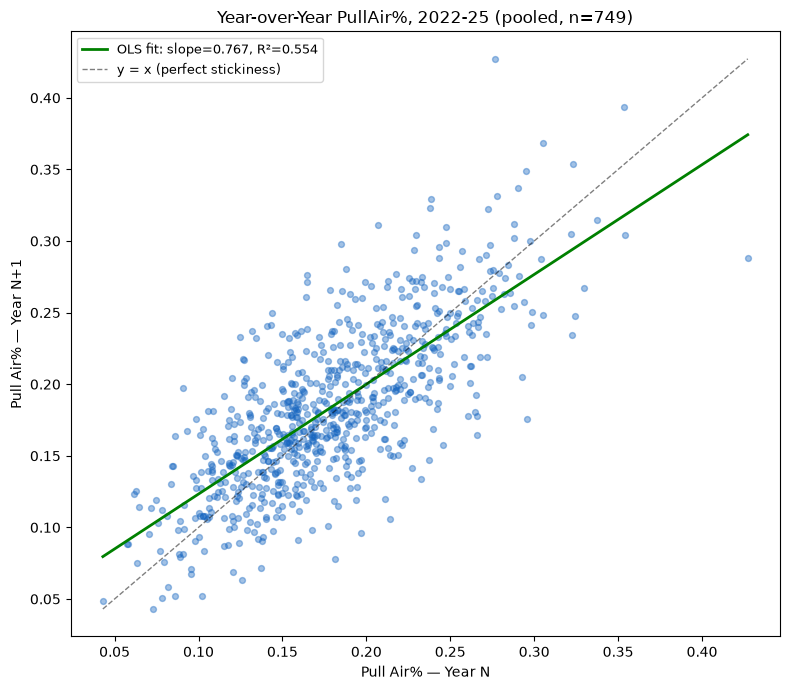

In [69]:
# ── Graph 1: Pooled scatter with OLS regression line + y=x reference ───────
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(stick["pa_y1"], stick["pa_y2"], s=18, alpha=0.4, color="#1565C0")

x_line = np.array([stick["pa_y1"].min(), stick["pa_y1"].max()])
y_line = lr_pooled.intercept + lr_pooled.slope * x_line
ax.plot(x_line, y_line, color="green", lw=2,
        label=f"OLS fit: slope={lr_pooled.slope:.3f}, R²={lr_pooled.rvalue**2:.3f}")
ax.plot(x_line, x_line, "k--", lw=1, alpha=0.5, label="y = x (perfect stickiness)")

ax.set_xlabel("Pull Air% — Year N")
ax.set_ylabel("Pull Air% — Year N+1")
ax.set_title(f"Year-over-Year PullAir%, 2022-25 (pooled, n={len(stick)})")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

In [70]:
# ══ Build quality-of-contact + power outcome at the batter level ══
# ISO = SLG - AVG isolates extra-base power specifically (cleaner target than
# raw SLG, which conflates power with hit frequency).

# ── Quality-of-contact inputs: bat speed, exit velo, hard-hit rate ──────────
qoc_needed = ["bat_speed", "launch_speed"]
qoc_available = [c for c in qoc_needed if c in cp.columns]
print(f"Quality-of-contact columns available in cp: {qoc_available}")

qoc_agg = cp.groupby("batter").agg(
    mean_bs = ("bat_speed",   "mean") if "bat_speed" in cp.columns else ("launch_speed", "mean"),
    mean_ev = ("launch_speed", "mean"),
    hard_hit_rate = ("launch_speed", lambda s: (s >= 95).mean()),
).reset_index()
if "bat_speed" not in cp.columns:
    qoc_agg = qoc_agg.drop(columns=["mean_bs"])
    print("WARNING: bat_speed not in cp — using exit velo + hard-hit rate only.")

# ── Power outcome: ISO, built from at-bat results ───────────────────────────
HIT_EVENTS = {"single", "double", "triple", "home_run"}
OUT_EVENTS = {"field_out", "force_out", "grounded_into_double_play", "double_play",
             "fielders_choice_out", "sac_fly", "sac_bunt", "triple_play"}

bat_res = cp[cp["events"].notna()].copy() if "events" in cp.columns else None
if bat_res is None:
    bat_res = bbe_full[bbe_full["events"].notna()].copy()   # fallback to multi-season source

bat_res["is_hit"] = bat_res["events"].isin(HIT_EVENTS).astype(int)
bat_res["bases"]  = bat_res["events"].map({
    "single": 1, "double": 2, "triple": 3, "home_run": 4}).fillna(0)
bat_res["at_bat"] = bat_res["events"].isin(HIT_EVENTS | OUT_EVENTS).astype(int)

power_agg = (bat_res[bat_res["at_bat"] == 1]
            .groupby("batter")
            .agg(n_ab = ("at_bat", "count"),
                 AVG  = ("is_hit", "mean"),
                 SLG  = ("bases",  "mean"))
            .reset_index())
power_agg["ISO"] = power_agg["SLG"] - power_agg["AVG"]

# ── Merge everything onto batter_df ──────────────────────────────────────────
power_df = (batter_df.merge(qoc_agg, on="batter", how="inner")
                     .merge(power_agg, on="batter", how="inner"))
power_df = power_df[power_df["n_ab"] >= 200]   # reasonable AB floor for ISO stability

print(f"\npower_df: {power_df.shape}")
print(power_df[["mean_ev", "hard_hit_rate", "ISO", "pull_air_pct"]].describe().round(3).to_string())

Quality-of-contact columns available in cp: ['bat_speed', 'launch_speed']

power_df: (419, 32)
       mean_ev  hard_hit_rate      ISO  pull_air_pct
count 419.0000       419.0000 419.0000      419.0000
mean   88.2730         0.3840   0.2080        0.1780
std     2.3830         0.0750   0.0710        0.0490
min    80.9490         0.1450   0.0400        0.0550
25%    86.7750         0.3380   0.1590        0.1480
50%    88.4080         0.3850   0.1970        0.1740
75%    89.9670         0.4390   0.2510        0.2090
max    95.7900         0.6000   0.5180        0.3330


In [71]:
# ── Add player_name to power_df (and batter_df generally) for real examples ─
name_source = None
for candidate in ["cp", "bbe_full", "raw_all"]:
    if candidate in dir() and "player_name" in eval(candidate).columns:
        name_source = eval(candidate)
        print(f"Using player_name from: {candidate}")
        break

assert name_source is not None, "player_name not found in cp/bbe_full/raw_all — check the source pull."

# player_name is typically "Last, First" — one name per batter, so take the first non-null
name_map = (name_source[["batter", "player_name"]]
           .dropna()
           .drop_duplicates(subset="batter")
           .rename(columns={"player_name": "name"}))

print(f"Names available for {len(name_map)} batters")
print(name_map.head())

Using player_name from: cp
Names available for 925 batters
         batter             name
1074736  686894   Finnegan, Kyle
1074742  680911   Finnegan, Kyle
1074759  671277    Wilson, Bryse
1074761  605170  Thompson, Mason
1074763  655316  Thompson, Mason


In [72]:
# ── Barrel: use Statcast's native launch_speed_angle field ─────────────────
# launch_speed_angle: 6 = Barrel (Statcast's official classification), values
# 1-5 are progressively lower contact-quality tiers.
assert "launch_speed_angle" in cp.columns, \
    "launch_speed_angle not found in cp — check the Statcast pull includes it."

cp["is_barrel"] = (cp["launch_speed_angle"] == 6).astype(int)

print(f"Barrel rate (BBE-level): {cp['is_barrel'].mean():.3f}  (real MLB rate ≈ 0.06-0.08)")
print(f"\nlaunch_speed_angle distribution:")
print(cp["launch_speed_angle"].value_counts().sort_index().to_string())

Barrel rate (BBE-level): 0.080  (real MLB rate ≈ 0.06-0.08)

launch_speed_angle distribution:
launch_speed_angle
1    11380
2    87581
3    75430
4    68263
5    17780
6    22697


In [73]:
# ── Rebuild QOC aggregation and power_df with the native barrel flag ───────
agg_dict = {
    "mean_ev":       ("launch_speed", "mean"),
    "hard_hit_rate": ("launch_speed", lambda s: (s >= 95).mean()),
    "barrel_rate":   ("is_barrel",    "mean"),
}
if "bat_speed" in cp.columns:
    agg_dict["mean_bs"] = ("bat_speed", "mean")
else:
    print("WARNING: bat_speed not in cp — QOC model will run without it.")

qoc_agg = cp.groupby("batter").agg(**agg_dict).reset_index()

# batter_df already has 'name' from the earlier merge — no need to merge
# name_map again here.
power_df = (batter_df.merge(qoc_agg, on="batter", how="inner")
                     .merge(power_agg, on="batter", how="inner"))
power_df = power_df[power_df["n_ab"] >= 200]

QOC_FEATS = [c for c in ["barrel_rate"]
             if c in power_df.columns]
print(f"Quality-of-contact features used: {QOC_FEATS}")
print(f"'name' present in power_df: {'name' in power_df.columns}")

X = power_df[QOC_FEATS].values
y = power_df["ISO"].values
groups_p = power_df["batter"].values
gkf_p = GroupKFold(n_splits=min(CV_FOLDS, power_df["batter"].nunique()))

pipe_qoc = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_iso = cross_val_predict(pipe_qoc, X, y, cv=gkf_p, groups=groups_p)
power_df["expected_ISO"] = pred_iso
power_df["ISO_overperformance"] = power_df["ISO"] - power_df["expected_ISO"]

r_fit = spearmanr(pred_iso, y).correlation
print(f"\nSpearman(expected ISO, actual ISO) = {r_fit:+.3f}")

pipe_qoc.fit(X, y)
coefs = pd.Series(pipe_qoc.named_steps["m"].coef_, index=QOC_FEATS).sort_values(
    key=lambda s: s.abs(), ascending=False)
print(f"\nStandardized coefficients (physical-tools model):")
print(coefs.round(4).to_string())

Quality-of-contact features used: ['barrel_rate']
'name' present in power_df: False

Spearman(expected ISO, actual ISO) = +0.904

Standardized coefficients (physical-tools model):
barrel_rate   0.0645


In [74]:
# ── Merge the CORRECT batter names onto power_df / batter_df ────────────────
if "name" in power_df.columns:
    power_df = power_df.drop(columns=["name"])
if "name" in batter_df.columns:
    batter_df = batter_df.drop(columns=["name"])

power_df = power_df.merge(name_map, on="batter", how="left")
batter_df = batter_df.merge(name_map, on="batter", how="left")

missing_names = power_df["name"].isna().sum()
print(f"Matched names: {len(power_df) - missing_names} of {len(power_df)}")
if missing_names:
    print(f"WARNING: {missing_names} batter IDs didn't resolve:")
    print(power_df.loc[power_df["name"].isna(), "batter"].tolist())

Matched names: 419 of 419


In [75]:
# ── The key test: does Pull Air% explain the OVERPERFORMANCE residual? ──────
r_overperf = spearmanr(power_df["pull_air_pct"], power_df["ISO_overperformance"]).correlation
r_overperf_pearson = power_df[["pull_air_pct", "ISO_overperformance"]].corr().iloc[0, 1]

print(f"── Does Pull Air% explain power BEYOND what contact quality predicts? ──")
print(f"  Spearman(Pull Air%, ISO overperformance) = {r_overperf:+.3f}")
print(f"  Pearson(Pull Air%, ISO overperformance)  = {r_overperf_pearson:+.3f}")

# Compare: correlation with RAW ISO vs the RESIDUAL — the gap is the story
r_raw = spearmanr(power_df["pull_air_pct"], power_df["ISO"]).correlation
print(f"\n  For comparison, Spearman(Pull Air%, raw ISO) = {r_raw:+.3f}")
print(f"  If overperformance correlation ≈ raw ISO correlation, Pull Air% is doing")
print(f"  real independent work beyond contact quality — not just proxying for it.")

── Does Pull Air% explain power BEYOND what contact quality predicts? ──
  Spearman(Pull Air%, ISO overperformance) = +0.457
  Pearson(Pull Air%, ISO overperformance)  = +0.491

  For comparison, Spearman(Pull Air%, raw ISO) = +0.426
  If overperformance correlation ≈ raw ISO correlation, Pull Air% is doing
  real independent work beyond contact quality — not just proxying for it.


In [76]:
# ── Get REAL batter names via pybaseball's ID lookup (Chadwick register) ────
from pybaseball import playerid_reverse_lookup

unique_batter_ids = power_df["batter"].dropna().unique().astype(int).tolist()
print(f"Looking up names for {len(unique_batter_ids)} batter IDs...")

lookup = playerid_reverse_lookup(unique_batter_ids, key_type="mlbam")
print(lookup.head())
print(f"\nMatched {len(lookup)} of {len(unique_batter_ids)} batter IDs")

name_map = lookup[["key_mlbam", "name_first", "name_last"]].copy()
name_map["name"] = name_map["name_first"].str.title() + " " + name_map["name_last"].str.title()
name_map = name_map.rename(columns={"key_mlbam": "batter"})[["batter", "name"]]

Looking up names for 419 batter IDs...
   name_last name_first  key_mlbam key_retro  key_bbref  key_fangraphs  \
0      edman      tommy     669242  edmat001  edmanto01          19470   
1  schneider      davis     676914  schnd001  schneda03          23565   
2     durbin      caleb     702332  durbc002  durbica01          29646   
3      lopez      nicky     670032  lopen001  lopezni01          19339   
4       lowe    brandon     664040  loweb001   lowebr01          18882   

   mlb_played_first  mlb_played_last  
0         2019.0000        2026.0000  
1         2023.0000        2026.0000  
2         2025.0000        2026.0000  
3         2019.0000        2026.0000  
4         2018.0000        2026.0000  

Matched 419 of 419 batter IDs


In [77]:
# ── Merge the CORRECT batter names onto power_df / batter_df ────────────────
# Drop the bad pitcher-name column first if it's already merged in
for df_name in ["power_df", "batter_df"]:
    df = eval(df_name)
    if "name" in df.columns:
        df = df.drop(columns=["name"])
    df = df.merge(name_map, on="batter", how="left")
    globals()[df_name] = df

missing_names = power_df["name"].isna().sum()
print(f"\nMatched names: {len(power_df) - missing_names} of {len(power_df)}")
if missing_names:
    print(f"WARNING: {missing_names} batter IDs didn't resolve — spot check these:")
    print(power_df.loc[power_df["name"].isna(), "batter"].tolist())


Matched names: 419 of 419


In [78]:
# ── Top overperformers and underperformers, with real names ─────────────────
out_cols = ["name", "stand", "quadrant", "pull_air_pct"] + QOC_FEATS + \
           ["ISO", "expected_ISO", "ISO_overperformance"]

print("── Top 15 overperformers (power beyond what contact quality predicts) ──")
top_over = power_df.sort_values("ISO_overperformance", ascending=False).head(15)
print(top_over[out_cols].round(3).to_string(index=False))

print("\n── Top 15 underperformers (power below what contact quality predicts) ──")
top_under = power_df.sort_values("ISO_overperformance").head(15)
print(top_under[out_cols].round(3).to_string(index=False))

── Top 15 overperformers (power beyond what contact quality predicts) ──
             name stand          quadrant  pull_air_pct  barrel_rate    ISO  expected_ISO  ISO_overperformance
   Daulton Varsho     L Both (Pull + Air)        0.2850       0.0950 0.3360        0.2360               0.1000
 Tyler Fitzgerald     R Both (Pull + Air)        0.2530       0.0620 0.2790        0.1800               0.0990
     Matt Wallner     L Both (Pull + Air)        0.2750       0.1700 0.4450        0.3560               0.0900
   Eugenio Suárez     R Both (Pull + Air)        0.2690       0.1250 0.3550        0.2820               0.0720
   Cedric Mullins     L Both (Pull + Air)        0.2540       0.0520 0.2290        0.1620               0.0670
   Corbin Carroll     L         Pull only        0.1820       0.0910 0.2940        0.2290               0.0650
    Triston Casas     L Both (Pull + Air)        0.2110       0.1170 0.3370        0.2720               0.0650
    Isaac Paredes     R Both (Pull + Ai

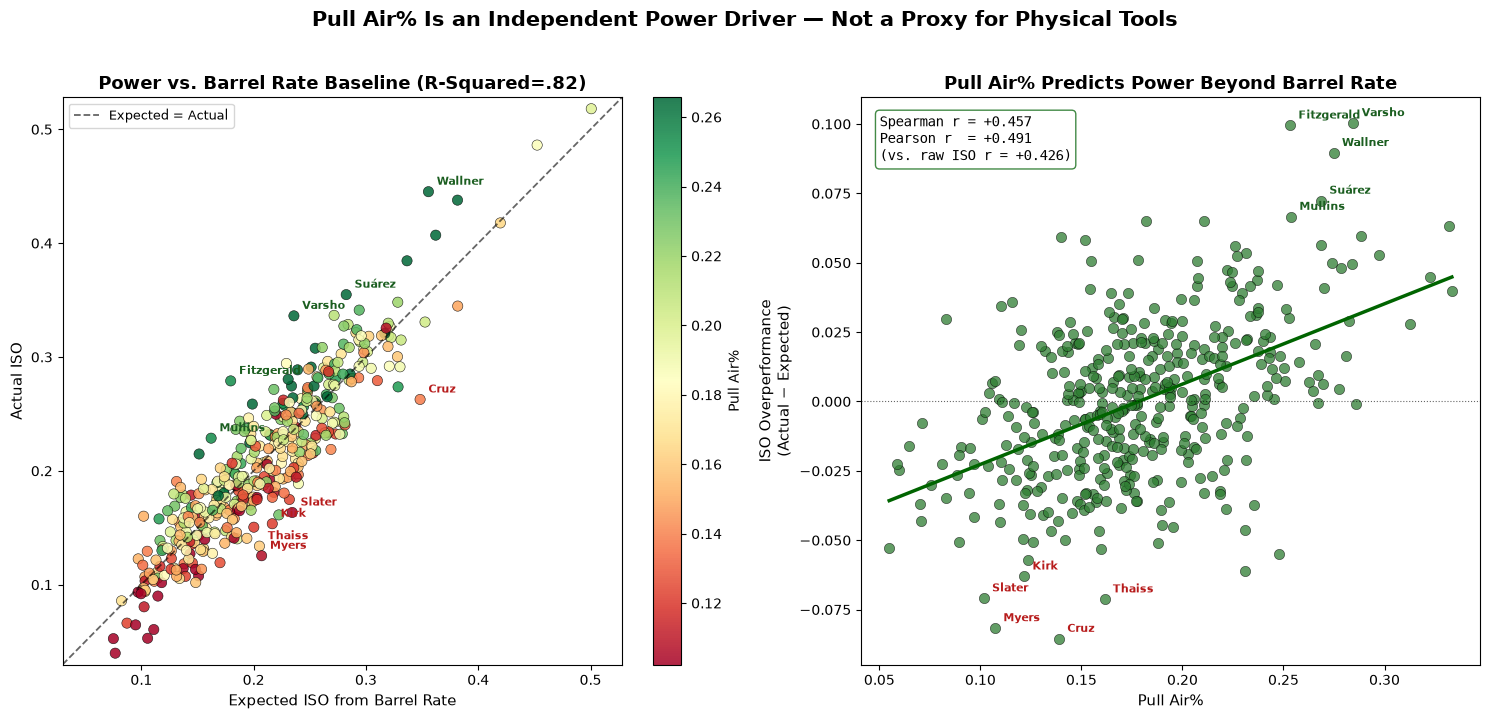

In [79]:
# ── Polished visual: does Pull Air% explain power beyond bat speed + barrels ─
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# ── Panel 1: Expected vs Actual ISO, colored by Pull Air% ──────────────────
ax = axes[0]
sc = ax.scatter(power_df["expected_ISO"], power_df["ISO"],
                c=power_df["pull_air_pct"], cmap="RdYlGn", s=55, alpha=0.85,
                edgecolor="black", linewidth=0.4, vmin=power_df["pull_air_pct"].quantile(0.05),
                vmax=power_df["pull_air_pct"].quantile(0.95))

lims = [min(power_df["expected_ISO"].min(), power_df["ISO"].min()) - 0.01,
        max(power_df["expected_ISO"].max(), power_df["ISO"].max()) + 0.01]
ax.plot(lims, lims, "k--", lw=1.3, alpha=0.6, label="Expected = Actual")
ax.set_xlim(lims); ax.set_ylim(lims)

# Label the biggest over/underperformers directly on the plot
top_labels = pd.concat([
    power_df.sort_values("ISO_overperformance", ascending=False).head(5),
    power_df.sort_values("ISO_overperformance").head(5),
])
for _, row in top_labels.iterrows():
    ax.annotate(row["name"].split()[-1] if isinstance(row["name"], str) else str(row["batter"]),
                (row["expected_ISO"], row["ISO"]),
                textcoords="offset points", xytext=(6, 5), fontsize=8, fontweight="bold",
                color="#1B5E20" if row["ISO_overperformance"] > 0 else "#B71C1C")

ax.set_xlabel("Expected ISO from Barrel Rate", fontsize=11)
ax.set_ylabel("Actual ISO", fontsize=11)
ax.set_title("Power vs. Barrel Rate Baseline (R-Squared=.82)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="upper left")
cbar = fig.colorbar(sc, ax=ax, fraction=0.046)
cbar.set_label("Pull Air%", fontsize=10)

# ── Panel 2: Pull Air% vs ISO overperformance, with trend + stat callout ───
ax = axes[1]
ax.scatter(power_df["pull_air_pct"], power_df["ISO_overperformance"],
           s=55, alpha=0.75, color="#2E7D32", edgecolor="black", linewidth=0.4)

z = np.polyfit(power_df["pull_air_pct"], power_df["ISO_overperformance"], 1)
x_fit = np.linspace(power_df["pull_air_pct"].min(), power_df["pull_air_pct"].max(), 50)
ax.plot(x_fit, np.polyval(z, x_fit), color="darkgreen", lw=2.5)
ax.axhline(0, color="black", lw=0.8, ls=":", alpha=0.6)

# Label the same standout hitters here too
for _, row in top_labels.iterrows():
    ax.annotate(row["name"].split()[-1] if isinstance(row["name"], str) else str(row["batter"]),
                (row["pull_air_pct"], row["ISO_overperformance"]),
                textcoords="offset points", xytext=(6, 5), fontsize=8, fontweight="bold",
                color="#1B5E20" if row["ISO_overperformance"] > 0 else "#B71C1C")

ax.set_xlabel("Pull Air%", fontsize=11)
ax.set_ylabel("ISO Overperformance\n(Actual − Expected)", fontsize=11)
ax.set_title("Pull Air% Predicts Power Beyond Barrel Rate",
             fontsize=13, fontweight="bold")

# Stat callout box
stat_text = (f"Spearman r = {r_overperf:+.3f}\n"
            f"Pearson r  = {r_overperf_pearson:+.3f}\n"
            f"(vs. raw ISO r = {r_raw:+.3f})")
ax.text(0.03, 0.97, stat_text, transform=ax.transAxes, fontsize=10,
        va="top", ha="left", family="monospace",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="#2E7D32", alpha=0.9))

plt.suptitle("Pull Air% Is an Independent Power Driver — Not a Proxy for Physical Tools",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

── Bat speed vs Barrel rate ─────────────────────────────────────────────
  Spearman r = +0.759
  Pearson r  = +0.769


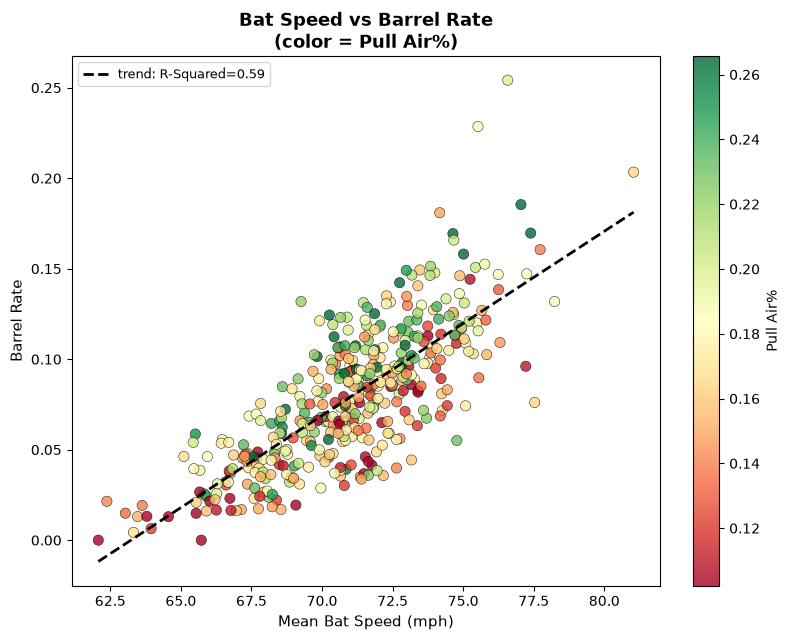

In [80]:
# ── Bat speed vs barrel rate: correlation + visual ──────────────────────────
r_bs_barrel = spearmanr(power_df["mean_bs"], power_df["barrel_rate"]).correlation
r_bs_barrel_pearson = power_df[["mean_bs", "barrel_rate"]].corr().iloc[0, 1]

print(f"── Bat speed vs Barrel rate ─────────────────────────────────────────────")
print(f"  Spearman r = {r_bs_barrel:+.3f}")
print(f"  Pearson r  = {r_bs_barrel_pearson:+.3f}")

fig, ax = plt.subplots(figsize=(8, 6.5))
sc = ax.scatter(power_df["mean_bs"], power_df["barrel_rate"],
                c=power_df["pull_air_pct"], cmap="RdYlGn", s=55, alpha=0.8,
                edgecolor="black", linewidth=0.4,
                vmin=power_df["pull_air_pct"].quantile(0.05),
                vmax=power_df["pull_air_pct"].quantile(0.95))

z = np.polyfit(power_df["mean_bs"], power_df["barrel_rate"], 1)
x_fit = np.linspace(power_df["mean_bs"].min(), power_df["mean_bs"].max(), 50)
ax.plot(x_fit, np.polyval(z, x_fit), color="black", lw=2, ls="--",
        label=f"trend: R-Squared={r_bs_barrel_pearson**2:.2f}")

ax.set_xlabel("Mean Bat Speed (mph)", fontsize=11)
ax.set_ylabel("Barrel Rate", fontsize=11)
ax.set_title("Bat Speed vs Barrel Rate\n(color = Pull Air%)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
cbar = fig.colorbar(sc, ax=ax, fraction=0.046)
cbar.set_label("Pull Air%", fontsize=10)
plt.tight_layout()
plt.show()

In [81]:
# ── Fit expected barrel_rate from bat speed ALONE (single-input baseline) ──
X_bs = power_df[["mean_bs"]].values
y_barrel = power_df["barrel_rate"].values
groups_p = power_df["batter"].values
gkf_p = GroupKFold(n_splits=min(CV_FOLDS, power_df["batter"].nunique()))

pipe_bs = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_barrel = cross_val_predict(pipe_bs, X_bs, y_barrel, cv=gkf_p, groups=groups_p)

power_df["expected_barrel_rate"] = pred_barrel
power_df["barrel_overperformance"] = power_df["barrel_rate"] - power_df["expected_barrel_rate"]

r_fit_barrel = spearmanr(pred_barrel, y_barrel).correlation
print(f"Spearman(expected barrel_rate from bat speed, actual barrel_rate) = {r_fit_barrel:+.3f}")
print(f"  (this is how much of barrel rate bat speed alone explains)")

Spearman(expected barrel_rate from bat speed, actual barrel_rate) = +0.758
  (this is how much of barrel rate bat speed alone explains)


In [82]:
# ── Does Air% / Pull Air% explain the bat-speed->barrel_rate residual? ─────
for target_name, target_col in [("Air%", "air_ball_pct"), ("Pull Air%", "pull_air_pct")]:
    r_overperf = spearmanr(power_df[target_col], power_df["barrel_overperformance"]).correlation
    r_overperf_p = power_df[[target_col, "barrel_overperformance"]].corr().iloc[0, 1]
    r_raw = spearmanr(power_df[target_col], power_df["barrel_rate"]).correlation

    print(f"── {target_name} vs Barrel Rate overperformance (residual from bat speed) ──")
    print(f"  Spearman(({target_name}), barrel overperformance) = {r_overperf:+.3f}")
    print(f"  Pearson  = {r_overperf_p:+.3f}")
    print(f"  For comparison, Spearman({target_name}, raw barrel_rate) = {r_raw:+.3f}")
    print(f"  {'Holds up' if abs(r_overperf) >= abs(r_raw)*0.8 else 'Weakens'} after controlling for bat speed\n")

── Air% vs Barrel Rate overperformance (residual from bat speed) ──
  Spearman((Air%), barrel overperformance) = +0.463
  Pearson  = +0.435
  For comparison, Spearman(Air%, raw barrel_rate) = +0.323
  Holds up after controlling for bat speed

── Pull Air% vs Barrel Rate overperformance (residual from bat speed) ──
  Spearman((Pull Air%), barrel overperformance) = +0.325
  Pearson  = +0.321
  For comparison, Spearman(Pull Air%, raw barrel_rate) = +0.264
  Holds up after controlling for bat speed



In [83]:
# ── Nested comparison: does Pull Air% add anything BEYOND Air% alone? ──────
# Air% is close to a direct barrel ingredient (barrels need a specific launch
# window), so it likely explains most of the residual on its own. This tests
# whether pulling ALSO matters, on top of just getting the ball in the air.

X_air = power_df[["air_ball_pct"]].values
pred_barrel_from_air = cross_val_predict(
    Pipeline([("s", StandardScaler()), ("m", LinearRegression())]),
    X_air, power_df["barrel_overperformance"].values, cv=gkf_p, groups=groups_p)
resid_after_air = power_df["barrel_overperformance"].values - pred_barrel_from_air

r_pull_after_air = spearmanr(power_df["pull_air_pct"], resid_after_air).correlation
print(f"── Does Pull Air% explain barrel overperformance BEYOND Air% alone? ────")
print(f"  Spearman(Pull Air%, barrel overperf. residual after removing Air%) = "
      f"{r_pull_after_air:+.3f}")
print(f"  If this is near zero, Pull Air%'s barrel-overperformance signal was")
print(f"  entirely coming from the Air% component, not the Pull side.")

── Does Pull Air% explain barrel overperformance BEYOND Air% alone? ────
  Spearman(Pull Air%, barrel overperf. residual after removing Air%) = -0.072
  If this is near zero, Pull Air%'s barrel-overperformance signal was
  entirely coming from the Air% component, not the Pull side.


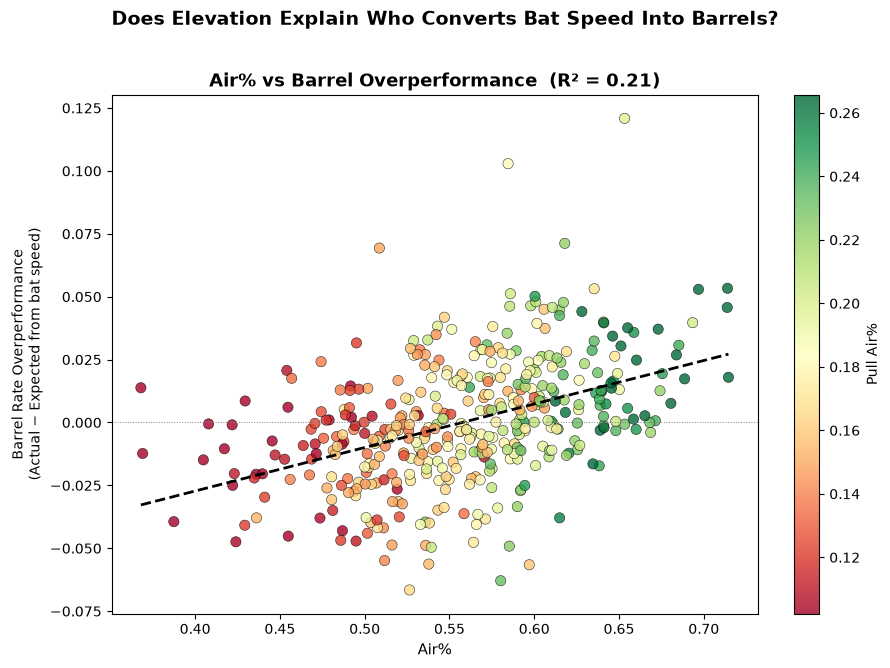

In [84]:
# ── Visual: Air% vs Barrel Overperformance ──────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6.5))

col = "air_ball_pct"
sc = ax.scatter(power_df[col], power_df["barrel_overperformance"],
                c=power_df["pull_air_pct"], cmap="RdYlGn", s=55, alpha=0.8,
                edgecolor="black", linewidth=0.4,
                vmin=power_df["pull_air_pct"].quantile(0.05),
                vmax=power_df["pull_air_pct"].quantile(0.95))

z = np.polyfit(power_df[col], power_df["barrel_overperformance"], 1)
x_fit = np.linspace(power_df[col].min(), power_df[col].max(), 50)
ax.plot(x_fit, np.polyval(z, x_fit), color="black", lw=2, ls="--")
ax.axhline(0, color="gray", lw=0.7, ls=":")

r = spearmanr(power_df[col], power_df["barrel_overperformance"]).correlation
ax.set_xlabel("Air%", fontsize=11)
ax.set_ylabel("Barrel Rate Overperformance\n(Actual − Expected from bat speed)", fontsize=10)
ax.set_title(f"Air% vs Barrel Overperformance  (R² = {r**2:.2f})",
             fontsize=13, fontweight="bold")

cbar = fig.colorbar(sc, ax=ax, fraction=0.046)
cbar.set_label("Pull Air%", fontsize=10)

plt.suptitle("Does Elevation Explain Who Converts Bat Speed Into Barrels?",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [85]:
# ── Fit expected ISO from bat speed ALONE (single-input baseline) ──────────
X_bs = power_df[["mean_bs"]].values
y_iso = power_df["ISO"].values
groups_p = power_df["batter"].values
gkf_p = GroupKFold(n_splits=min(CV_FOLDS, power_df["batter"].nunique()))

pipe_bs_iso = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_iso_from_bs = cross_val_predict(pipe_bs_iso, X_bs, y_iso, cv=gkf_p, groups=groups_p)

power_df["expected_ISO_from_bs"] = pred_iso_from_bs
power_df["ISO_overperf_from_bs"] = power_df["ISO"] - power_df["expected_ISO_from_bs"]

r_fit_bs_iso = spearmanr(pred_iso_from_bs, y_iso).correlation
print(f"Spearman(expected ISO from bat speed alone, actual ISO) = {r_fit_bs_iso:+.3f}")
print(f"  (how much of power bat speed alone explains, before any swing decisions)")

Spearman(expected ISO from bat speed alone, actual ISO) = +0.682
  (how much of power bat speed alone explains, before any swing decisions)


In [86]:
# ── Does Air% / Pull Air% explain the bat-speed→ISO residual? ──────────────
for target_name, target_col in [("Air%", "air_ball_pct"), ("Pull Air%", "pull_air_pct")]:
    r_overperf = spearmanr(power_df[target_col], power_df["ISO_overperf_from_bs"]).correlation
    r_overperf_p = power_df[[target_col, "ISO_overperf_from_bs"]].corr().iloc[0, 1]
    r_raw = spearmanr(power_df[target_col], power_df["ISO"]).correlation

    print(f"── {target_name} vs ISO overperformance (residual from bat speed alone) ──")
    print(f"  Spearman({target_name}, ISO overperformance) = {r_overperf:+.3f}")
    print(f"  Pearson  = {r_overperf_p:+.3f}")
    print(f"  For comparison, Spearman({target_name}, raw ISO) = {r_raw:+.3f}")
    print(f"  {'Holds up' if abs(r_overperf) >= abs(r_raw)*0.8 else 'Weakens'} after controlling for bat speed\n")

── Air% vs ISO overperformance (residual from bat speed alone) ──
  Spearman(Air%, ISO overperformance) = +0.580
  Pearson  = +0.564
  For comparison, Spearman(Air%, raw ISO) = +0.442
  Holds up after controlling for bat speed

── Pull Air% vs ISO overperformance (residual from bat speed alone) ──
  Spearman(Pull Air%, ISO overperformance) = +0.524
  Pearson  = +0.536
  For comparison, Spearman(Pull Air%, raw ISO) = +0.426
  Holds up after controlling for bat speed



In [87]:
# ── Nested comparison: does Pull Air% add anything BEYOND Air% alone here? ─
X_air = power_df[["air_ball_pct"]].values
pred_iso_overperf_from_air = cross_val_predict(
    Pipeline([("s", StandardScaler()), ("m", LinearRegression())]),
    X_air, power_df["ISO_overperf_from_bs"].values, cv=gkf_p, groups=groups_p)
resid_after_air_iso = power_df["ISO_overperf_from_bs"].values - pred_iso_overperf_from_air

r_pull_after_air_iso = spearmanr(power_df["pull_air_pct"], resid_after_air_iso).correlation
print(f"── Does Pull Air% explain ISO overperformance BEYOND Air% alone? ───────")
print(f"  Spearman(Pull Air%, ISO overperf. residual after removing Air%) = "
      f"{r_pull_after_air_iso:+.3f}")
print(f"  A positive result here (unlike the barrel-rate version) would mean")
print(f"  pulling adds POWER value beyond elevation, even though it added")
print(f"  nothing to barrel CONVERSION beyond elevation.")

── Does Pull Air% explain ISO overperformance BEYOND Air% alone? ───────
  Spearman(Pull Air%, ISO overperf. residual after removing Air%) = +0.056
  A positive result here (unlike the barrel-rate version) would mean
  pulling adds POWER value beyond elevation, even though it added
  nothing to barrel CONVERSION beyond elevation.


In [88]:
# ── Does Air% explain the ISO overperformance beyond bat speed + barrel rate,
#    the same test Pull Air% passed earlier? ────────────────────────────────
r_air_vs_full_overperf = spearmanr(power_df["air_ball_pct"],
                                   power_df["ISO_overperformance"]).correlation
print(f"Spearman(Air%, ISO overperformance from bat speed + barrel rate) = "
      f"{r_air_vs_full_overperf:+.3f}")
print(f"(compare to Pull Air%'s result on the same test: {r_overperf:+.3f})")

# And the decisive nested check: does PULL (isolated) add anything to ISO
# beyond Air%, controlling for bat speed + barrel rate together?
X_full = power_df[["mean_bs", "barrel_rate", "air_ball_pct"]].values
pred_iso_full = cross_val_predict(
    Pipeline([("s", StandardScaler()), ("m", LinearRegression())]),
    X_full, power_df["ISO"].values, cv=gkf_p, groups=groups_p)
resid_full = power_df["ISO"].values - pred_iso_full
r_pull_final = spearmanr(power_df["pull_air_pct"], resid_full).correlation
print(f"\nSpearman(Pull Air%, ISO residual after bat speed + barrel rate + Air%) = "
      f"{r_pull_final:+.3f}")
print("If this is near zero, Pull Air%'s ENTIRE power story was Air% riding")
print("along inside the composite metric — Pull itself adds nothing at any stage.")

Spearman(Air%, ISO overperformance from bat speed + barrel rate) = +0.365
(compare to Pull Air%'s result on the same test: +0.524)

Spearman(Pull Air%, ISO residual after bat speed + barrel rate + Air%) = +0.157
If this is near zero, Pull Air%'s ENTIRE power story was Air% riding
along inside the composite metric — Pull itself adds nothing at any stage.


In [89]:
# ── Fit expected ISO from BARREL RATE ALONE ─────────────────────────────────
X_barrel = power_df[["barrel_rate"]].values
y_iso = power_df["ISO"].values
groups_p = power_df["batter"].values
gkf_p = GroupKFold(n_splits=min(CV_FOLDS, power_df["batter"].nunique()))

pipe_barrel_iso = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_iso_from_barrel = cross_val_predict(pipe_barrel_iso, X_barrel, y_iso, cv=gkf_p, groups=groups_p)

power_df["expected_ISO_from_barrel"] = pred_iso_from_barrel
power_df["resid_barrel"] = power_df["ISO"] - power_df["expected_ISO_from_barrel"]

r_fit = spearmanr(pred_iso_from_barrel, y_iso).correlation
print(f"Spearman(expected ISO from barrel rate alone, actual ISO) = {r_fit:+.3f}")
print(f"Spearman(Pull Air%, resid_barrel) = "
      f"{spearmanr(power_df['pull_air_pct'], power_df['resid_barrel']).correlation:+.3f}")

Spearman(expected ISO from barrel rate alone, actual ISO) = +0.904
Spearman(Pull Air%, resid_barrel) = +0.457


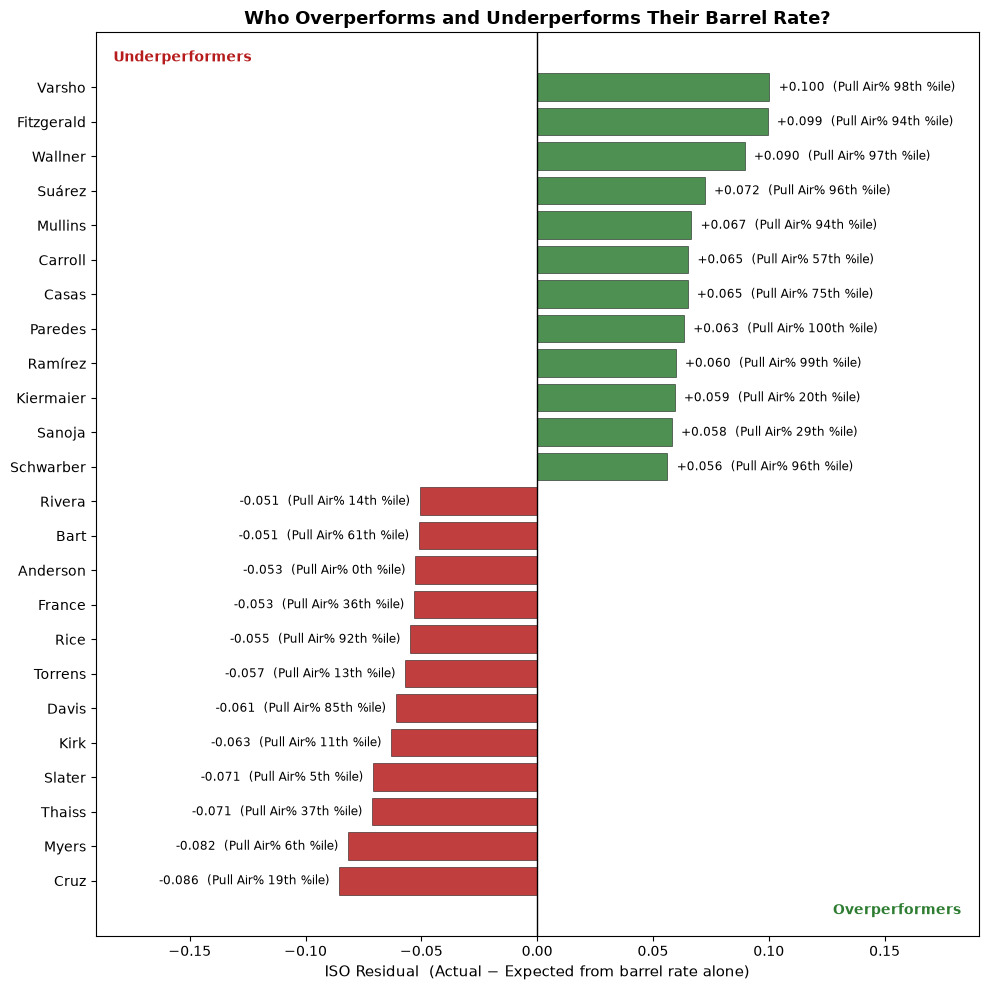

In [90]:
# ── Add Pull Air% percentile rank ────────────────────────────────────────────
power_df["pull_air_pctile"] = power_df["pull_air_pct"].rank(pct=True) * 100

# ── Top/bottom overperformers on the Barrel% -> ISO residual ───────────────
N_SHOW = 12
top_over = power_df.nlargest(N_SHOW, "resid_barrel").copy()
top_under = power_df.nsmallest(N_SHOW, "resid_barrel").copy()
combined = pd.concat([top_over, top_under]).sort_values("resid_barrel")

combined["display_name"] = combined["name"].apply(
    lambda s: s.split()[-1] if isinstance(s, str) else "Unknown")
combined["color"] = np.where(combined["resid_barrel"] > 0, "#2E7D32", "#B71C1C")

fig, ax = plt.subplots(figsize=(10, 10))
bars = ax.barh(combined["display_name"], combined["resid_barrel"],
               color=combined["color"], alpha=0.85, edgecolor="black", linewidth=0.4)

x_max = combined["resid_barrel"].abs().max()
ax.set_xlim(-x_max * 1.9, x_max * 1.9)

for b, (_, row) in zip(bars, combined.iterrows()):
    val = row["resid_barrel"]
    offset = x_max * 0.04
    label_x = val + offset if val > 0 else val - offset
    ha = "left" if val > 0 else "right"
    ax.text(label_x, b.get_y() + b.get_height()/2,
            f"{val:+.3f}  (Pull Air% {row['pull_air_pctile']:.0f}th %ile)",
            va="center", ha=ha, fontsize=8.5)

ax.axvline(0, color="black", lw=1)
ax.set_xlabel("ISO Residual  (Actual − Expected from barrel rate alone)", fontsize=11)
ax.set_title("Who Overperforms and Underperforms Their Barrel Rate?",
             fontsize=13, fontweight="bold")
ax.text(0.98, 0.02, "Overperformers", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=10, fontweight="bold", color="#2E7D32")
ax.text(0.02, 0.98, "Underperformers", transform=ax.transAxes, ha="left", va="top",
        fontsize=10, fontweight="bold", color="#B71C1C")
plt.tight_layout()
plt.show()

Features to plot: ['mean_tilt', 'mean_aa', 'mean_dir', 'z_swing_pct', 'o_swing_pct', 'fb_swing_share', 'mean_length', 'is_L', 'outer_swing_rate', 'inner_swing_rate', 'mean_depth', 'ideal_contact_depth_rate']
n = 496 hitters with complete data


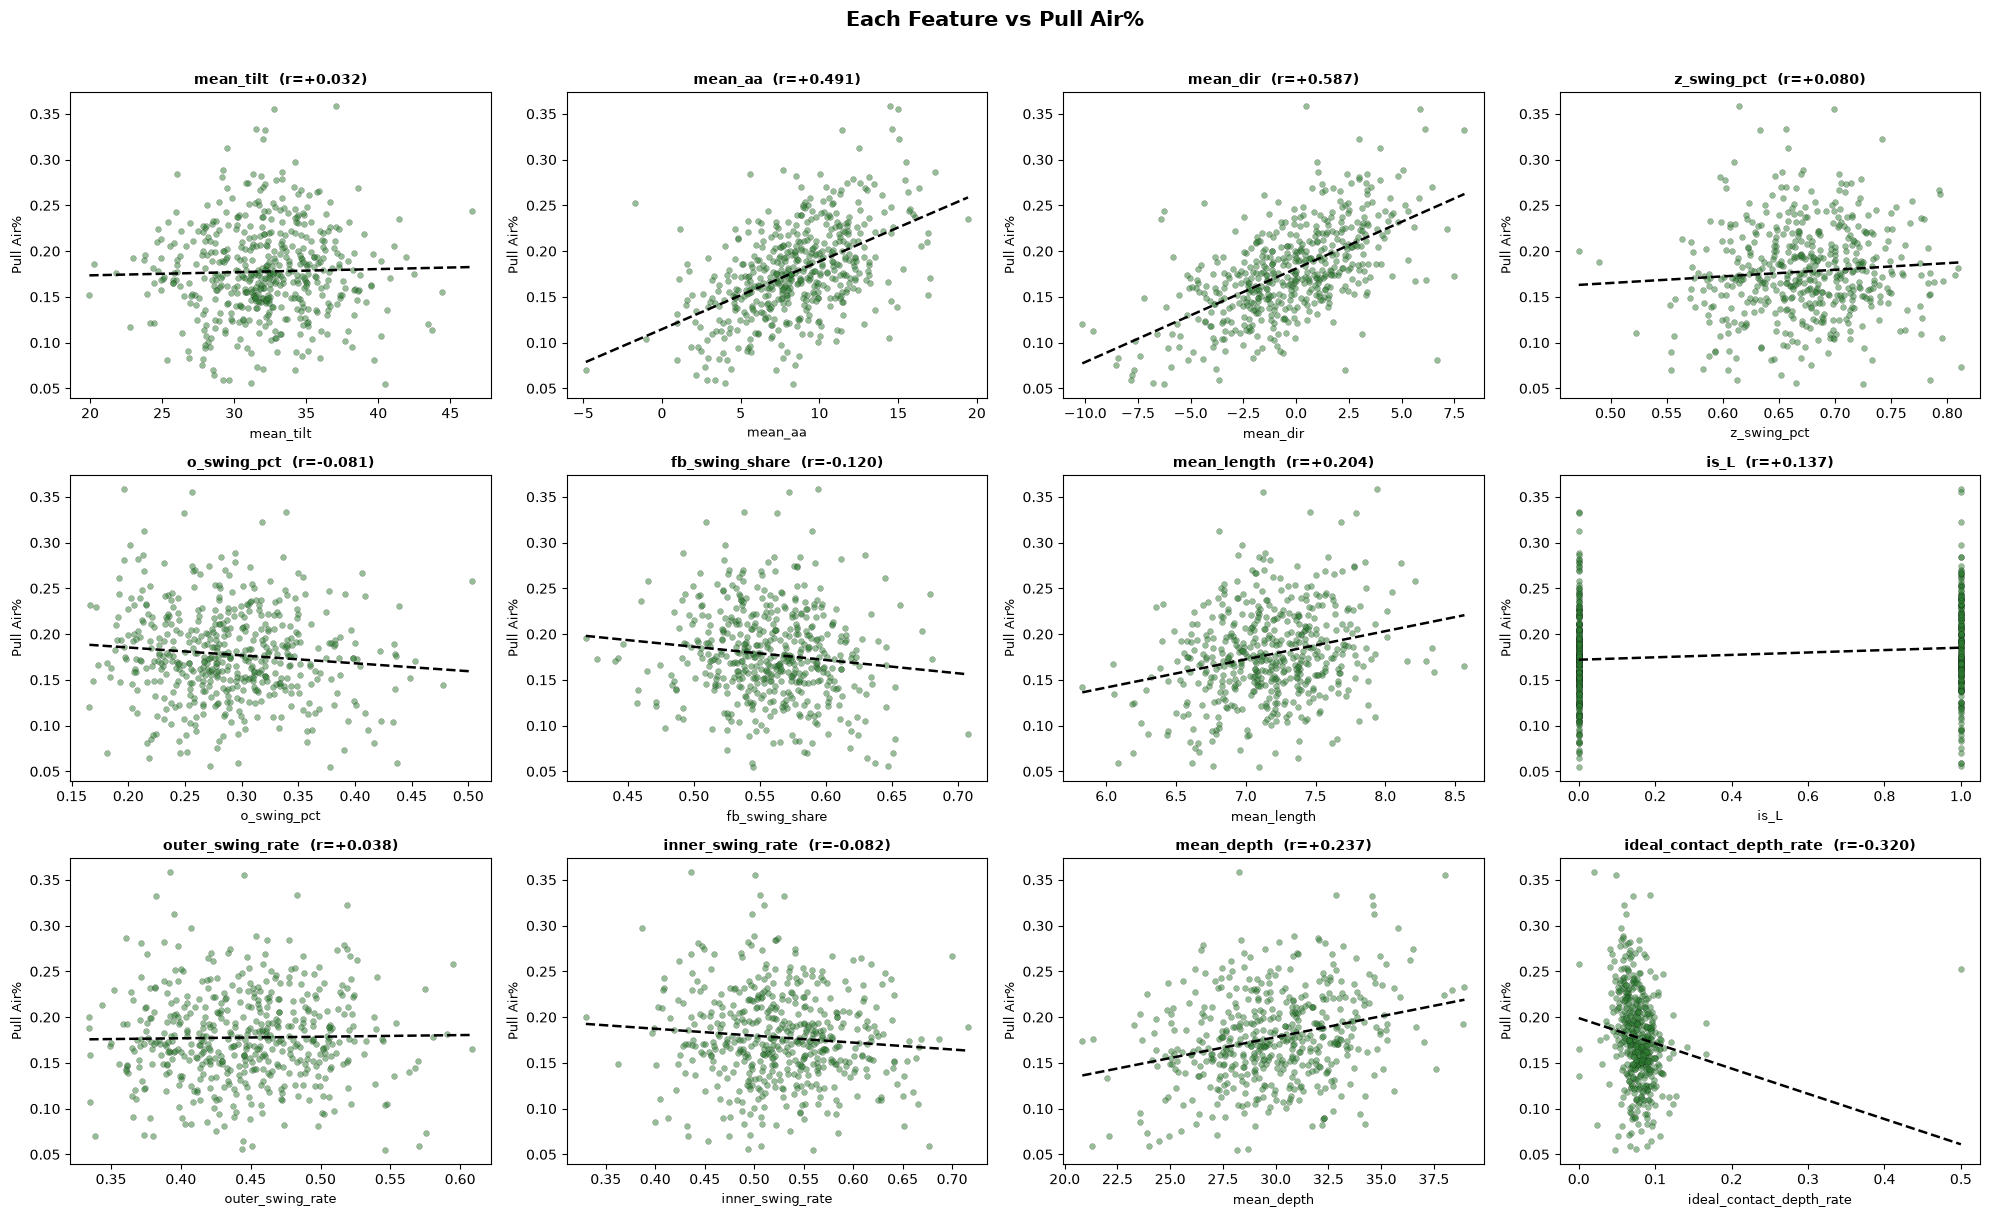

In [91]:
# ── Scatterplots: each feature vs Pull Air% ─────────────────────────────────
REG_FEATS = [f for f in ALL_FEATURES + ["outer_swing_rate", "inner_swing_rate",
                                        "mean_depth", "ideal_contact_depth_rate"]
             if f in batter_df.columns]
print(f"Features to plot: {REG_FEATS}")

plot_df = batter_df.dropna(subset=REG_FEATS + ["pull_air_pct"]).copy()
print(f"n = {len(plot_df)} hitters with complete data")

n_feats = len(REG_FEATS)
n_cols = 4
n_rows = int(np.ceil(n_feats / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
axes = axes.flatten()

for ax, feat in zip(axes, REG_FEATS):
    ax.scatter(plot_df[feat], plot_df["pull_air_pct"], s=18, alpha=0.5, color="#2E7D32",
               edgecolor="black", linewidth=0.2)
    z = np.polyfit(plot_df[feat], plot_df["pull_air_pct"], 1)
    x_fit = np.linspace(plot_df[feat].min(), plot_df[feat].max(), 50)
    ax.plot(x_fit, np.polyval(z, x_fit), color="black", lw=1.8, ls="--")
    r = spearmanr(plot_df[feat], plot_df["pull_air_pct"]).correlation
    ax.set_xlabel(feat, fontsize=9)
    ax.set_ylabel("Pull Air%", fontsize=9)
    ax.set_title(f"{feat}  (r={r:+.3f})", fontsize=10, fontweight="bold")

# Hide any unused subplot axes
for ax in axes[n_feats:]:
    ax.axis("off")

plt.suptitle("Each Feature vs Pull Air%", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [174]:
TRIM_FEATS = [f for f in REG_FEATS if f not in ["pull_air_pct", "air_ball_pct", "o_swing_pct", "z_swing_pct", "ideal_contact_depth_rate", "inner_swing_rate", "outer_swing_rate", "fb_swing_share", "mean_length", "mean_depth"]]

In [175]:
# ── Linear Regression: predict Pull Air% from all features ─────────────────
X = plot_df[TRIM_FEATS].values
y = plot_df["pull_air_pct"].values
groups_reg = plot_df["batter"].values
gkf_reg = GroupKFold(n_splits=min(CV_FOLDS, plot_df["batter"].nunique()))

pipe_lr = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_lr = cross_val_predict(pipe_lr, X, y, cv=gkf_reg, groups=groups_reg)

sp = spearmanr(pred_lr, y).correlation
pr = pearsonr(pred_lr, y)[0]
rmse = np.sqrt(np.mean((pred_lr - y) ** 2))

print(f"── Linear Regression: Pull Air% ~ {len(TRIM_FEATS)} features ─────────────")
print(f"R-Squared = {sp**2:.2f}")

# Fit on full data for interpretable coefficients
pipe_lr.fit(X, y)
coefs = pd.Series(pipe_lr.named_steps["m"].coef_, index=TRIM_FEATS).sort_values(
    key=lambda s: s.abs(), ascending=False)
print(f"\n── Standardized coefficients ────────────────────────────────────────────")
print(coefs.round(4).to_string())

── Linear Regression: Pull Air% ~ 4 features ─────────────
R-Squared = 0.66

── Standardized coefficients ────────────────────────────────────────────
mean_dir     0.0318
mean_aa      0.0275
is_L         0.0091
mean_tilt   -0.0015


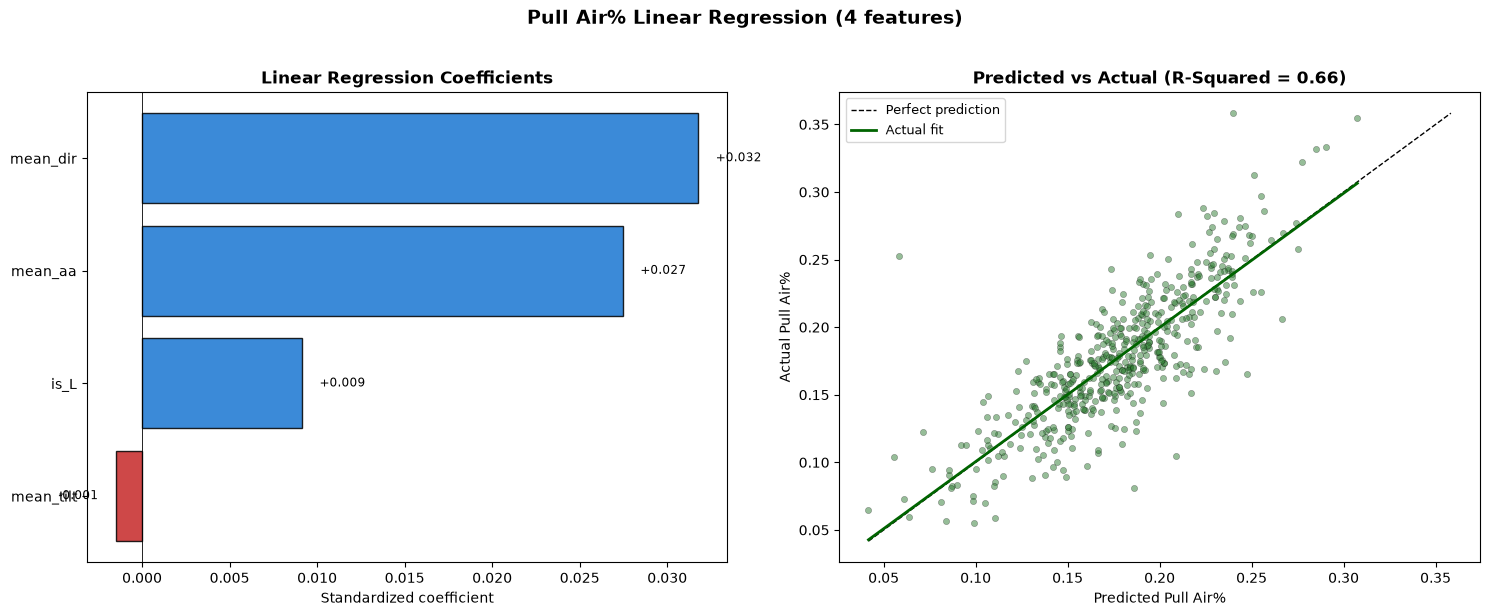

In [176]:
# ── Visual: coefficient bar chart + predicted vs actual ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, max(6, 0.4 * len(TRIM_FEATS))))

colors = ["#1976D2" if v > 0 else "#C62828" for v in coefs.values[::-1]]
axes[0].barh(coefs.index[::-1], coefs.values[::-1], color=colors, alpha=0.85, edgecolor="black")
axes[0].axvline(0, color="black", lw=0.6)
for i, v in enumerate(coefs.values[::-1]):
    axes[0].text(v + np.sign(v)*0.001, i, f"{v:+.3f}", va="center",
                ha="left" if v > 0 else "right", fontsize=8.5)
axes[0].set_xlabel("Standardized coefficient")
axes[0].set_title("Linear Regression Coefficients", fontsize=12, fontweight="bold")

axes[1].scatter(pred_lr, y, s=20, alpha=0.5, color="#2E7D32", edgecolor="black", linewidth=0.3)
lims = [min(pred_lr.min(), y.min()), max(pred_lr.max(), y.max())]
axes[1].plot(lims, lims, "k--", lw=1, label="Perfect prediction")
z = np.polyfit(pred_lr, y, 1)
x_fit = np.linspace(pred_lr.min(), pred_lr.max(), 50)
axes[1].plot(x_fit, np.polyval(z, x_fit), color="darkgreen", lw=2, label="Actual fit")
axes[1].set_xlabel("Predicted Pull Air%")
axes[1].set_ylabel("Actual Pull Air%")
axes[1].set_title(f"Predicted vs Actual (R-Squared = {sp**2:.2f})",
                  fontsize=12, fontweight="bold")
axes[1].legend(fontsize=9)

plt.suptitle(f"Pull Air% Linear Regression ({len(TRIM_FEATS)} features)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

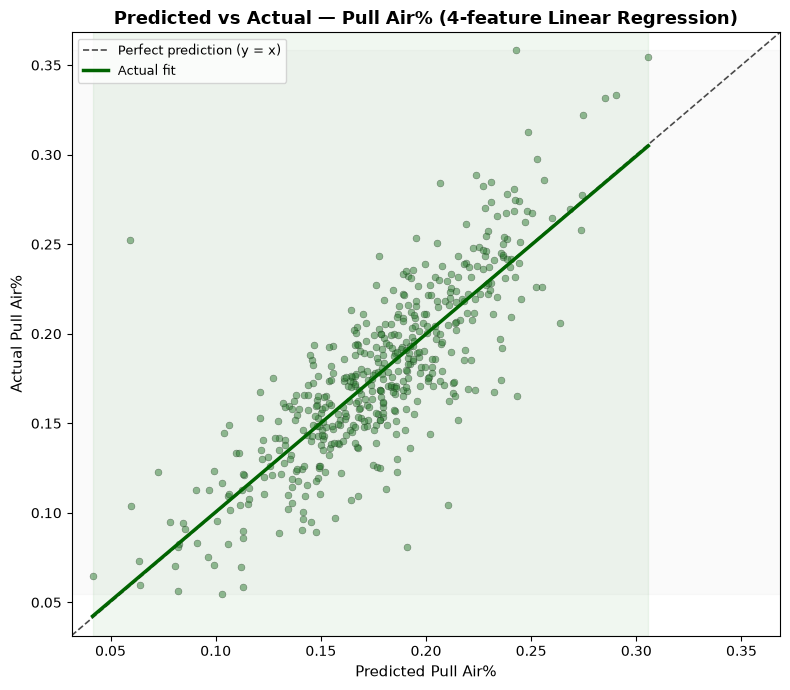

In [155]:
# ── Predicted vs Actual, with compression clearly annotated ────────────────
fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(pred_lr, y, s=25, alpha=0.5, color="#2E7D32", edgecolor="black", linewidth=0.3)

# Perfect-prediction reference (full data range)
full_lim = [min(pred_lr.min(), y.min()) - 0.01, max(pred_lr.max(), y.max()) + 0.01]
ax.plot(full_lim, full_lim, "k--", lw=1.2, alpha=0.7, label="Perfect prediction (y = x)")

# Actual regression fit line, drawn only across the PREDICTED range
# (this is the honest range the model actually outputs)
z = np.polyfit(pred_lr, y, 1)
x_fit = np.linspace(pred_lr.min(), pred_lr.max(), 50)
ax.plot(x_fit, np.polyval(z, x_fit), color="darkgreen", lw=2.5, label="Actual fit")

# Shade the compression: predicted range vs actual range
ax.axvspan(pred_lr.min(), pred_lr.max(), color="green", alpha=0.06)
ax.axhspan(y.min(), y.max(), color="gray", alpha=0.04)

ax.set_xlim(full_lim); ax.set_ylim(full_lim)
ax.set_xlabel("Predicted Pull Air%", fontsize=11)
ax.set_ylabel("Actual Pull Air%", fontsize=11)
ax.set_title(f"Predicted vs Actual — Pull Air% ({len(TRIM_FEATS)}-feature Linear Regression)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="upper left")

# Annotation explaining the compression directly on the plot


plt.tight_layout()
plt.show()

In [156]:
# ── R² alongside Spearman/Pearson ───────────────────────────────────────────
from sklearn.metrics import r2_score

r2 = r2_score(y, pred_lr)
print(f"── Fit statistics ───────────────────────────────────────────────────────")
print(f"  Spearman = {sp:+.4f}")
print(f"  Pearson  = {pr:+.4f}")
print(f"  R²       = {r2:+.4f}")
print(f"  (note: Pearson² = {pr**2:.4f} — should match R² closely for a linear")
print(f"   model with an intercept; small gaps reflect the CV out-of-sample")
print(f"   predictions not being a perfect OLS fit on this exact data)")

── Fit statistics ───────────────────────────────────────────────────────
  Spearman = +0.8140
  Pearson  = +0.8226
  R²       = +0.6767
  (note: Pearson² = 0.6767 — should match R² closely for a linear
   model with an intercept; small gaps reflect the CV out-of-sample
   predictions not being a perfect OLS fit on this exact data)


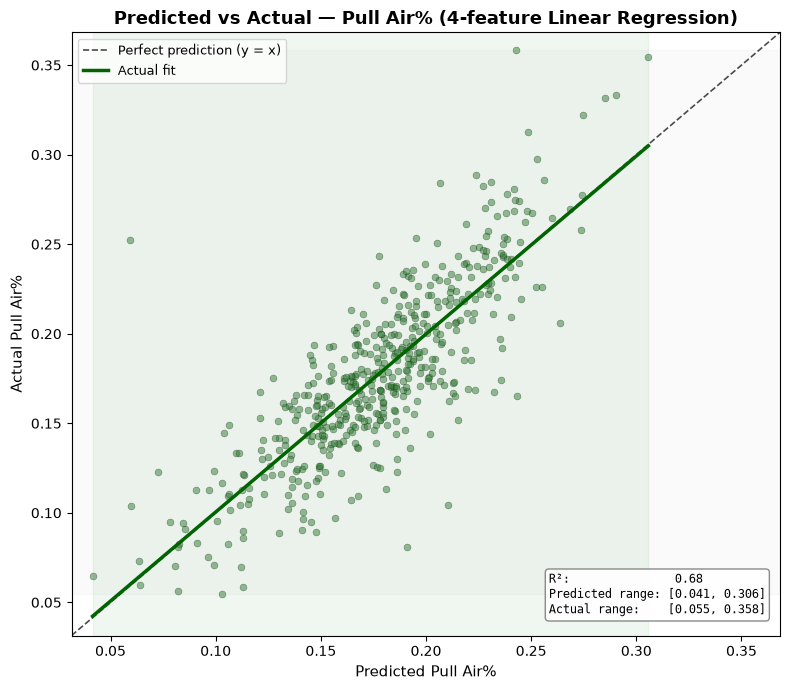

In [157]:
# ── Predicted vs Actual, with R² added to the stat box ─────────────────────
fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(pred_lr, y, s=25, alpha=0.5, color="#2E7D32", edgecolor="black", linewidth=0.3)

full_lim = [min(pred_lr.min(), y.min()) - 0.01, max(pred_lr.max(), y.max()) + 0.01]
ax.plot(full_lim, full_lim, "k--", lw=1.2, alpha=0.7, label="Perfect prediction (y = x)")

z = np.polyfit(pred_lr, y, 1)
x_fit = np.linspace(pred_lr.min(), pred_lr.max(), 50)
ax.plot(x_fit, np.polyval(z, x_fit), color="darkgreen", lw=2.5, label="Actual fit")

ax.axvspan(pred_lr.min(), pred_lr.max(), color="green", alpha=0.06)
ax.axhspan(y.min(), y.max(), color="gray", alpha=0.04)

ax.set_xlim(full_lim); ax.set_ylim(full_lim)
ax.set_xlabel("Predicted Pull Air%", fontsize=11)
ax.set_ylabel("Actual Pull Air%", fontsize=11)
ax.set_title(f"Predicted vs Actual — Pull Air% ({len(TRIM_FEATS)}-feature Linear Regression)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="upper left")

stat_text = (f"R²:               {r2:.2f}         \n"
            f"Predicted range: [{pred_lr.min():.3f}, {pred_lr.max():.3f}]\n"
            f"Actual range:    [{y.min():.3f}, {y.max():.3f}]")
ax.text(0.98, 0.03, stat_text, transform=ax.transAxes, fontsize=8.5,
        va="bottom", ha="right", family="monospace",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.92))

plt.tight_layout()
plt.show()

In [200]:
# ══ Linear Regression — Assumption Checks (raw/unscaled features) ══
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

lr_check_df = plot_df.dropna(subset=TRIM_FEATS + ["pull_air_pct"]).copy()

# Coerce to numeric explicitly — an object-dtype column (from a stale merge or
# a mixed-type NaN) will silently make sm.OLS fail with this exact error.

lr_check_df[TRIM_FEATS + ["pull_air_pct"]] = lr_check_df[TRIM_FEATS + ["pull_air_pct"]].apply(
    pd.to_numeric, errors="coerce")
lr_check_df = lr_check_df.dropna(subset=TRIM_FEATS + ["pull_air_pct"])   # drop any newly-coerced NaN

print(f"Rows after numeric coercion: {len(lr_check_df)}")
print(lr_check_df[TRIM_FEATS + ["pull_air_pct"]].dtypes)

# Cast pandas nullable "Float64" extension dtype back to plain numpy float64.
# pd.to_numeric alone preserves the nullable extension type; statsmodels needs
# real numpy arrays, and silently gets dtype=object when the columns are mixed
# nullable-extension + plain-numpy, which is what triggered the ValueError.
for col in TRIM_FEATS + ["pull_air_pct"]:
    lr_check_df[col] = lr_check_df[col].astype("float64")

print(lr_check_df[TRIM_FEATS + ["pull_air_pct"]].dtypes)   # should now all read float64/int64, lowercase

Xc = sm.add_constant(lr_check_df[TRIM_FEATS])
y_ols = lr_check_df["pull_air_pct"].values

ols_model = sm.OLS(y_ols, Xc).fit()
print(ols_model.summary())

Rows after numeric coercion: 496
mean_tilt       Float64
mean_aa         Float64
mean_dir        Float64
is_L              int64
pull_air_pct    float64
dtype: object
mean_tilt       float64
mean_aa         float64
mean_dir        float64
is_L            float64
pull_air_pct    float64
dtype: object
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.682
Model:                            OLS   Adj. R-squared:                  0.680
Method:                 Least Squares   F-statistic:                     263.4
Date:                Sun, 05 Jul 2026   Prob (F-statistic):          1.06e-120
Time:                        23:22:02   Log-Likelihood:                 1067.8
No. Observations:                 496   AIC:                            -2126.
Df Residuals:                     491   BIC:                            -2105.
Df Model:                           4                              

── Breusch-Pagan test (homoscedasticity) ────────────────────────────────
  p-value = 0.4920
  p < 0.05 ⇒ heteroscedasticity present (residual variance isn't constant)


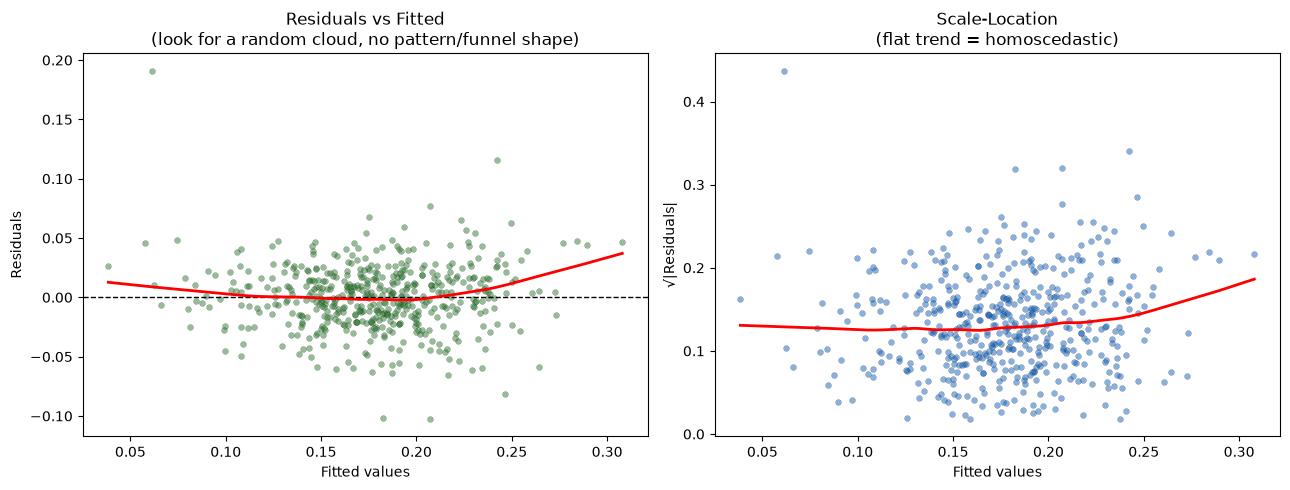

In [201]:
resid  = ols_model.resid
fitted = ols_model.fittedvalues

bp_stat, bp_pval, _, _ = het_breuschpagan(resid, Xc)
print(f"── Breusch-Pagan test (homoscedasticity) ────────────────────────────────")
print(f"  p-value = {bp_pval:.4f}")
print(f"  p < 0.05 ⇒ heteroscedasticity present (residual variance isn't constant)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(fitted, resid, s=18, alpha=0.5, color="#2E7D32", edgecolor="black", linewidth=0.2)
axes[0].axhline(0, color="black", lw=1, ls="--")
axes[0].set_xlabel("Fitted values"); axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted\n(look for a random cloud, no pattern/funnel shape)")

# LOWESS trend line on the residuals — a curved trend flags nonlinearity
from statsmodels.nonparametric.smoothers_lowess import lowess
smoothed = lowess(resid, fitted, frac=0.5)
axes[0].plot(smoothed[:, 0], smoothed[:, 1], color="red", lw=2)

axes[1].scatter(fitted, np.sqrt(np.abs(resid)), s=18, alpha=0.5, color="#1565C0",
                edgecolor="black", linewidth=0.2)
smoothed2 = lowess(np.sqrt(np.abs(resid)), fitted, frac=0.5)
axes[1].plot(smoothed2[:, 0], smoothed2[:, 1], color="red", lw=2)
axes[1].set_xlabel("Fitted values"); axes[1].set_ylabel("√|Residuals|")
axes[1].set_title("Scale-Location\n(flat trend = homoscedastic)")
plt.tight_layout(); plt.show()

── Jarque-Bera test (normality of residuals) ────────────────────────────
  p-value = 0.0000


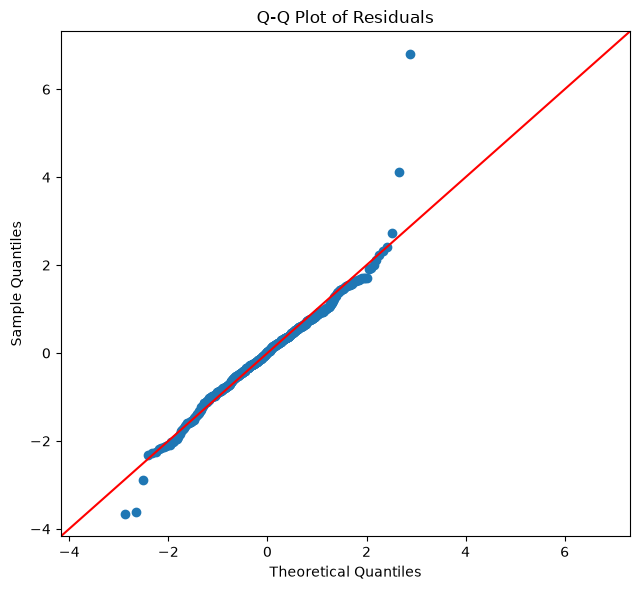

In [203]:
jb_stat, jb_pval = jarque_bera(resid)[:2]
print(f"── Jarque-Bera test (normality of residuals) ────────────────────────────")
print(f"  p-value = {jb_pval:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
sm.qqplot(resid, line="45", fit=True, ax=ax)
ax.set_title("Q-Q Plot of Residuals")
plt.tight_layout(); plt.show()

In [204]:
# VIF needs mean-centered features to avoid the intercept-conflation artifact
# (a raw, uncentered variable's VIF gets inflated purely by its own mean, not
# by real collinearity) — but centering ≠ scaling, so coefficients above stay
# in raw units regardless.
X_centered = lr_check_df[TRIM_FEATS] - lr_check_df[TRIM_FEATS].mean()
vif_df = pd.DataFrame({
    "feature": TRIM_FEATS,
    "VIF": [variance_inflation_factor(X_centered.values, i) for i in range(X_centered.shape[1])]
}).sort_values("VIF", ascending=False)
print("── Variance Inflation Factors (centered only, not scaled) ──────────────")
print(vif_df.round(2).to_string(index=False))

── Variance Inflation Factors (centered only, not scaled) ──────────────
  feature    VIF
mean_tilt 1.1500
  mean_aa 1.0900
 mean_dir 1.0400
     is_L 1.0200


In [205]:
dw = durbin_watson(resid)
print(f"── Durbin-Watson: {dw:.3f}   (≈2.0 = no autocorrelation)")

dup_batters = lr_check_df["batter"].value_counts()
n_repeated = (dup_batters > 1).sum()
print(f"Batters appearing more than once: {n_repeated}")

── Durbin-Watson: 2.006   (≈2.0 = no autocorrelation)
Batters appearing more than once: 0


── Influence diagnostics ─────────────────────────────────────────────────
  Cook's distance threshold (4/n): 0.0081
  Hitters exceeding threshold: 27 of 496


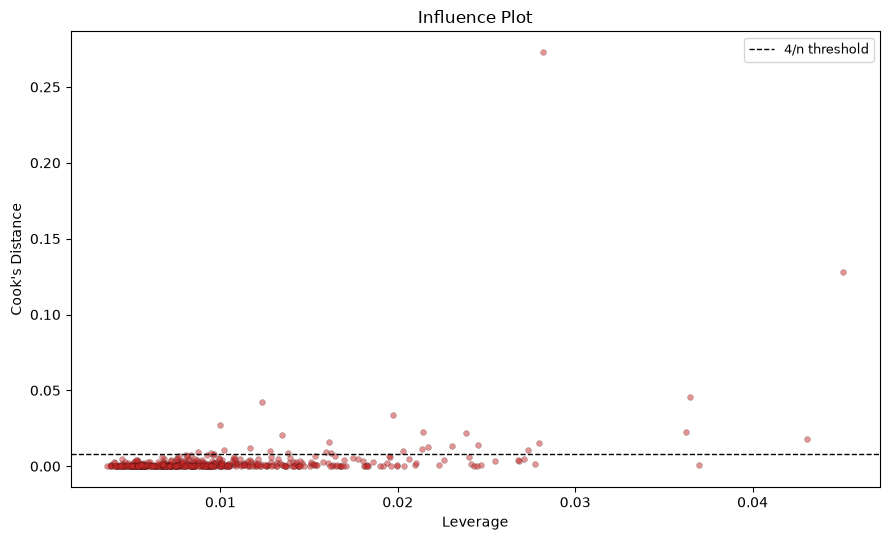


Most influential hitters:


KeyError: '[144] not in index'

In [206]:
influence = OLSInfluence(ols_model)
cooks_d = influence.cooks_distance[0]
leverage = influence.hat_matrix_diag
cooks_threshold = 4 / len(lr_check_df)
n_influential = (cooks_d > cooks_threshold).sum()

print(f"── Influence diagnostics ─────────────────────────────────────────────────")
print(f"  Cook's distance threshold (4/n): {cooks_threshold:.4f}")
print(f"  Hitters exceeding threshold: {n_influential} of {len(lr_check_df)}")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(leverage, cooks_d, s=18, alpha=0.5, color="#C62828", edgecolor="black", linewidth=0.2)
ax.axhline(cooks_threshold, color="black", ls="--", lw=1, label=f"4/n threshold")
ax.set_xlabel("Leverage"); ax.set_ylabel("Cook's Distance")
ax.set_title("Influence Plot")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

if n_influential > 0:
    top_infl_idx = np.argsort(cooks_d)[::-1][:min(10, n_influential)]
    print(f"\nMost influential hitters:")
    print(lr_check_df.iloc[top_infl_idx][["batter"] + TRIM_FEATS + ["pull_air_pct"]]
          .assign(cooks_d=cooks_d[top_infl_idx]).round(3).to_string(index=False))

In [207]:
# Identify the two standout influential points specifically
top2_idx = np.argsort(cooks_d)[::-1][:2]
print("── Two most influential hitters ─────────────────────────────────────────")
print(lr_check_df.iloc[top2_idx][["batter"] + TRIM_FEATS + ["pull_air_pct"]]
      .assign(cooks_d=cooks_d[top2_idx], leverage=leverage[top2_idx]).round(3).to_string(index=False))

# Compare their feature values to the population average — are they extreme
# on X (high leverage / unusual features) or extreme on Y (large residual),
# or both? That distinction matters for what to do about them.
print("\n── Population means, for comparison ─────────────────────────────────────")
print(lr_check_df[TRIM_FEATS + ["pull_air_pct"]].mean().round(3).to_string())

── Two most influential hitters ─────────────────────────────────────────
 batter  mean_tilt  mean_aa  mean_dir   is_L  pull_air_pct  cooks_d  leverage
 596059    32.6910  -1.7410   -4.3610 1.0000        0.2520      NaN    0.0280
 640492    39.7100   0.9480    6.6660 0.0000        0.0810      NaN    0.0450

── Population means, for comparison ─────────────────────────────────────
mean_tilt      32.1060
mean_aa         8.5020
mean_dir       -0.3170
is_L            0.4290
pull_air_pct    0.1780


In [209]:
robust_check = lr_check_df.drop(lr_check_df.index[top2_idx])
Xc_robust = sm.add_constant(robust_check[TRIM_FEATS])
y_robust = robust_check["pull_air_pct"].values
ols_robust = sm.OLS(y_robust, Xc_robust).fit()

comp = pd.DataFrame({"full_data": ols_model.params, "excluding_top2": ols_robust.params})
comp["pct_change"] = (comp["excluding_top2"] - comp["full_data"]) / comp["full_data"].abs() * 100
print(comp.round(4).to_string())
print(f"\nR²: full={ols_model.rsquared:.4f}  excluding_top2={ols_robust.rsquared:.4f}")

           full_data  excluding_top2  pct_change
const         0.1173          0.1122     -4.3382
mean_tilt    -0.0004         -0.0003     31.5674
mean_aa       0.0080          0.0082      2.3914
mean_dir      0.0109          0.0113      3.5602
is_L          0.0185          0.0172     -6.7002

R²: full=0.6821  excluding_top2=0.7176


In [158]:
# Check 1: does plot_df's pull_air_pct match batter_df's, or is there a stale merge?
print(plot_df["pull_air_pct"].describe())
print(batter_df["pull_air_pct"].describe())

# Check 2: is the intercept doing something odd — center X and y and refit manually
print(f"y mean: {y.mean():.3f}   pred_lr mean: {pred_lr.mean():.3f}")
print(f"Difference (should be ~0 for an unbiased CV regression): {(y.mean() - pred_lr.mean()):+.3f}")

count   496.0000
mean      0.1777
std       0.0499
min       0.0549
25%       0.1475
50%       0.1742
75%       0.2079
max       0.3583
Name: pull_air_pct, dtype: float64
count   506.0000
mean      0.1772
std       0.0499
min       0.0549
25%       0.1462
50%       0.1740
75%       0.2075
max       0.3583
Name: pull_air_pct, dtype: float64
y mean: 0.178   pred_lr mean: 0.178
Difference (should be ~0 for an unbiased CV regression): -0.000


In [159]:
plot_df = batter_df.dropna(subset=TRIM_FEATS + ["pull_air_pct", "batter"]).copy()

X = plot_df[TRIM_FEATS].values
y = plot_df["pull_air_pct"].values
groups_reg = plot_df["batter"].values

# Verify BEFORE fitting anything
print(f"y mean: {y.mean():.4f}  (should match plot_df['pull_air_pct'].mean() = "
      f"{plot_df['pull_air_pct'].mean():.4f})")
assert abs(y.mean() - plot_df["pull_air_pct"].mean()) < 1e-6, "y is NOT pull_air_pct — stale variable!"

gkf_reg = GroupKFold(n_splits=min(CV_FOLDS, plot_df["batter"].nunique()))
pipe_lr = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_lr = cross_val_predict(pipe_lr, X, y, cv=gkf_reg, groups=groups_reg)

sp = spearmanr(pred_lr, y).correlation
pr = pearsonr(pred_lr, y)[0]
print(f"Spearman = {sp:+.4f}   Pearson = {pr:+.4f}")

y mean: 0.1777  (should match plot_df['pull_air_pct'].mean() = 0.1777)
Spearman = +0.8140   Pearson = +0.8226


In [160]:
TRIM_FEATS

['mean_aa', 'mean_dir', 'is_L', 'mean_depth']

In [161]:
print(f"Predicted range: [{pred_lr.min():.3f}, {pred_lr.max():.3f}]")
print(f"Actual range:    [{y.min():.3f}, {y.max():.3f}]")
print(f"Predicted mean: {pred_lr.mean():.4f}   Actual mean: {y.mean():.4f}")
print(f"Difference: {(y.mean() - pred_lr.mean()):+.4f}")

Predicted range: [0.041, 0.306]
Actual range:    [0.055, 0.358]
Predicted mean: 0.1777   Actual mean: 0.1777
Difference: -0.0000


In [162]:
# ── wOBA by quadrant ─────────────────────────────────────────────────────────
assert "quadrant" in batter_df.columns, "batter_df needs quadrant assignment."

# Need PA-level outcomes with woba_value/woba_denom — pull from raw_all if not
# already on cp/bbe_full, since wOBA denominators include walks/HBP, not just BBE.
assert "raw_all" in dir(), "Need raw_all (pitch-level data with woba_value/woba_denom)."

woba_source = raw_all[raw_all["woba_denom"].notna() & (raw_all["woba_denom"] > 0)].copy()
woba_agg = (woba_source.groupby("batter")
           .agg(woba_value_sum=("woba_value", "sum"),
                woba_denom_sum=("woba_denom", "sum"))
           .reset_index())
woba_agg["wOBA"] = woba_agg["woba_value_sum"] / woba_agg["woba_denom_sum"]

if "wOBA" in batter_df.columns:
    batter_df = batter_df.drop(columns=["wOBA"])
batter_df = batter_df.merge(woba_agg[["batter", "wOBA"]], on="batter", how="left")

print(f"wOBA matched for {batter_df['wOBA'].notna().sum()} of {len(batter_df)} hitters")

wOBA matched for 506 of 506 hitters


In [163]:
# ── wOBA by quadrant: weighted (correct) and simple mean, side by side ──────
qd = batter_df.dropna(subset=["quadrant", "wOBA"]).copy()

# Weighted wOBA (the statistically correct way — respects each hitter's PA volume)
qd_weighted = (qd.merge(woba_agg[["batter", "woba_value_sum", "woba_denom_sum"]], on="batter")
              .groupby("quadrant")
              .apply(lambda g: g["woba_value_sum"].sum() / g["woba_denom_sum"].sum())
              .reindex(QUAD_ORDER)
              .rename("wOBA_weighted"))

# Simple mean (average of each hitter's own wOBA, unweighted)
qd_simple = qd.groupby("quadrant")["wOBA"].mean().reindex(QUAD_ORDER).rename("wOBA_simple_mean")

n_per_quad = qd.groupby("quadrant").size().reindex(QUAD_ORDER).rename("n")

result = pd.concat([n_per_quad, qd_weighted, qd_simple], axis=1)
print("── wOBA by quadrant ─────────────────────────────────────────────────────")
print(result.round(3).to_string())

── wOBA by quadrant ─────────────────────────────────────────────────────
                     n  wOBA_weighted  wOBA_simple_mean
quadrant                                               
Neither            158         0.3240            0.3160
Pull only           95         0.3210            0.3120
Air only            95         0.3340            0.3240
Both (Pull + Air)  158         0.3280            0.3210


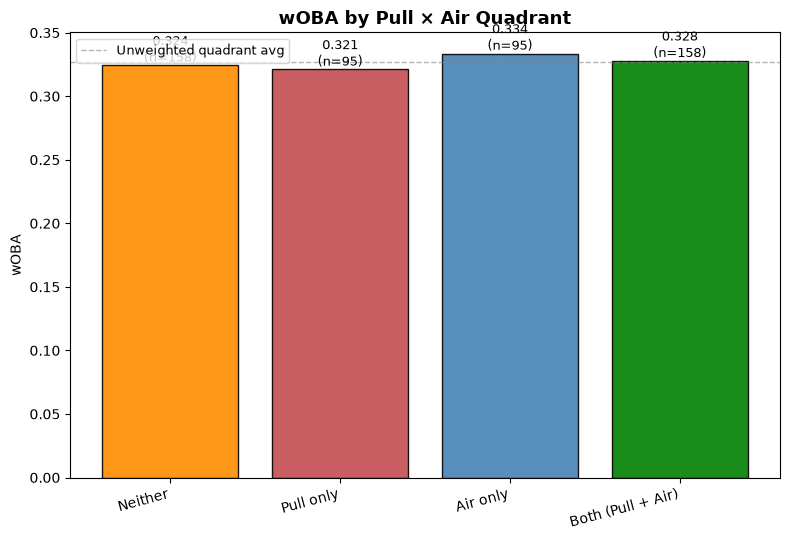

In [164]:
# ── Visual ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [QUAD_COLORS[q] for q in QUAD_ORDER]
bars = ax.bar(QUAD_ORDER, result["wOBA_weighted"], color=colors, alpha=0.9, edgecolor="black")
for b, v, n in zip(bars, result["wOBA_weighted"], result["n"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.003, f"{v:.3f}\n(n={n})",
            ha="center", fontsize=9)
ax.axhline(qd_weighted.mean(), color="gray", ls="--", lw=1, alpha=0.6, label="Unweighted quadrant avg")
ax.set_ylabel("wOBA")
ax.set_title("wOBA by Pull × Air Quadrant", fontsize=13, fontweight="bold")
ax.set_xticklabels(QUAD_ORDER, rotation=15, ha="right")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [165]:
# ── Build/confirm K%, contact rate, and bat speed on batter_df ──────────────
assert "raw_all" in dir(), "Need raw_all for K% and contact rate."

if not {"k_pct", "contact_rate"}.issubset(batter_df.columns):
    SWING_DESCS = {"hit_into_play", "swinging_strike", "foul",
                   "swinging_strike_blocked", "foul_tip"}
    WHIFF_DESCS = {"swinging_strike", "swinging_strike_blocked"}

    pitches = raw_all[raw_all["batter"].notna()].copy()
    pitches["is_swing"] = pitches["description"].isin(SWING_DESCS).astype(int)
    pitches["is_whiff"] = pitches["description"].isin(WHIFF_DESCS).astype(int)

    contact_agg = (pitches[pitches["is_swing"] == 1]
                  .groupby("batter")
                  .agg(swings=("is_swing", "count"), whiffs=("is_whiff", "sum"))
                  .reset_index())
    contact_agg["contact_rate"] = 1 - (contact_agg["whiffs"] / contact_agg["swings"])

    pa_outcomes = raw_all[raw_all["events"].notna()].copy()
    k_agg = (pa_outcomes.groupby("batter")
            .agg(pa=("events", "count"), k=("events", lambda s: (s == "strikeout").sum()))
            .reset_index())
    k_agg["k_pct"] = k_agg["k"] / k_agg["pa"]

    for col in ["contact_rate", "k_pct"]:
        if col in batter_df.columns:
            batter_df = batter_df.drop(columns=[col])
    batter_df = (batter_df.merge(contact_agg[["batter", "contact_rate"]], on="batter", how="left")
                          .merge(k_agg[["batter", "k_pct"]], on="batter", how="left"))

if "mean_bs" not in batter_df.columns and "bat_speed" in cp.columns:
    bs_agg = cp.groupby("batter")["bat_speed"].mean().rename("mean_bs").reset_index()
    batter_df = batter_df.merge(bs_agg, on="batter", how="left")

print(f"k_pct, contact_rate, mean_bs present: "
      f"{{'k_pct', 'contact_rate', 'mean_bs'}}.issubset(batter_df.columns) = "
      f"{{'k_pct', 'contact_rate', 'mean_bs'}}.issubset(batter_df.columns)")

k_pct, contact_rate, mean_bs present: {'k_pct', 'contact_rate', 'mean_bs'}.issubset(batter_df.columns) = {'k_pct', 'contact_rate', 'mean_bs'}.issubset(batter_df.columns)


In [166]:
# ── Fit expected wOBA from physical tools + approach (bat speed, K%, contact rate)
CONTROL_FEATS = [c for c in ["mean_bs", "k_pct"] if c in batter_df.columns]
print(f"Controls used: {CONTROL_FEATS}")

woba_ctrl_df = batter_df.dropna(subset=CONTROL_FEATS + ["wOBA", "quadrant"]).copy()
X = woba_ctrl_df[CONTROL_FEATS].values
y = woba_ctrl_df["wOBA"].values
groups_w = woba_ctrl_df["batter"].values
gkf_w = GroupKFold(n_splits=min(CV_FOLDS, woba_ctrl_df["batter"].nunique()))

pipe_woba = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_woba = cross_val_predict(pipe_woba, X, y, cv=gkf_w, groups=groups_w)

woba_ctrl_df["expected_wOBA"] = pred_woba
woba_ctrl_df["wOBA_residual"] = woba_ctrl_df["wOBA"] - woba_ctrl_df["expected_wOBA"]

print(f"Spearman(expected wOBA, actual wOBA) = {spearmanr(pred_woba, y).correlation:+.3f}")

pipe_woba.fit(X, y)
print("\nStandardized coefficients:")
print(pd.Series(pipe_woba.named_steps["m"].coef_, index=CONTROL_FEATS).round(4).to_string())

Controls used: ['mean_bs', 'k_pct']
Spearman(expected wOBA, actual wOBA) = +0.504

Standardized coefficients:
mean_bs    0.0171
k_pct     -0.0117


── wOBA residual by quadrant (after controlling for bat speed, K%, contact rate) ──
                     mean    std  count    sem   ci95
quadrant                                             
Neither           -0.0045 0.0203    153 0.0016 0.0032
Pull only         -0.0077 0.0231     92 0.0024 0.0047
Air only           0.0067 0.0266     94 0.0027 0.0054
Both (Pull + Air)  0.0050 0.0218    155 0.0018 0.0034


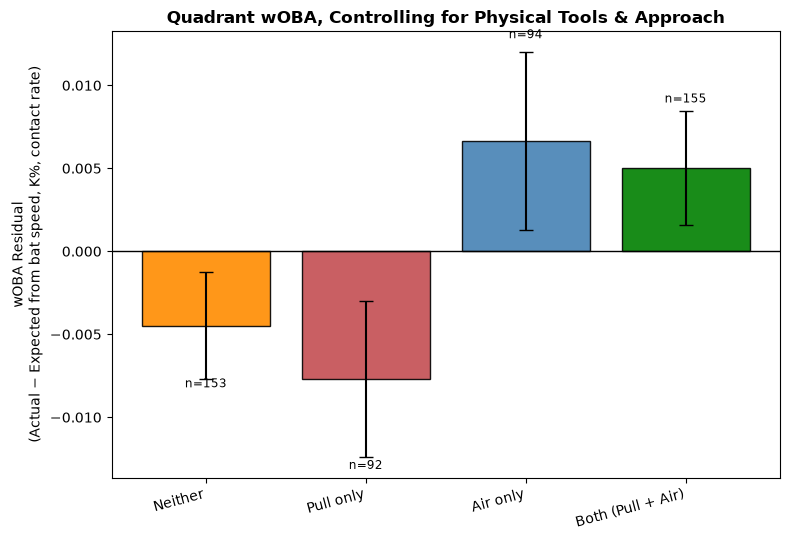

In [167]:
# ── wOBA residual by quadrant — with error bars, since per-quadrant n is small
qd_stats = (woba_ctrl_df.groupby("quadrant")["wOBA_residual"]
           .agg(["mean", "std", "count"]).reindex(QUAD_ORDER))
qd_stats["sem"] = qd_stats["std"] / np.sqrt(qd_stats["count"])
qd_stats["ci95"] = 1.96 * qd_stats["sem"]

print("── wOBA residual by quadrant (after controlling for bat speed, K%, contact rate) ──")
print(qd_stats.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [QUAD_COLORS[q] for q in QUAD_ORDER]
ax.bar(QUAD_ORDER, qd_stats["mean"], yerr=qd_stats["ci95"], color=colors,
      alpha=0.9, edgecolor="black", capsize=5)
ax.axhline(0, color="black", lw=1)
for i, q in enumerate(QUAD_ORDER):
    ax.text(i, qd_stats.loc[q, "mean"] + np.sign(qd_stats.loc[q, "mean"])*qd_stats.loc[q, "ci95"]*1.15,
            f"n={int(qd_stats.loc[q, 'count'])}", ha="center", fontsize=8.5)
ax.set_ylabel("wOBA Residual\n(Actual − Expected from bat speed, K%, contact rate)")
ax.set_title("Quadrant wOBA, Controlling for Physical Tools & Approach",
             fontsize=12, fontweight="bold")
ax.set_xticklabels(QUAD_ORDER, rotation=15, ha="right")
plt.tight_layout()
plt.show()

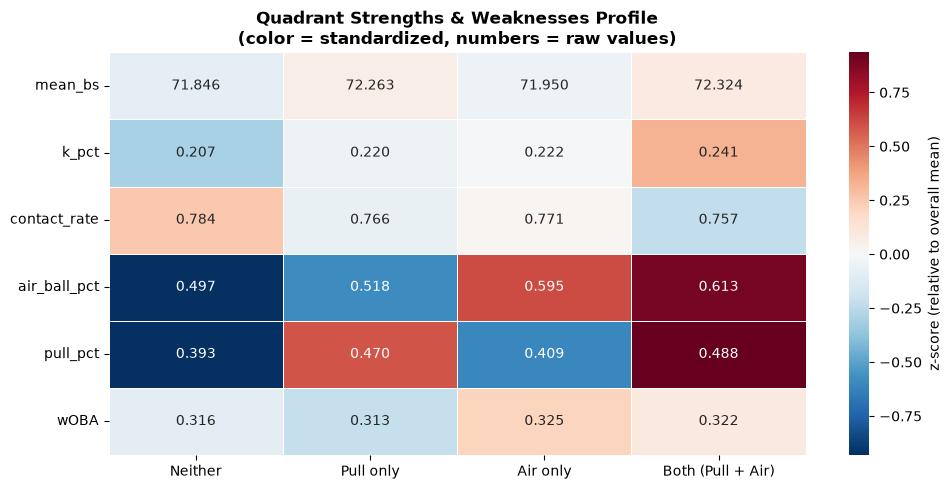

In [168]:
# ── Full strengths/weaknesses profile: standardized z-scores by quadrant ───
PROFILE_FEATS = [c for c in ["mean_bs", "k_pct", "contact_rate", "barrel_rate",
                             "mean_ev", "air_ball_pct", "pull_pct", "wOBA"]
                 if c in batter_df.columns]

prof = batter_df.dropna(subset=PROFILE_FEATS + ["quadrant"]).copy()
prof[PROFILE_FEATS] = prof[PROFILE_FEATS].apply(pd.to_numeric, errors="coerce")

prof_z = (prof[PROFILE_FEATS] - prof[PROFILE_FEATS].mean()) / prof[PROFILE_FEATS].std()
prof_means_z = prof_z.groupby(prof["quadrant"]).mean().reindex(QUAD_ORDER)
prof_means_raw = prof.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(prof_means_z.T.values.astype(float),
            annot=prof_means_raw.T.values.astype(float), fmt=".3f",
            cmap="RdBu_r", center=0, linewidths=0.5, linecolor="white", ax=ax,
            xticklabels=QUAD_ORDER, yticklabels=PROFILE_FEATS,
            cbar_kws={"label": "z-score (relative to overall mean)"})
ax.set_title("Quadrant Strengths & Weaknesses Profile\n(color = standardized, numbers = raw values)",
             fontsize=12, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [109]:
# ── Build walk rate (BB%) and merge onto batter_df ──────────────────────────
assert "raw_all" in dir(), "Need raw_all for walk rate."

if "bb_pct" not in batter_df.columns:
    pa_outcomes = raw_all[raw_all["events"].notna()].copy()
    bb_agg = (pa_outcomes.groupby("batter")
             .agg(pa=("events", "count"),
                  bb=("events", lambda s: (s == "walk").sum()))
             .reset_index())
    bb_agg["bb_pct"] = bb_agg["bb"] / bb_agg["pa"]

    batter_df = batter_df.merge(bb_agg[["batter", "bb_pct"]], on="batter", how="left")

print(f"bb_pct matched for {batter_df['bb_pct'].notna().sum()} of {len(batter_df)} hitters")
print(batter_df["bb_pct"].describe().round(3).to_string())

bb_pct matched for 506 of 506 hitters
count   506.0000
mean      0.0790
std       0.0240
min       0.0280
25%       0.0600
50%       0.0770
75%       0.0950
max       0.1750


In [110]:
# ── Add bb_pct to the wOBA control model ────────────────────────────────────
CONTROL_FEATS = [c for c in ["mean_bs", "k_pct", "contact_rate", "bb_pct"]
                 if c in batter_df.columns]
print(f"Controls used: {CONTROL_FEATS}")

woba_ctrl_df = batter_df.dropna(subset=CONTROL_FEATS + ["wOBA", "quadrant"]).copy()
X = woba_ctrl_df[CONTROL_FEATS].values
y = woba_ctrl_df["wOBA"].values
groups_w = woba_ctrl_df["batter"].values
gkf_w = GroupKFold(n_splits=min(CV_FOLDS, woba_ctrl_df["batter"].nunique()))

pipe_woba = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_woba = cross_val_predict(pipe_woba, X, y, cv=gkf_w, groups=groups_w)

woba_ctrl_df["expected_wOBA"] = pred_woba
woba_ctrl_df["wOBA_residual"] = woba_ctrl_df["wOBA"] - woba_ctrl_df["expected_wOBA"]

print(f"Spearman(expected wOBA, actual wOBA) = {spearmanr(pred_woba, y).correlation:+.3f}")
pipe_woba.fit(X, y)
print("\nStandardized coefficients:")
print(pd.Series(pipe_woba.named_steps["m"].coef_, index=CONTROL_FEATS).round(4).to_string())

Controls used: ['mean_bs', 'k_pct', 'contact_rate', 'bb_pct']
Spearman(expected wOBA, actual wOBA) = +0.634

Standardized coefficients:
mean_bs         0.0155
k_pct          -0.0196
contact_rate   -0.0077
bb_pct          0.0120


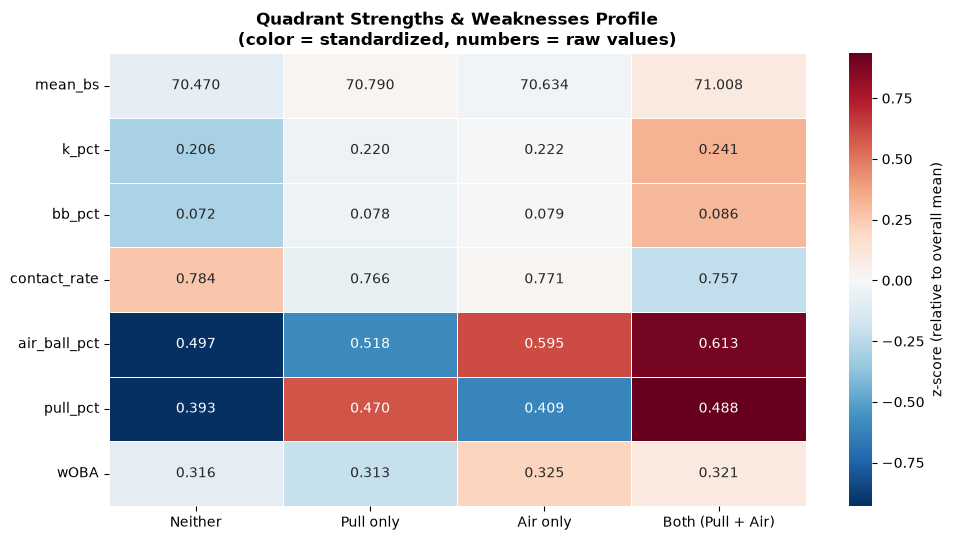

In [111]:
# ── Add bb_pct to the profile heatmap ───────────────────────────────────────
PROFILE_FEATS = [c for c in ["mean_bs", "k_pct", "bb_pct", "contact_rate", "barrel_rate",
                             "mean_ev", "air_ball_pct", "pull_pct", "wOBA"]
                 if c in batter_df.columns]

prof = batter_df.dropna(subset=PROFILE_FEATS + ["quadrant"]).copy()
prof[PROFILE_FEATS] = prof[PROFILE_FEATS].apply(pd.to_numeric, errors="coerce")

prof_z = (prof[PROFILE_FEATS] - prof[PROFILE_FEATS].mean()) / prof[PROFILE_FEATS].std()
prof_means_z = prof_z.groupby(prof["quadrant"]).mean().reindex(QUAD_ORDER)
prof_means_raw = prof.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(prof_means_z.T.values.astype(float),
            annot=prof_means_raw.T.values.astype(float), fmt=".3f",
            cmap="RdBu_r", center=0, linewidths=0.5, linecolor="white", ax=ax,
            xticklabels=QUAD_ORDER, yticklabels=PROFILE_FEATS,
            cbar_kws={"label": "z-score (relative to overall mean)"})
ax.set_title("Quadrant Strengths & Weaknesses Profile\n(color = standardized, numbers = raw values)",
             fontsize=12, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [112]:
# ── wOBAcon: wOBA on CONTACT only (batted balls, excludes BB/HBP/K) ─────────
assert "raw_all" in dir(), "Need raw_all with woba_value/woba_denom and type/description."

# Contact = a batted ball event, i.e. description == "hit_into_play"
# (walks, HBP, and strikeouts never reach this description value)
wobacon_source = raw_all[
    (raw_all["description"] == "hit_into_play") &
    raw_all["woba_denom"].notna() & (raw_all["woba_denom"] > 0)
].copy()

wobacon_agg = (wobacon_source.groupby("batter")
              .agg(wobacon_value_sum=("woba_value", "sum"),
                   wobacon_denom_sum=("woba_denom", "sum"))
              .reset_index())
wobacon_agg["wOBAcon"] = wobacon_agg["wobacon_value_sum"] / wobacon_agg["wobacon_denom_sum"]

if "wOBAcon" in batter_df.columns:
    batter_df = batter_df.drop(columns=["wOBAcon"])
batter_df = batter_df.merge(wobacon_agg[["batter", "wOBAcon"]], on="batter", how="left")

print(f"wOBAcon matched for {batter_df['wOBAcon'].notna().sum()} of {len(batter_df)} hitters")
print(batter_df["wOBAcon"].describe().round(3).to_string())

wOBAcon matched for 506 of 506 hitters
count   506.0000
mean      0.3750
std       0.0440
min       0.2530
25%       0.3450
50%       0.3710
75%       0.4050
max       0.6040


In [113]:
# ── wOBAcon by quadrant (weighted + simple mean) ────────────────────────────
qd_con = batter_df.dropna(subset=["quadrant", "wOBAcon"]).copy()

qd_con_weighted = (qd_con.merge(wobacon_agg[["batter", "wobacon_value_sum", "wobacon_denom_sum"]],
                                on="batter")
                  .groupby("quadrant")
                  .apply(lambda g: g["wobacon_value_sum"].sum() / g["wobacon_denom_sum"].sum())
                  .reindex(QUAD_ORDER)
                  .rename("wOBAcon_weighted"))
qd_con_simple = qd_con.groupby("quadrant")["wOBAcon"].mean().reindex(QUAD_ORDER).rename("wOBAcon_simple_mean")
n_per_quad = qd_con.groupby("quadrant").size().reindex(QUAD_ORDER).rename("n")

result_con = pd.concat([n_per_quad, qd_con_weighted, qd_con_simple], axis=1)
print("── wOBAcon by quadrant ──────────────────────────────────────────────────")
print(result_con.round(3).to_string())

── wOBAcon by quadrant ──────────────────────────────────────────────────
                     n  wOBAcon_weighted  wOBAcon_simple_mean
quadrant                                                     
Neither            158            0.3730               0.3650
Pull only           95            0.3730               0.3640
Air only            95            0.3900               0.3830
Both (Pull + Air)  158            0.3860               0.3850


In [114]:
# ── mean_bs: top-90% trimmed average (drop bottom 10% of each hitter's swings)
assert "bat_speed" in cp.columns, "cp needs bat_speed."

def _top90_mean(s):
    s = s.dropna()
    if len(s) < 10:
        return np.nan
    cutoff = s.quantile(0.10)   # bottom 10% threshold
    return s[s >= cutoff].mean()

mean_bs_trimmed = (cp.groupby("batter")["bat_speed"]
                   .apply(_top90_mean)
                   .rename("mean_bs")
                   .reset_index())

if "mean_bs" in batter_df.columns:
    batter_df = batter_df.drop(columns=["mean_bs"])
batter_df = batter_df.merge(mean_bs_trimmed, on="batter", how="left")

print(f"mean_bs (top-90% trimmed) matched for {batter_df['mean_bs'].notna().sum()} of {len(batter_df)}")
print(batter_df["mean_bs"].describe().round(3).to_string())

# Compare against the untrimmed flat mean, to see how much it moves
flat_mean_bs = cp.groupby("batter")["bat_speed"].mean().rename("mean_bs_flat")
compare = batter_df[["batter", "mean_bs"]].merge(flat_mean_bs, on="batter")
print(f"\nMean shift from trimming: {(compare['mean_bs'] - compare['mean_bs_flat']).mean():+.3f} mph")
print(f"Correlation (trimmed vs flat): {compare[['mean_bs','mean_bs_flat']].corr().iloc[0,1]:.3f}")

mean_bs (top-90% trimmed) matched for 494 of 506
count   494.0000
mean     72.0930
std       2.7310
min      63.8410
25%      70.2880
50%      72.1900
75%      73.9390
max      81.9040

Mean shift from trimming: +1.363 mph
Correlation (trimmed vs flat): 0.987


In [115]:
if batter_df.columns.duplicated().any():
    dupe_names = batter_df.columns[batter_df.columns.duplicated()].tolist()
    print(f"Removing duplicate columns: {dupe_names}")
    batter_df = batter_df.loc[:, ~batter_df.columns.duplicated(keep="last")]
    print(f"batter_df shape after dedup: {batter_df.shape}")

# Confirm it's gone
print("bat_speed" in batter_df.columns, "— duplicated:",
      batter_df.columns.duplicated().any())

False — duplicated: False


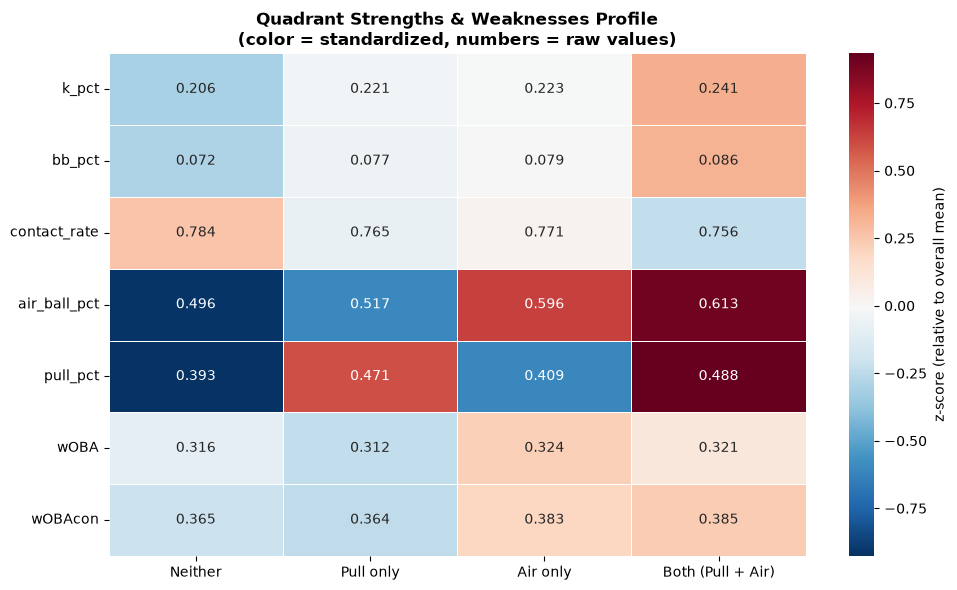

In [116]:
# ── Add wOBAcon to the profile heatmap ──────────────────────────────────────
PROFILE_FEATS = [c for c in ["bat_speed", "k_pct", "bb_pct", "contact_rate", "barrel_rate",
                             "mean_ev", "air_ball_pct", "pull_pct", "wOBA", "wOBAcon"]
                 if c in batter_df.columns]

prof = batter_df.dropna(subset=PROFILE_FEATS + ["quadrant"]).copy()
prof[PROFILE_FEATS] = prof[PROFILE_FEATS].apply(pd.to_numeric, errors="coerce")

prof_z = (prof[PROFILE_FEATS] - prof[PROFILE_FEATS].mean()) / prof[PROFILE_FEATS].std()
prof_means_z = prof_z.groupby(prof["quadrant"]).mean().reindex(QUAD_ORDER)
prof_means_raw = prof.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(prof_means_z.T.values.astype(float),
            annot=prof_means_raw.T.values.astype(float), fmt=".3f",
            cmap="RdBu_r", center=0, linewidths=0.5, linecolor="white", ax=ax,
            xticklabels=QUAD_ORDER, yticklabels=PROFILE_FEATS,
            cbar_kws={"label": "z-score (relative to overall mean)"})
ax.set_title("Quadrant Strengths & Weaknesses Profile\n(color = standardized, numbers = raw values)",
             fontsize=12, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [117]:
# ── Bat speed -> wOBAcon, conditional on being an "air" hitter ─────────────
assert {"mean_bs", "wOBAcon", "is_air", "quadrant"}.issubset(batter_df.columns)

bs_woba_df = batter_df.dropna(subset=["mean_bs", "wOBAcon", "quadrant"]).copy()

# ── Group 1: broad "air hitters" = is_air == 1 (Air only + Both) ───────────
air_group = bs_woba_df[bs_woba_df["is_air"] == 1]
non_air_group = bs_woba_df[bs_woba_df["is_air"] == 0]

r_air = spearmanr(air_group["mean_bs"], air_group["wOBAcon"]).correlation
r_non_air = spearmanr(non_air_group["mean_bs"], non_air_group["wOBAcon"]).correlation
r_all = spearmanr(bs_woba_df["mean_bs"], bs_woba_df["wOBAcon"]).correlation

print(f"── Bat speed vs wOBAcon ─────────────────────────────────────────────────")
print(f"  All hitters:              r = {r_all:+.3f}  (n={len(bs_woba_df)})")
print(f"  Air hitters (is_air=1):   r = {r_air:+.3f}  (n={len(air_group)})")
print(f"  Non-air hitters:          r = {r_non_air:+.3f}  (n={len(non_air_group)})")

── Bat speed vs wOBAcon ─────────────────────────────────────────────────
  All hitters:              r = +0.686  (n=494)
  Air hitters (is_air=1):   r = +0.660  (n=249)
  Non-air hitters:          r = +0.729  (n=245)


In [118]:
!pip install xgboost


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [119]:
# ══ Multinomial XGBoost quadrant classifier + SHAP ══
import xgboost as xgb
import shap
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, cohen_kappa_score, roc_auc_score, classification_report
from sklearn.preprocessing import LabelEncoder

XGB_FEATS = ["mean_aa", "mean_tilt", "mean_dir",
             "is_L"]

xgb_df = batter_df.dropna(subset=XGB_FEATS + ["quadrant", "batter"]).copy()
print(f"Model dataset: n = {len(xgb_df)}")
print(f"Features: {XGB_FEATS}")

le = LabelEncoder()
le.fit(QUAD_ORDER)
y_enc = le.transform(xgb_df["quadrant"])
groups_xgb = xgb_df["batter"].values
gkf_xgb = GroupKFold(n_splits=min(CV_FOLDS, xgb_df["batter"].nunique()))

xgb_model = xgb.XGBClassifier(
    objective="multi:softprob", num_class=4,
    n_estimators=300, max_depth=4, learning_rate=0.08,
    subsample=0.8, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=SEED, eval_metric="mlogloss"
)

proba_xgb = cross_val_predict(xgb_model, xgb_df[XGB_FEATS].values, y_enc,
                              cv=gkf_xgb, groups=groups_xgb, method="predict_proba")
pred_xgb = le.inverse_transform(proba_xgb.argmax(axis=1))
actual_xgb = xgb_df["quadrant"].values

acc_xgb = accuracy_score(actual_xgb, pred_xgb)
kap_xgb = cohen_kappa_score(actual_xgb, pred_xgb)

print(f"\n── XGBoost Multinomial Classifier ──────────────────────────────────────")
print(f"  Accuracy = {acc_xgb:.4f}")
print(f"  Cohen κ  = {kap_xgb:.4f}")
print(f"\n  Per-class one-vs-rest AUC:")
for i, q in enumerate(le.classes_):
    y_oc = (actual_xgb == q).astype(int)
    print(f"    {q:<22} AUC = {roc_auc_score(y_oc, proba_xgb[:, i]):.4f}")

Model dataset: n = 496
Features: ['mean_aa', 'mean_tilt', 'mean_dir', 'is_L']

── XGBoost Multinomial Classifier ──────────────────────────────────────
  Accuracy = 0.5484
  Cohen κ  = 0.3804

  Per-class one-vs-rest AUC:
    Air only               AUC = 0.7538
    Both (Pull + Air)      AUC = 0.8649
    Neither                AUC = 0.8474
    Pull only              AUC = 0.6974


── Per-quadrant metrics ───────────────────────────────────────────────
                   precision  recall  f1-score  support
Neither               0.6260  0.6300    0.6280 154.0000
Pull only             0.3700  0.2930    0.3270  92.0000
Air only              0.3370  0.3300    0.3330  94.0000
Both (Pull + Air)     0.6650  0.7500    0.7050 156.0000


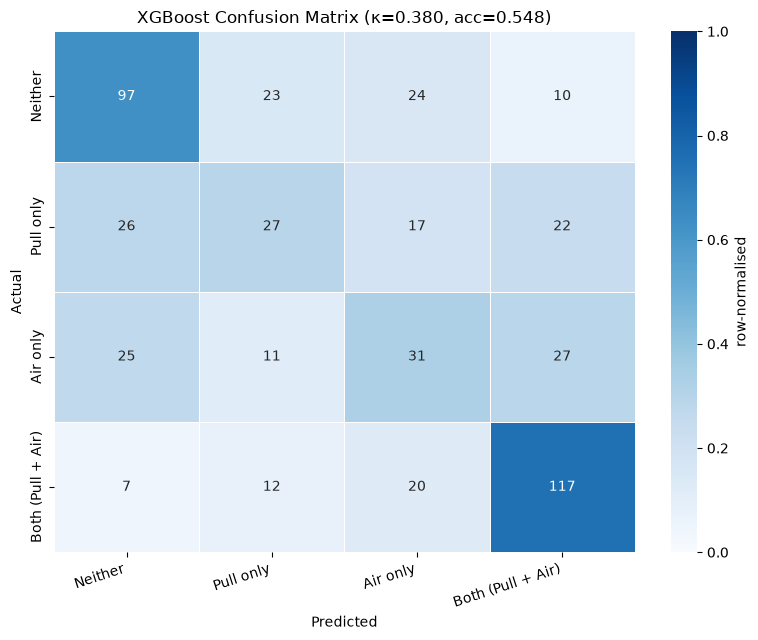

In [120]:
# ── Per-quadrant metrics + confusion matrix ─────────────────────────────────
print("── Per-quadrant metrics ───────────────────────────────────────────────")
print(pd.DataFrame(classification_report(actual_xgb, pred_xgb, labels=QUAD_ORDER,
      output_dict=True, zero_division=0)).T.loc[
      QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6.5))
cm  = confusion_matrix(actual_xgb, pred_xgb, labels=QUAD_ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
            xticklabels=QUAD_ORDER, yticklabels=QUAD_ORDER,
            linewidths=0.5, linecolor="white", ax=ax, cbar_kws={"label": "row-normalised"})
ax.set_title(f"XGBoost Confusion Matrix (κ={kap_xgb:.3f}, acc={acc_xgb:.3f})")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_xticklabels(QUAD_ORDER, rotation=18, ha="right")
plt.tight_layout(); plt.show()

In [121]:
# ── Fit on full data for SHAP (SHAP needs one trained model, not CV folds) ──
xgb_model.fit(xgb_df[XGB_FEATS].values, y_enc)

explainer = shap.TreeExplainer(xgb_model)
shap_exp = explainer(xgb_df[XGB_FEATS])
# shap_exp.values shape: (n_samples, n_features, n_classes)
print(f"SHAP values shape: {shap_exp.values.shape}")

SHAP values shape: (496, 4, 4)


In [122]:
# ── Map QUAD_ORDER to the correct index in le.classes_ ─────────────────────
class_to_idx = {c: i for i, c in enumerate(le.classes_)}
QUAD_IDX_ORDER = [class_to_idx[q] for q in QUAD_ORDER]
print(f"le.classes_ (alphabetical): {list(le.classes_)}")
print(f"QUAD_ORDER: {QUAD_ORDER}")
print(f"Index mapping: {QUAD_IDX_ORDER}")

le.classes_ (alphabetical): [np.str_('Air only'), np.str_('Both (Pull + Air)'), np.str_('Neither'), np.str_('Pull only')]
QUAD_ORDER: ['Neither', 'Pull only', 'Air only', 'Both (Pull + Air)']
Index mapping: [2, 3, 0, 1]


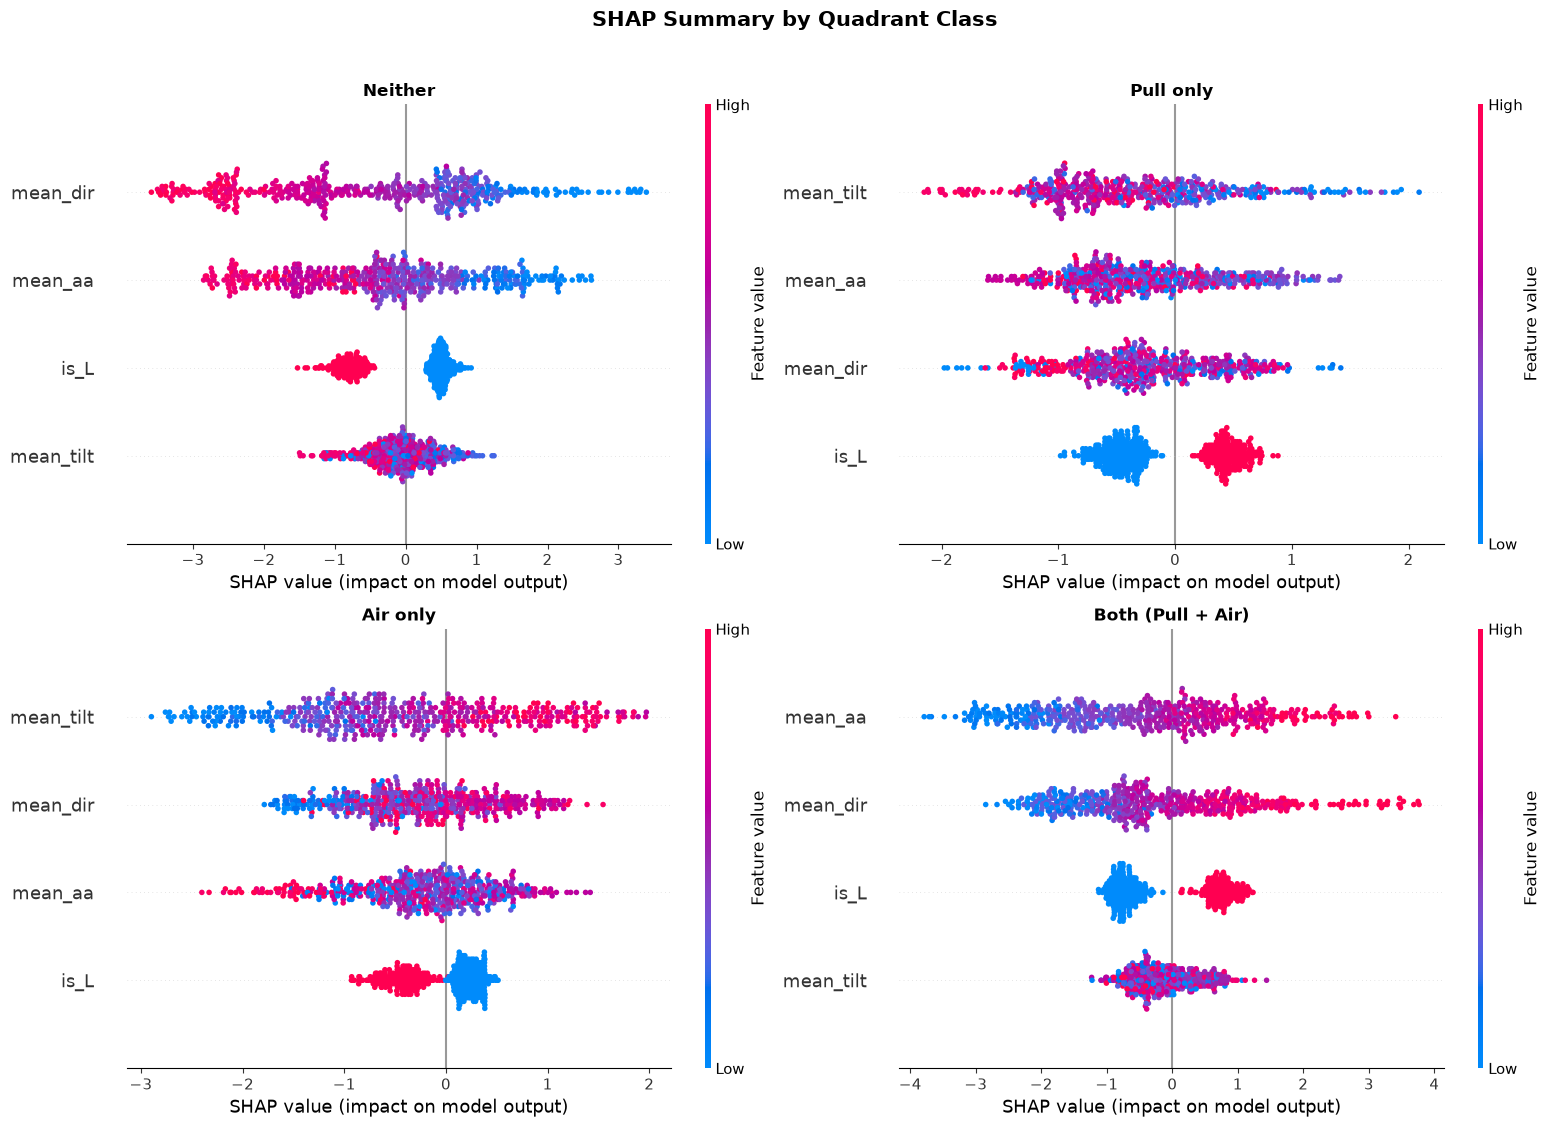

In [123]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, q in zip(axes.flat, QUAD_ORDER):
    i = class_to_idx[q]
    plt.sca(ax)
    shap.summary_plot(shap_exp.values[:, :, i], xgb_df[XGB_FEATS], show=False, plot_size=None)
    ax.set_title(q, fontsize=12, fontweight="bold")
plt.suptitle("SHAP Summary by Quadrant Class", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

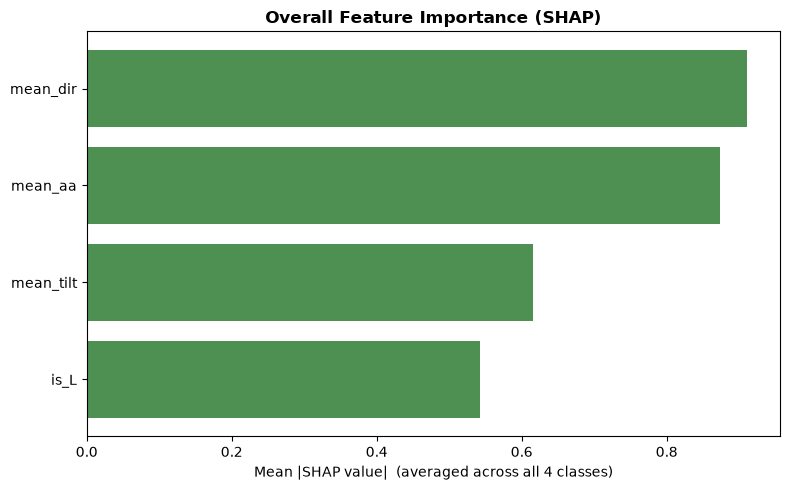

── Mean |SHAP| by feature (overall) ────────────────────────────────────
mean_dir    0.9108
mean_aa     0.8733
mean_tilt   0.6160
is_L        0.5429
── Mean |SHAP| by feature, per class ────────────────────────────────────
           Neither  Pull only  Air only  Both (Pull + Air)
mean_aa     1.0796     0.5822    0.5613             1.2702
mean_tilt   0.3636     0.6942    0.9922             0.4140
mean_dir    1.3671     0.5540    0.6027             1.1193
is_L        0.6344     0.4682    0.3287             0.7404


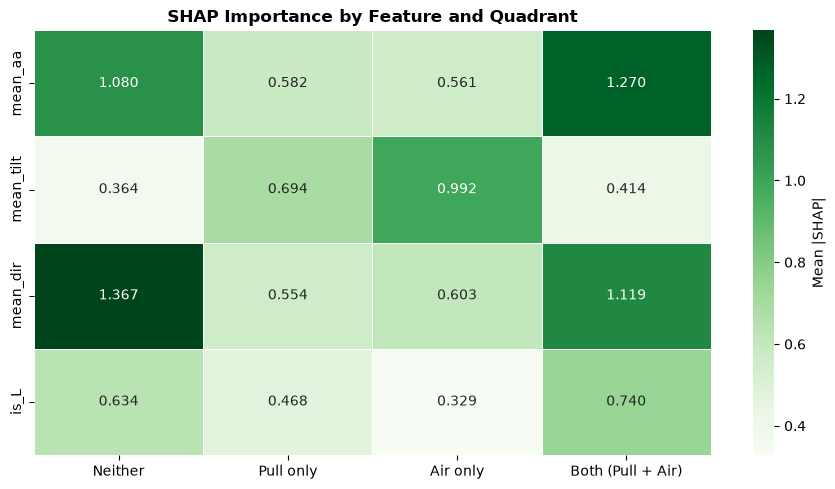

In [124]:
# ── Combined: mean |SHAP| across all classes, one bar chart ────────────────
mean_abs_shap = np.abs(shap_exp.values).mean(axis=(0, 2))   # avg over samples AND classes
shap_importance = pd.Series(mean_abs_shap, index=XGB_FEATS).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(shap_importance.index, shap_importance.values, color="#2E7D32", alpha=0.85)
ax.set_xlabel("Mean |SHAP value|  (averaged across all 4 classes)")
ax.set_title("Overall Feature Importance (SHAP)", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

print("── Mean |SHAP| by feature (overall) ────────────────────────────────────")
print(shap_importance.sort_values(ascending=False).round(4).to_string())

# ── Per-class breakdown of mean |SHAP| ──────────────────────────────────────
per_class_shap = pd.DataFrame(
    np.abs(shap_exp.values).mean(axis=0),
    index=XGB_FEATS, columns=le.classes_
)[QUAD_ORDER]   # reorder columns to Neither, Pull only, Air only, Both

print("── Mean |SHAP| by feature, per class ────────────────────────────────────")
print(per_class_shap.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(per_class_shap, annot=True, fmt=".3f", cmap="Greens",
            linewidths=0.5, linecolor="white", ax=ax, cbar_kws={"label": "Mean |SHAP|"})
ax.set_title("SHAP Importance by Feature and Quadrant", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

In [125]:
# ── Baseline: Multinomial Logistic Regression, same features/CV as XGBoost ──
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe_lr_baseline = Pipeline([("s", StandardScaler()),
                             ("m", LogisticRegression(
                                 multi_class="multinomial", solver="lbfgs",
                                 max_iter=2000, C=0.5, class_weight="balanced",
                                 random_state=SEED))])

proba_lr_baseline = cross_val_predict(pipe_lr_baseline, xgb_df[XGB_FEATS].values, y_enc,
                                      cv=gkf_xgb, groups=groups_xgb, method="predict_proba")
pred_lr_baseline = le.inverse_transform(proba_lr_baseline.argmax(axis=1))

acc_lr = accuracy_score(actual_xgb, pred_lr_baseline)
kap_lr = cohen_kappa_score(actual_xgb, pred_lr_baseline)

print(f"── Multinomial Logistic Regression (baseline) ──────────────────────────")
print(f"  Accuracy = {acc_lr:.4f}")
print(f"  Cohen κ  = {kap_lr:.4f}")
print(f"\n  Per-class one-vs-rest AUC:")
for q in QUAD_ORDER:
    i = class_to_idx[q]
    y_oc = (actual_xgb == q).astype(int)
    print(f"    {q:<22} AUC = {roc_auc_score(y_oc, proba_lr_baseline[:, i]):.4f}")

── Multinomial Logistic Regression (baseline) ──────────────────────────
  Accuracy = 0.6048
  Cohen κ  = 0.4711

  Per-class one-vs-rest AUC:
    Neither                AUC = 0.8911
    Pull only              AUC = 0.7304
    Air only               AUC = 0.7982
    Both (Pull + Air)      AUC = 0.9023


In [186]:
# ══ Multinomial Logistic Regression — Assumption Checks ══
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

check_df = xgb_df.dropna(subset=XGB_FEATS_INTER + ["quadrant", "batter"]).copy()
X_check = check_df[XGB_FEATS_INTER]

In [187]:
# VIF MUST be computed on standardized/centered features — on raw features,
# any variable with a nonzero mean gets its VIF inflated by conflation with
# the intercept, producing meaningless (often huge) values.
Xs = pd.DataFrame(StandardScaler().fit_transform(X_check), columns=X_check.columns)

vif_df = pd.DataFrame({
    "feature": Xs.columns,
    "VIF": [variance_inflation_factor(Xs.values, i) for i in range(Xs.shape[1])]
}).sort_values("VIF", ascending=False)

print("── Variance Inflation Factors ───────────────────────────────────────────")
print(vif_df.round(2).to_string(index=False))
print("\nRule of thumb: VIF > 5 = moderate concern, VIF > 10 = serious concern.")
print("dir_x_isL and mean_dir will legitimately run a bit higher than the rest")
print("since the interaction is built FROM mean_dir — that's expected, not a")
print("red flag, unless it clears ~10.")

── Variance Inflation Factors ───────────────────────────────────────────
  feature    VIF
mean_tilt 1.1500
  mean_aa 1.0900
 mean_dir 1.0400
     is_L 1.0200

Rule of thumb: VIF > 5 = moderate concern, VIF > 10 = serious concern.
dir_x_isL and mean_dir will legitimately run a bit higher than the rest
since the interaction is built FROM mean_dir — that's expected, not a
red flag, unless it clears ~10.


In [188]:
import statsmodels.api as sm

CONTINUOUS_FEATS = [f for f in XGB_FEATS_INTER if f != "is_L"]  # exclude the binary feature

print("── Box-Tidwell test: linearity of the logit (one-vs-rest per quadrant) ──")
print("Significant (p<0.05) interaction term ⇒ that feature's true relationship")
print("with this quadrant's log-odds is nonlinear, not the straight line the")
print("model assumes.\n")

bt_results = []
for q in QUAD_ORDER:
    y_oc = (check_df["quadrant"] == q).astype(int).values
    for feat in CONTINUOUS_FEATS:
        x = check_df[feat].values
        x_shifted = x - x.min() + 1e-3   # Box-Tidwell needs strictly positive values
        x_log_interaction = x_shifted * np.log(x_shifted)
        X_bt = sm.add_constant(np.column_stack([x_shifted, x_log_interaction]))
        try:
            bt_model = sm.Logit(y_oc, X_bt).fit(disp=0)
            p_val = bt_model.pvalues[-1]   # p-value of the x*ln(x) term
        except Exception:
            p_val = np.nan
        bt_results.append({"quadrant": q, "feature": feat, "p_value": p_val,
                           "nonlinear": p_val < 0.05 if not np.isnan(p_val) else None})

bt_df = pd.DataFrame(bt_results)
print(bt_df.pivot(index="feature", columns="quadrant", values="p_value")[QUAD_ORDER].round(4).to_string())
print(f"\nFeatures flagged nonlinear somewhere: "
      f"{bt_df.loc[bt_df['nonlinear']==True, 'feature'].unique().tolist()}")

── Box-Tidwell test: linearity of the logit (one-vs-rest per quadrant) ──
Significant (p<0.05) interaction term ⇒ that feature's true relationship
with this quadrant's log-odds is nonlinear, not the straight line the
model assumes.

quadrant   Neither  Pull only  Air only  Both (Pull + Air)
feature                                                   
mean_aa     0.6308     0.2001    0.0101             0.8844
mean_dir    0.5946     0.0251    0.0789             0.6971
mean_tilt   0.8171     0.1709    0.3068             0.0099

Features flagged nonlinear somewhere: ['mean_dir', 'mean_aa', 'mean_tilt']


In [126]:
# ── Side-by-side comparison table ───────────────────────────────────────────
comparison_rows = []
for name, pred, proba in [("Logistic Regression", pred_lr_baseline, proba_lr_baseline),
                          ("XGBoost", pred_xgb, proba_xgb)]:
    row = {"Model": name,
          "Accuracy": accuracy_score(actual_xgb, pred),
          "Cohen κ": cohen_kappa_score(actual_xgb, pred)}
    for q in QUAD_ORDER:
        i = class_to_idx[q]
        y_oc = (actual_xgb == q).astype(int)
        row[f"AUC: {q}"] = roc_auc_score(y_oc, proba[:, i])
    comparison_rows.append(row)

comp_df = pd.DataFrame(comparison_rows).set_index("Model")
print("── Model comparison ─────────────────────────────────────────────────────")
print(comp_df.round(4).to_string())

── Model comparison ─────────────────────────────────────────────────────
                     Accuracy  Cohen κ  AUC: Neither  AUC: Pull only  AUC: Air only  AUC: Both (Pull + Air)
Model                                                                                                      
Logistic Regression    0.6048   0.4711        0.8911          0.7304         0.7982                  0.9023
XGBoost                0.5484   0.3804        0.8474          0.6974         0.7538                  0.8649


In [127]:
# ── Per-quadrant F1 comparison ──────────────────────────────────────────────
f1_lr  = pd.DataFrame(classification_report(actual_xgb, pred_lr_baseline, labels=QUAD_ORDER,
                     output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
f1_xgb = pd.DataFrame(classification_report(actual_xgb, pred_xgb, labels=QUAD_ORDER,
                     output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]

f1_comp = pd.DataFrame({"Logistic Regression": f1_lr, "XGBoost": f1_xgb})
f1_comp["XGBoost − LR"] = f1_comp["XGBoost"] - f1_comp["Logistic Regression"]
print("── Per-quadrant F1: Logistic Regression vs XGBoost ─────────────────────")
print(f1_comp.round(3).to_string())

── Per-quadrant F1: Logistic Regression vs XGBoost ─────────────────────
                   Logistic Regression  XGBoost  XGBoost − LR
Neither                         0.6880   0.6280       -0.0600
Pull only                       0.4540   0.3270       -0.1270
Air only                        0.4910   0.3330       -0.1570
Both (Pull + Air)               0.7180   0.7050       -0.0130


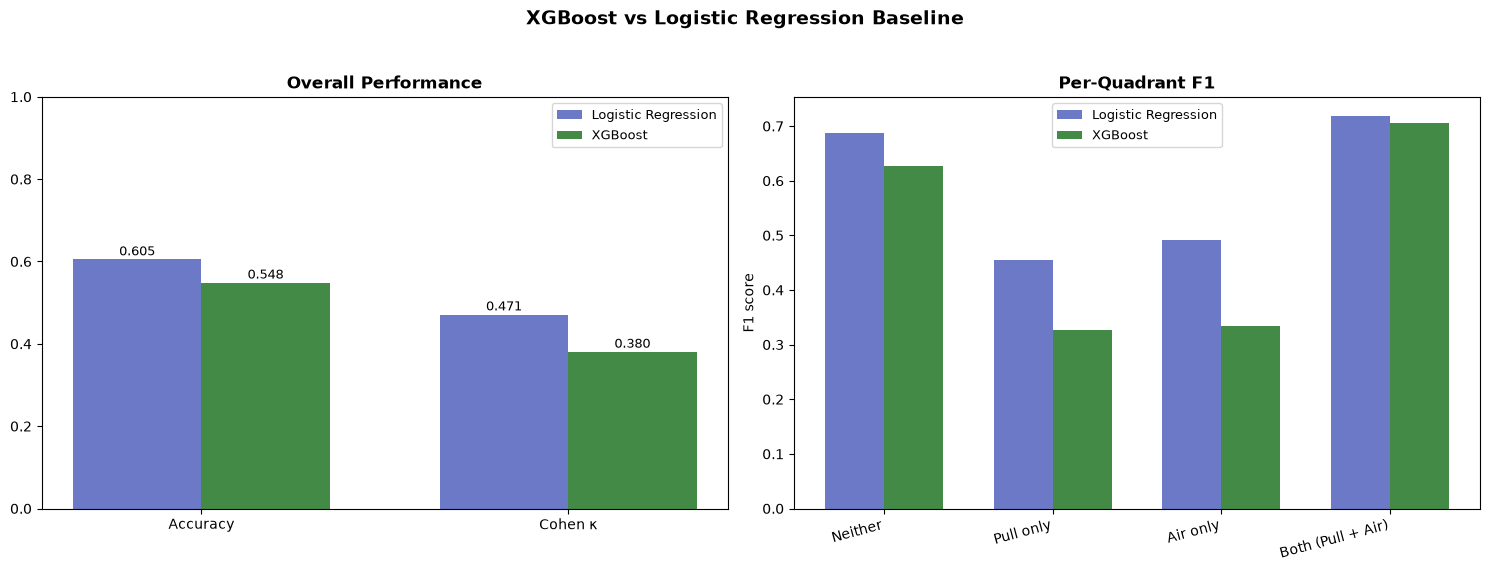

In [128]:
# ── Visual: grouped bar chart, κ/accuracy + per-quadrant F1 side by side ───
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Overall metrics
ax = axes[0]
metrics = ["Accuracy", "Cohen κ"]
x = np.arange(len(metrics)); w = 0.35
ax.bar(x - w/2, [comp_df.loc["Logistic Regression", m] for m in metrics], w,
      label="Logistic Regression", color="#5C6BC0", alpha=0.9)
ax.bar(x + w/2, [comp_df.loc["XGBoost", m] for m in metrics], w,
      label="XGBoost", color="#2E7D32", alpha=0.9)
for i, m in enumerate(metrics):
    ax.text(i - w/2, comp_df.loc["Logistic Regression", m] + 0.01,
           f"{comp_df.loc['Logistic Regression', m]:.3f}", ha="center", fontsize=9)
    ax.text(i + w/2, comp_df.loc["XGBoost", m] + 0.01,
           f"{comp_df.loc['XGBoost', m]:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1); ax.set_title("Overall Performance", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)

# Per-quadrant F1
ax = axes[1]
x = np.arange(len(QUAD_ORDER)); w = 0.35
ax.bar(x - w/2, f1_comp["Logistic Regression"], w, label="Logistic Regression",
      color="#5C6BC0", alpha=0.9)
ax.bar(x + w/2, f1_comp["XGBoost"], w, label="XGBoost", color="#2E7D32", alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(QUAD_ORDER, rotation=15, ha="right")
ax.set_ylabel("F1 score")
ax.set_title("Per-Quadrant F1", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)

plt.suptitle("XGBoost vs Logistic Regression Baseline", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

In [129]:
# ── SHAP interaction values (per quadrant class) ────────────────────────────
interaction_values = explainer.shap_interaction_values(xgb_df[XGB_FEATS])
print(f"Interaction values shape: {interaction_values.shape}")
# (n_samples, n_features, n_features, n_classes)

Interaction values shape: (496, 4, 4, 4)



=== Neither — SHAP Interaction Summary ===


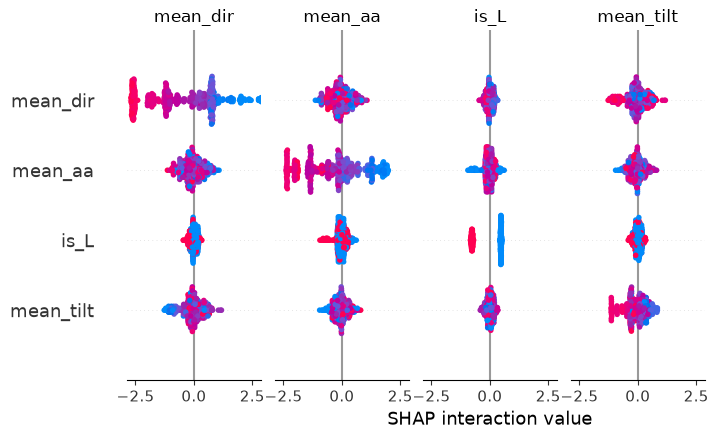


=== Pull only — SHAP Interaction Summary ===


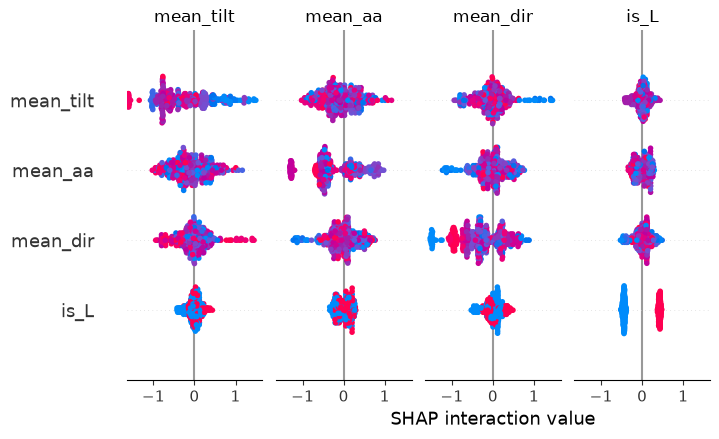


=== Air only — SHAP Interaction Summary ===


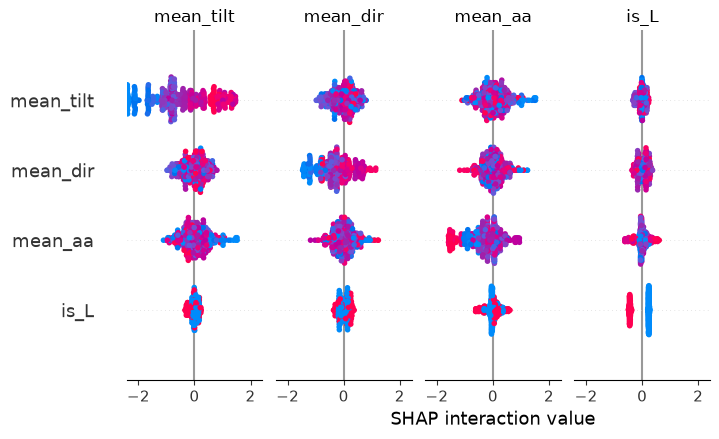


=== Both (Pull + Air) — SHAP Interaction Summary ===


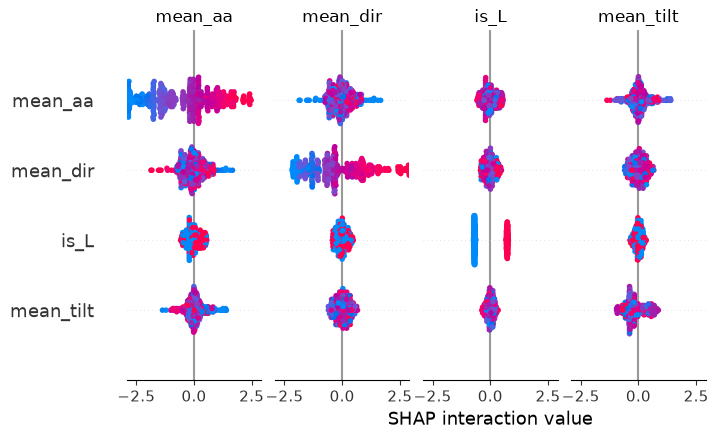

In [130]:
# ── Interaction summary plot, per quadrant class ────────────────────────────
# shap.summary_plot on interaction values shows a feature-x-feature grid of
# beeswarms — the diagonal is each feature's main effect, off-diagonal cells
# are pairwise interaction effects.
for q in QUAD_ORDER:
    i = class_to_idx[q]
    print(f"\n=== {q} — SHAP Interaction Summary ===")
    shap.summary_plot(interaction_values[:, :, :, i], xgb_df[XGB_FEATS],
                      max_display=len(XGB_FEATS))

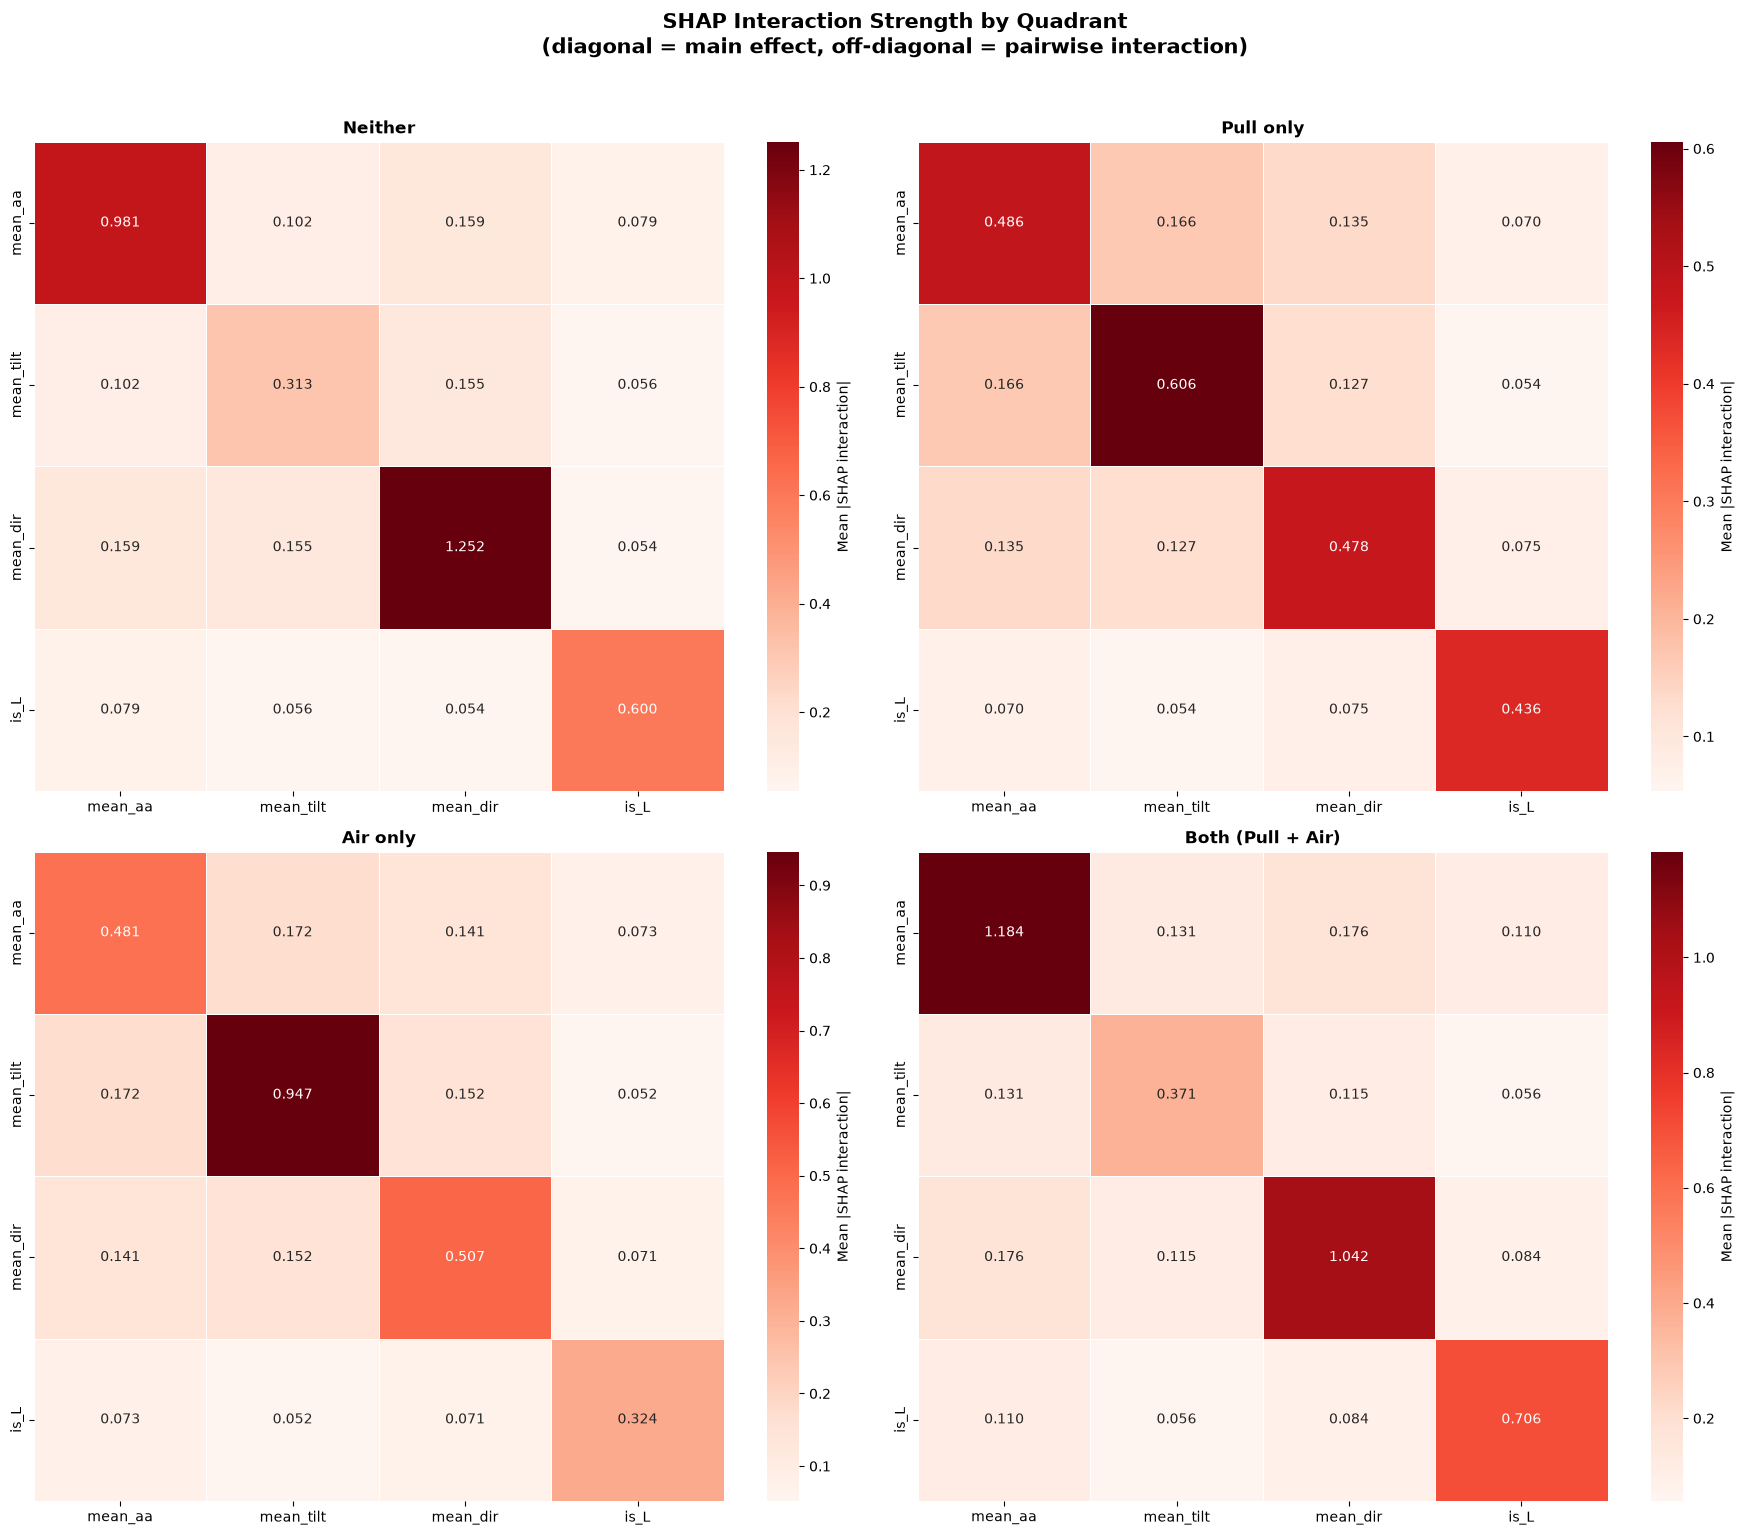

In [131]:
# ── Mean |interaction| heatmap per class — the compact, comparable view ────
fig, axes = plt.subplots(2, 2, figsize=(18, 15))
for ax, q in zip(axes.flat, QUAD_ORDER):
    i = class_to_idx[q]
    # mean absolute interaction strength between every feature pair
    mean_inter = np.abs(interaction_values[:, :, :, i]).mean(axis=0)
    inter_df = pd.DataFrame(mean_inter, index=XGB_FEATS, columns=XGB_FEATS)
    sns.heatmap(inter_df, annot=True, fmt=".3f", cmap="Reds", ax=ax,
                linewidths=0.5, linecolor="white", cbar_kws={"label": "Mean |SHAP interaction|"})
    ax.set_title(q, fontsize=12, fontweight="bold")
plt.suptitle("SHAP Interaction Strength by Quadrant\n(diagonal = main effect, off-diagonal = pairwise interaction)",
            fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

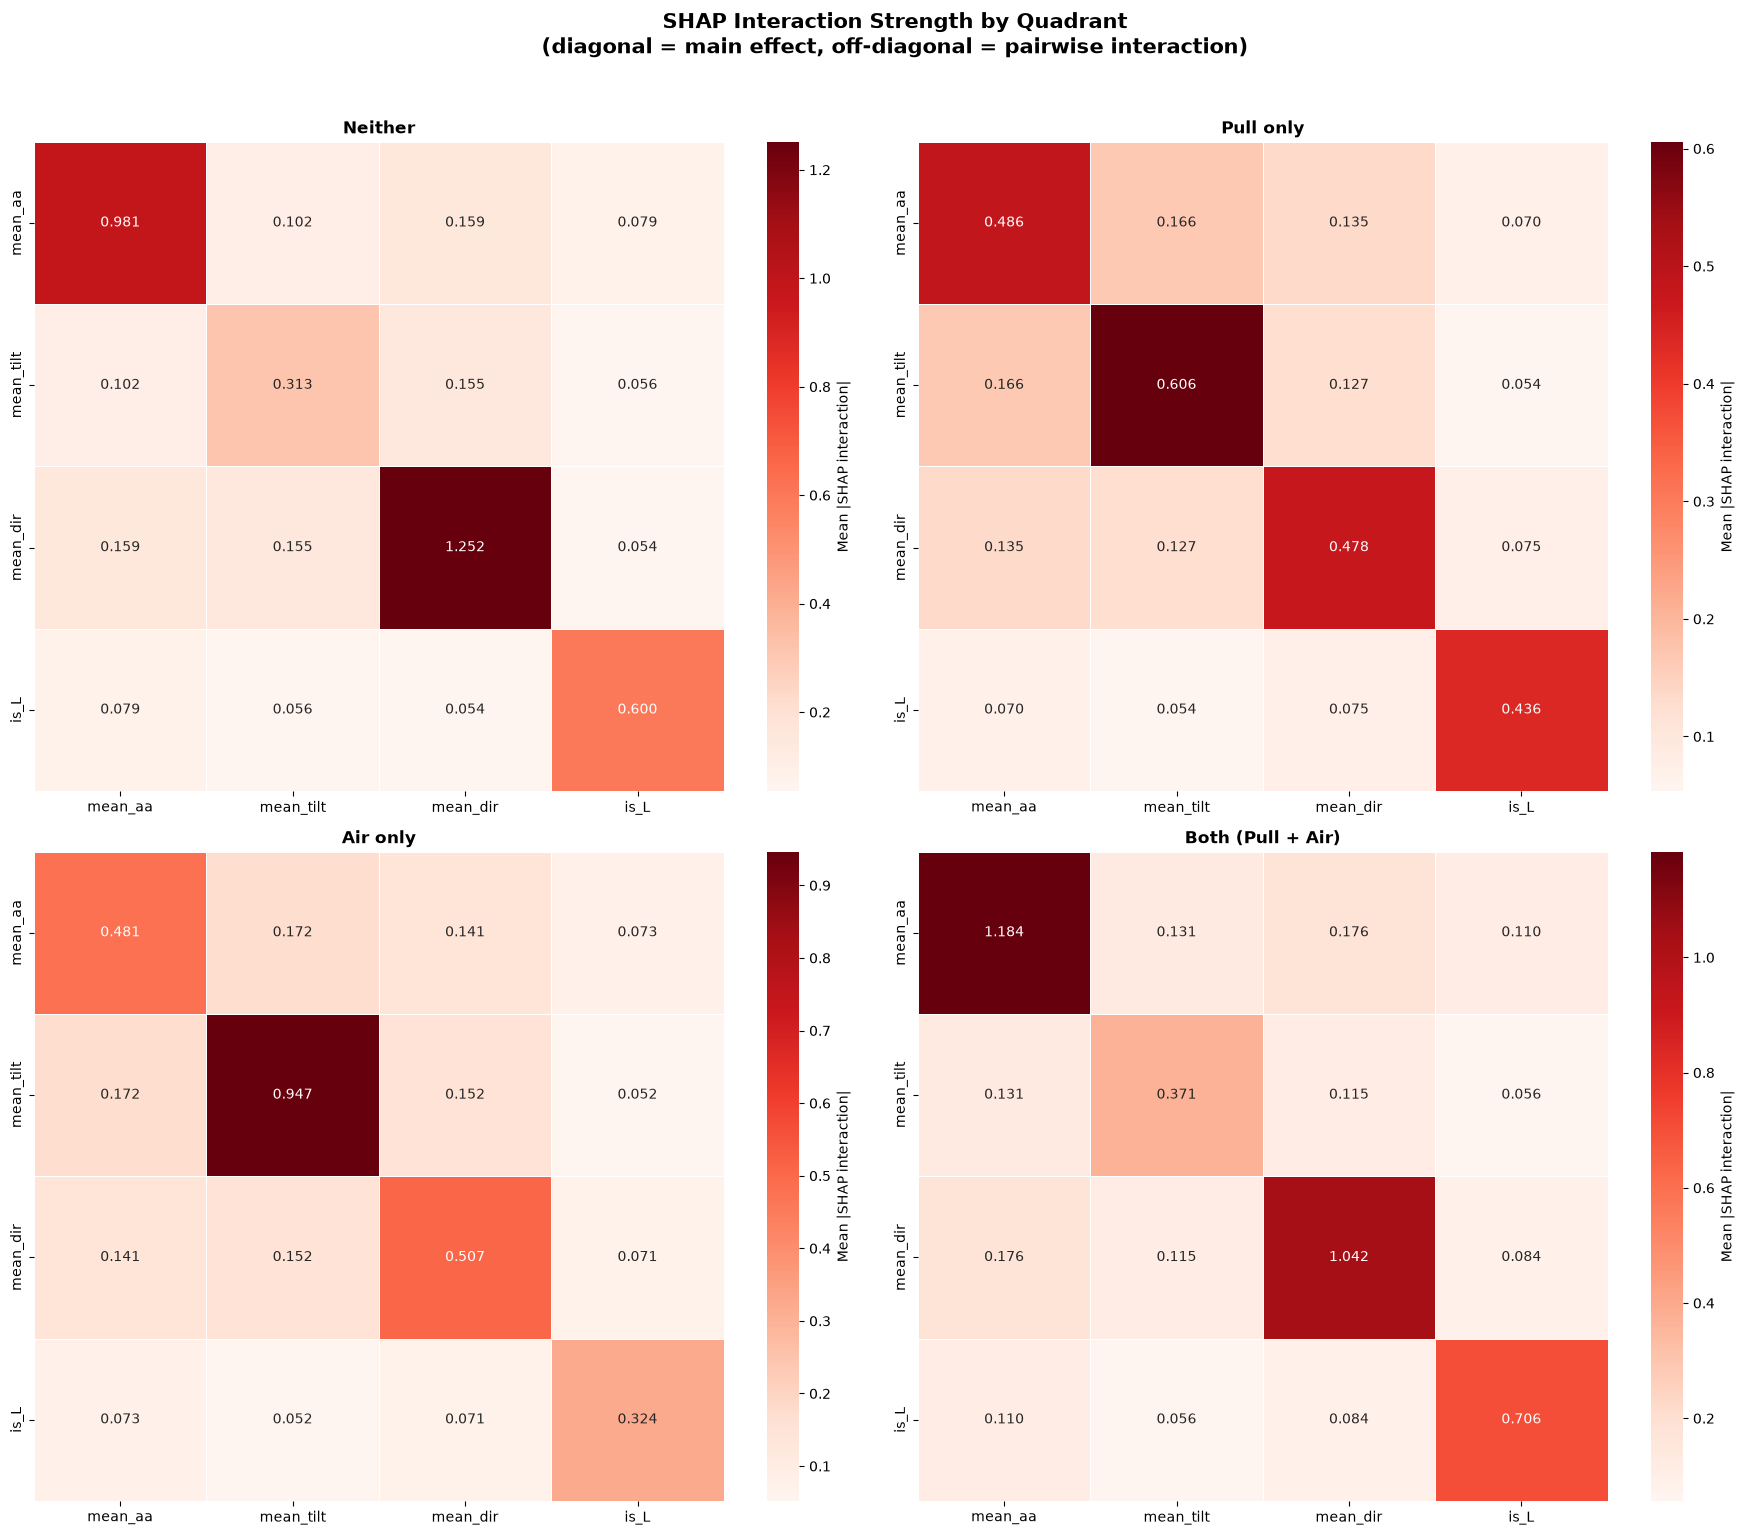

In [132]:
# ── Mean |interaction| heatmap per class — the compact, comparable view ────
fig, axes = plt.subplots(2, 2, figsize=(18, 15))
for ax, q in zip(axes.flat, QUAD_ORDER):
    i = class_to_idx[q]
    # mean absolute interaction strength between every feature pair
    mean_inter = np.abs(interaction_values[:, :, :, i]).mean(axis=0)
    inter_df = pd.DataFrame(mean_inter, index=XGB_FEATS, columns=XGB_FEATS)
    sns.heatmap(inter_df, annot=True, fmt=".3f", cmap="Reds", ax=ax,
                linewidths=0.5, linecolor="white", cbar_kws={"label": "Mean |SHAP interaction|"})
    ax.set_title(q, fontsize=12, fontweight="bold")
plt.suptitle("SHAP Interaction Strength by Quadrant\n(diagonal = main effect, off-diagonal = pairwise interaction)",
            fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [133]:
# ── Top interaction pairs, ranked, combined across all classes ─────────────
# Sum interaction strength across the 4 class outputs to find the single
# strongest pairwise relationship overall (excluding the diagonal/main effects)
mean_inter_all_classes = np.abs(interaction_values).mean(axis=(0, 3))  # avg over samples & classes
inter_no_diag = mean_inter_all_classes.copy()
np.fill_diagonal(inter_no_diag, 0)

pairs = []
for i in range(len(XGB_FEATS)):
    for j in range(i+1, len(XGB_FEATS)):
        pairs.append({"feature_1": XGB_FEATS[i], "feature_2": XGB_FEATS[j],
                      "mean_abs_interaction": inter_no_diag[i, j]})
pairs_df = pd.DataFrame(pairs).sort_values("mean_abs_interaction", ascending=False)
print("── Strongest feature-pair interactions (averaged across all 4 classes) ──")
print(pairs_df.head(10).round(4).to_string(index=False))

── Strongest feature-pair interactions (averaged across all 4 classes) ──
feature_1 feature_2  mean_abs_interaction
  mean_aa  mean_dir                0.1525
  mean_aa mean_tilt                0.1428
mean_tilt  mean_dir                0.1370
  mean_aa      is_L                0.0832
 mean_dir      is_L                0.0711
mean_tilt      is_L                0.0544


In [134]:
# ── Logistic Regression with an explicit mean_dir × is_L interaction term ──
xgb_df["dir_x_isL"] = xgb_df["mean_dir"] * xgb_df["is_L"]

XGB_FEATS_INTER = XGB_FEATS

pipe_lr_inter = Pipeline([("s", StandardScaler()),
                          ("m", LogisticRegression(
                              multi_class="multinomial", solver="lbfgs",
                              max_iter=2000, C=0.5, class_weight="balanced",
                              random_state=SEED))])

proba_lr_inter = cross_val_predict(pipe_lr_inter, xgb_df[XGB_FEATS_INTER].values, y_enc,
                                   cv=gkf_xgb, groups=groups_xgb, method="predict_proba")
pred_lr_inter = le.inverse_transform(proba_lr_inter.argmax(axis=1))

acc_lr_inter = accuracy_score(actual_xgb, pred_lr_inter)
kap_lr_inter = cohen_kappa_score(actual_xgb, pred_lr_inter)

print(f"── Logistic Regression + mean_dir × is_L interaction ────────────────────")
print(f"  Accuracy = {acc_lr_inter:.4f}  (base LR was {acc_lr:.4f})")
print(f"  Cohen κ  = {kap_lr_inter:.4f}  (base LR was {kap_lr:.4f})")
print(f"\n  Per-class one-vs-rest AUC:")
for q in QUAD_ORDER:
    i = class_to_idx[q]
    y_oc = (actual_xgb == q).astype(int)
    print(f"    {q:<22} AUC = {roc_auc_score(y_oc, proba_lr_inter[:, i]):.4f}")

── Logistic Regression + mean_dir × is_L interaction ────────────────────
  Accuracy = 0.6048  (base LR was 0.6048)
  Cohen κ  = 0.4711  (base LR was 0.4711)

  Per-class one-vs-rest AUC:
    Neither                AUC = 0.8911
    Pull only              AUC = 0.7304
    Air only               AUC = 0.7982
    Both (Pull + Air)      AUC = 0.9023


In [135]:
# ── Three-way comparison: LR base, LR + interaction, XGBoost ───────────────
comparison_rows = []
for name, pred, proba in [("Logistic Regression (base)", pred_lr_baseline, proba_lr_baseline),
                          ("Logistic Regression + dir×isL", pred_lr_inter, proba_lr_inter),
                          ("XGBoost", pred_xgb, proba_xgb)]:
    row = {"Model": name,
          "Accuracy": accuracy_score(actual_xgb, pred),
          "Cohen κ": cohen_kappa_score(actual_xgb, pred)}
    for q in QUAD_ORDER:
        i = class_to_idx[q]
        y_oc = (actual_xgb == q).astype(int)
        row[f"AUC: {q}"] = roc_auc_score(y_oc, proba[:, i])
    comparison_rows.append(row)

comp_df3 = pd.DataFrame(comparison_rows).set_index("Model")
print("── Three-way model comparison ───────────────────────────────────────────")
print(comp_df3.round(4).to_string())

── Three-way model comparison ───────────────────────────────────────────
                               Accuracy  Cohen κ  AUC: Neither  AUC: Pull only  AUC: Air only  AUC: Both (Pull + Air)
Model                                                                                                                
Logistic Regression (base)       0.6048   0.4711        0.8911          0.7304         0.7982                  0.9023
Logistic Regression + dir×isL    0.6048   0.4711        0.8911          0.7304         0.7982                  0.9023
XGBoost                          0.5484   0.3804        0.8474          0.6974         0.7538                  0.8649


In [136]:
# ── Per-quadrant F1: does the interaction close the gap with XGBoost anywhere?
f1_lr_inter = pd.DataFrame(classification_report(actual_xgb, pred_lr_inter, labels=QUAD_ORDER,
                          output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]

f1_comp3 = pd.DataFrame({
    "LR (base)": f1_lr,
    "LR + dir×isL": f1_lr_inter,
    "XGBoost": f1_xgb,
})
f1_comp3["Interaction gain (vs base LR)"] = f1_comp3["LR + dir×isL"] - f1_comp3["LR (base)"]
print("── Per-quadrant F1 across all three models ─────────────────────────────")
print(f1_comp3.round(3).to_string())

── Per-quadrant F1 across all three models ─────────────────────────────
                   LR (base)  LR + dir×isL  XGBoost  Interaction gain (vs base LR)
Neither               0.6880        0.6880   0.6280                         0.0000
Pull only             0.4540        0.4540   0.3270                         0.0000
Air only              0.4910        0.4910   0.3330                         0.0000
Both (Pull + Air)     0.7180        0.7180   0.7050                         0.0000


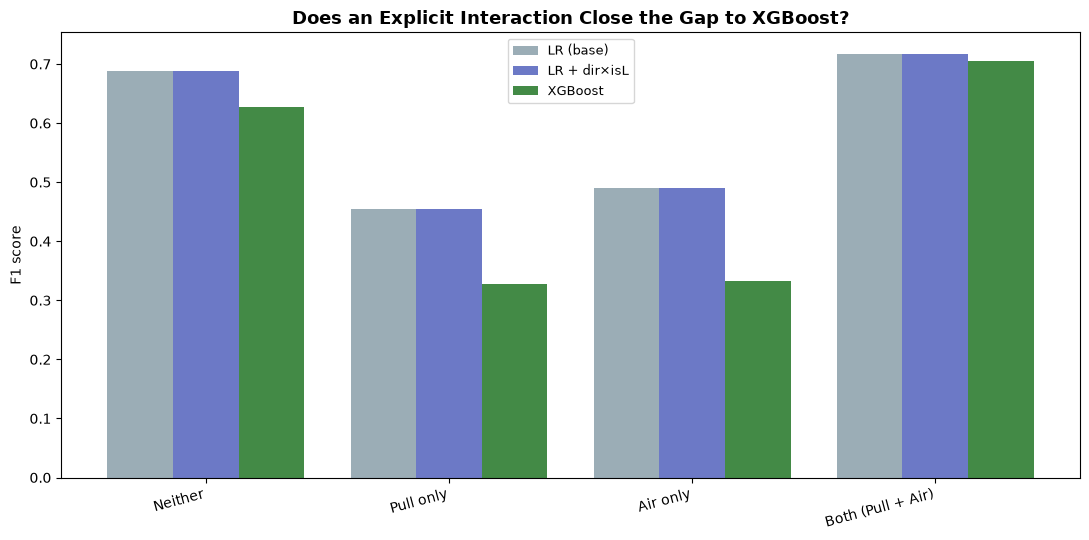

In [137]:
# ── Visual ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(QUAD_ORDER)); w = 0.27
ax.bar(x - w, f1_comp3["LR (base)"], w, label="LR (base)", color="#90A4AE", alpha=0.9)
ax.bar(x,     f1_comp3["LR + dir×isL"], w, label="LR + dir×isL", color="#5C6BC0", alpha=0.9)
ax.bar(x + w, f1_comp3["XGBoost"], w, label="XGBoost", color="#2E7D32", alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(QUAD_ORDER, rotation=15, ha="right")
ax.set_ylabel("F1 score")
ax.set_title("Does an Explicit Interaction Close the Gap to XGBoost?",
            fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

In [138]:
# ── Fit the winning model on full data for interpretation ──────────────────
pipe_lr_inter.fit(xgb_df[XGB_FEATS_INTER].values, y_enc)
lr_model = pipe_lr_inter.named_steps["m"]
scaler = pipe_lr_inter.named_steps["s"]

# Standardized coefficients — one row per feature, one column per quadrant
coef_std = pd.DataFrame(lr_model.coef_, index=le.classes_, columns=XGB_FEATS_INTER).T[QUAD_ORDER]

print("── Standardized coefficients (relative importance, per quadrant) ───────")
print(coef_std.round(3).to_string())

── Standardized coefficients (relative importance, per quadrant) ───────
           Neither  Pull only  Air only  Both (Pull + Air)
mean_aa    -1.2190    -0.0840   -0.0490             1.3520
mean_tilt  -0.0980    -0.4390    0.6060            -0.0680
mean_dir   -1.4950    -0.1030    0.2320             1.3650
is_L       -0.6430     0.3650   -0.3900             0.6670



── Odds ratios (per 1-SD increase in feature) ───────────────────────────
           Neither  Pull only  Air only  Both (Pull + Air)
mean_aa     0.2950     0.9190    0.9530             3.8660
mean_tilt   0.9070     0.6440    1.8320             0.9340
mean_dir    0.2240     0.9020    1.2620             3.9170
is_L        0.5260     1.4410    0.6770             1.9490


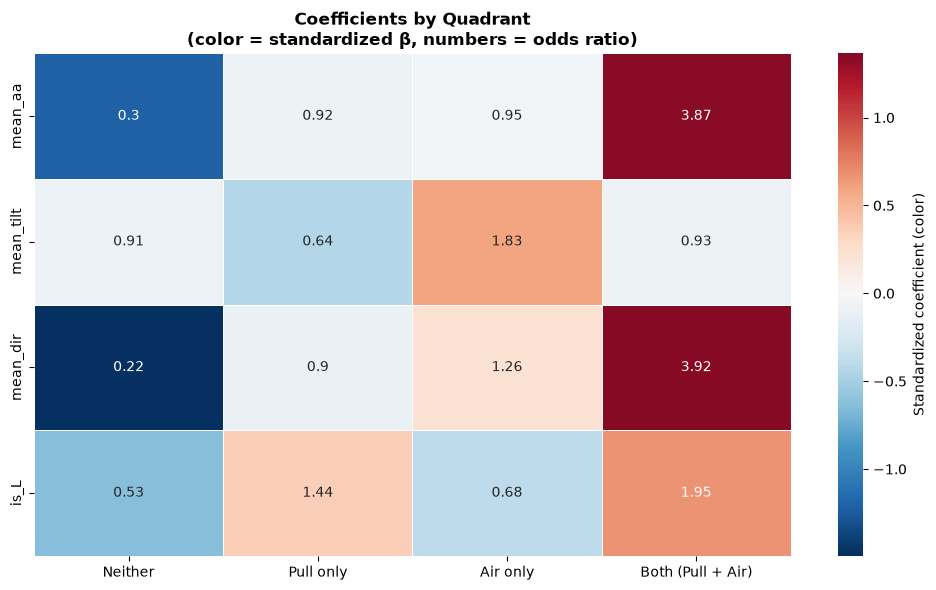

In [139]:
# ── Odds ratios: exp(coefficient) — the interpretable magnitude ────────────
# odds_ratio > 1: a 1-SD increase in this feature RAISES the odds of that
# quadrant (relative to the model's overall reference point).
# odds_ratio < 1: it LOWERS the odds.
odds_ratios = np.exp(coef_std)

print("\n── Odds ratios (per 1-SD increase in feature) ───────────────────────────")
print(odds_ratios.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(coef_std, annot=odds_ratios.round(2), fmt="", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Standardized coefficient (color)"})
ax.set_title("Coefficients by Quadrant\n(color = standardized β, numbers = odds ratio)",
             fontsize=12, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [142]:
# ── Re-verify mean_dir's mirror convention, rigorously, one more time ──────
print("── Pooled check (as before) ─────────────────────────────────────────────")
r_pooled = batter_df[["mean_dir", "pull_pct"]].dropna().corr().iloc[0, 1]
print(f"corr(mean_dir, pull_pct) = {r_pooled:+.3f}   (expect +)")

print("\n── Per-handedness check — the more rigorous test ────────────────────────")
print("(A pooled check can pass even if one handedness is backwards, as long")
print(" as the other outweighs it. This checks each group independently.)")
for s in ["R", "L"]:
    sub = batter_df[batter_df["stand"] == s].dropna(subset=["mean_dir", "pull_pct"])
    r_s = sub[["mean_dir", "pull_pct"]].corr().iloc[0, 1]
    print(f"  {s}HB (n={len(sub)}): corr(mean_dir, pull_pct) = {r_s:+.3f}   (expect + for BOTH)")

── Pooled check (as before) ─────────────────────────────────────────────
corr(mean_dir, pull_pct) = +0.454   (expect +)

── Per-handedness check — the more rigorous test ────────────────────────
(A pooled check can pass even if one handedness is backwards, as long
 as the other outweighs it. This checks each group independently.)
  RHB (n=283): corr(mean_dir, pull_pct) = +0.500   (expect + for BOTH)
  LHB (n=213): corr(mean_dir, pull_pct) = +0.526   (expect + for BOTH)


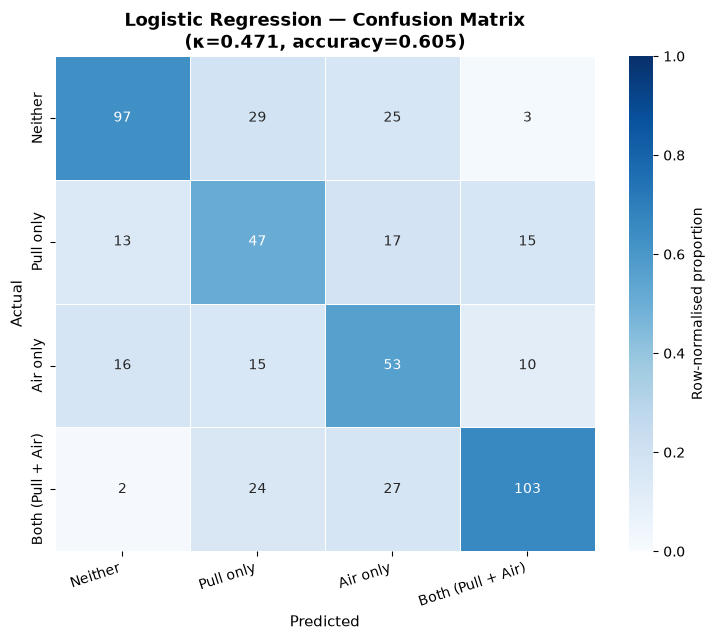

In [143]:
# ── 1. Confusion matrix ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7.5, 6.5))
cm  = confusion_matrix(actual_xgb, pred_lr_inter, labels=QUAD_ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
            xticklabels=QUAD_ORDER, yticklabels=QUAD_ORDER,
            linewidths=0.6, linecolor="white", ax=ax,
            cbar_kws={"label": "Row-normalised proportion"})
ax.set_title(f"Logistic Regression — Confusion Matrix\n"
            f"(κ={kap_lr_inter:.3f}, accuracy={acc_lr_inter:.3f})",
            fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted", fontsize=11); ax.set_ylabel("Actual", fontsize=11)
ax.set_xticklabels(QUAD_ORDER, rotation=18, ha="right")
plt.tight_layout(); plt.show()

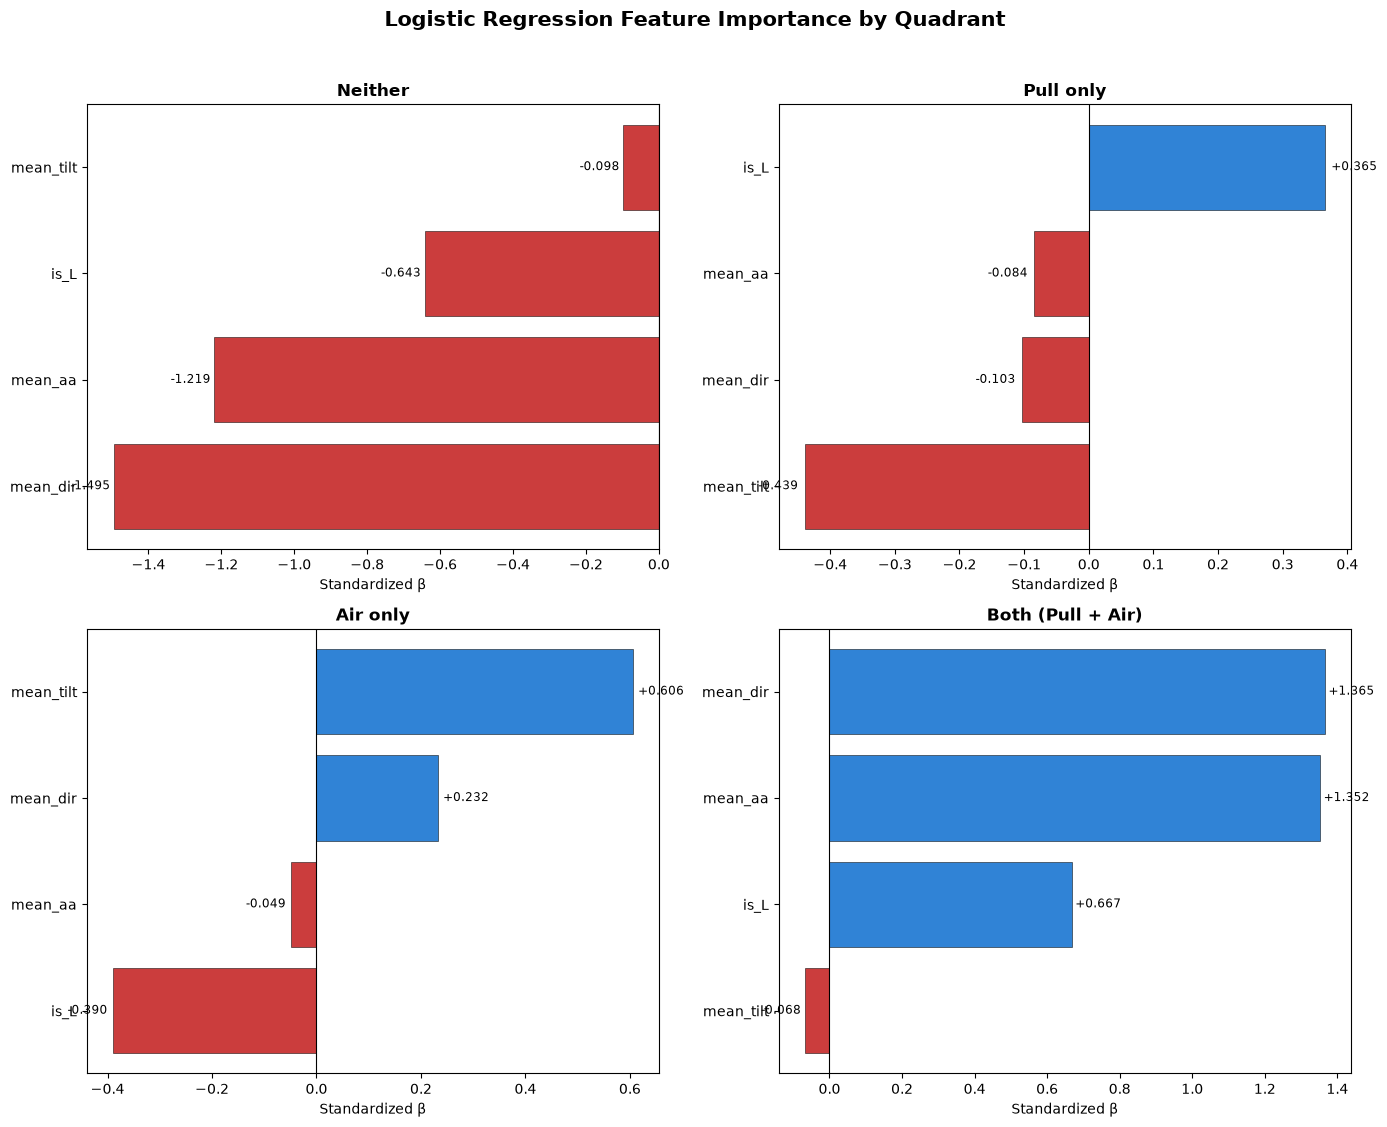

In [150]:
# ── Standardized coefficient plot, 2x2 grid by quadrant ────────────────────
coef_std = pd.DataFrame(lr_model.coef_, index=le.classes_,
                        columns=XGB_FEATS_INTER).T[QUAD_ORDER]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, q in zip(axes.flat, QUAD_ORDER):
    vals = coef_std[q].sort_values()
    colors = ["#1976D2" if v > 0 else "#C62828" for v in vals.values]
    ax.barh(vals.index, vals.values, color=colors, alpha=0.9, edgecolor="black", linewidth=0.4)
    ax.axvline(0, color="black", lw=0.8)
    for i, v in enumerate(vals.values):
        ax.text(v + np.sign(v)*0.01, i, f"{v:+.3f}", va="center",
                ha="left" if v > 0 else "right", fontsize=8.5)
    ax.set_title(q, fontsize=12, fontweight="bold")
    ax.set_xlabel("Standardized β")

plt.suptitle("Logistic Regression Feature Importance by Quadrant", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

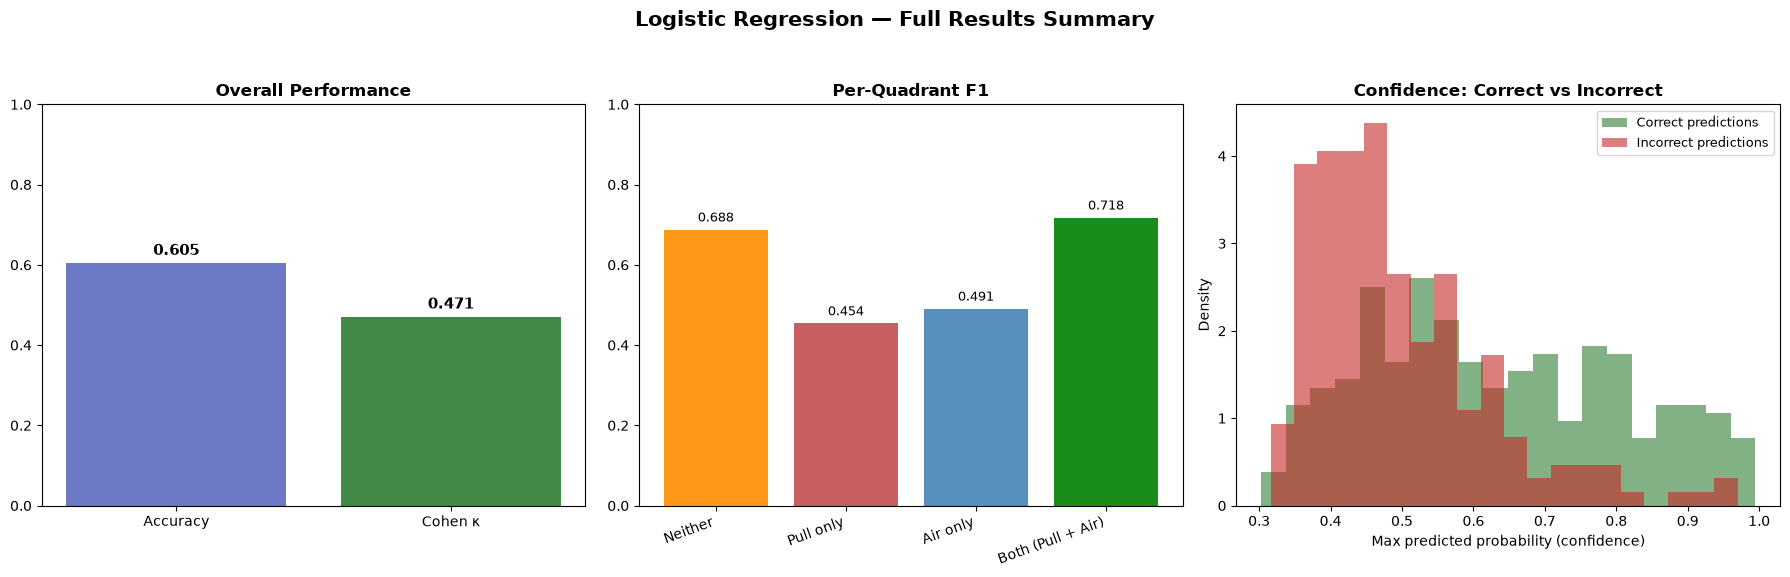

In [ ]:
# ── 4. Summary dashboard: accuracy/κ + per-quadrant F1 + prediction confidence
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Overall metrics
ax = axes[0]
metrics = {"Accuracy": acc_lr_inter, "Cohen κ": kap_lr_inter}
bars = ax.bar(metrics.keys(), metrics.values(), color=["#5C6BC0", "#2E7D32"], alpha=0.9)
for b, v in zip(bars, metrics.values()):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 1)
ax.set_title("Overall Performance", fontsize=12, fontweight="bold")

# Per-quadrant F1
ax = axes[1]
f1_scores = pd.DataFrame(classification_report(actual_xgb, pred_lr_inter, labels=QUAD_ORDER,
                        output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
bars = ax.bar(QUAD_ORDER, f1_scores, color=[QUAD_COLORS[q] for q in QUAD_ORDER], alpha=0.9)
for b, v in zip(bars, f1_scores):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylim(0, 1)
ax.set_xticklabels(QUAD_ORDER, rotation=20, ha="right")
ax.set_title("Per-Quadrant F1", fontsize=12, fontweight="bold")

# Prediction confidence distribution
ax = axes[2]
max_proba = proba_lr_inter.max(axis=1)
correct = (pred_lr_inter == actual_xgb)
ax.hist(max_proba[correct], bins=20, alpha=0.6, color="#2E7D32", label="Correct predictions", density=True)
ax.hist(max_proba[~correct], bins=20, alpha=0.6, color="#C62828", label="Incorrect predictions", density=True)
ax.set_xlabel("Max predicted probability (confidence)")
ax.set_ylabel("Density")
ax.set_title("Confidence: Correct vs Incorrect", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)

plt.suptitle("Logistic Regression — Full Results Summary", fontsize=15, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

In [ ]:
# ── Per-quadrant accuracy (recall) ──────────────────────────────────────────
per_quad_acc = {}
for q in QUAD_ORDER:
    mask = actual_xgb == q
    per_quad_acc[q] = (pred_lr_inter[mask] == q).mean()

acc_df = pd.Series(per_quad_acc).reindex(QUAD_ORDER).rename("accuracy")
n_per_quad = pd.Series({q: (actual_xgb == q).sum() for q in QUAD_ORDER}).reindex(QUAD_ORDER).rename("n")

print("── Per-quadrant accuracy (recall) ───────────────────────────────────────")
print(pd.concat([acc_df, n_per_quad], axis=1).round(3).to_string())
print(f"\nOverall accuracy: {acc_lr_inter:.3f}")
print(f"Random-chance baseline (4 classes): {1/4:.3f}")

── Per-quadrant accuracy (recall) ───────────────────────────────────────
                   accuracy    n
Neither              0.6300  154
Pull only            0.5110   92
Air only             0.5640   94
Both (Pull + Air)    0.6600  156

Overall accuracy: 0.605
Random-chance baseline (4 classes): 0.250


In [ ]:
# ── Per-quadrant accuracy vs a PROPORTIONAL baseline (not flat 1/4) ─────────
# Proportional baseline: if you guessed each quadrant randomly, in proportion
# to its true frequency, your expected accuracy for a hitter truly in quadrant
# q is just P(q) itself — i.e., guessing "Neither" with probability equal to
# Neither's base rate gets you Neither's base rate right by chance.
quad_freq = pd.Series({q: (actual_xgb == q).mean() for q in QUAD_ORDER}).reindex(QUAD_ORDER)

print("── Quadrant base rates (= proportional-guessing accuracy for that class) ─")
print(quad_freq.round(3).to_string())

per_quad_acc = {}
for q in QUAD_ORDER:
    mask = actual_xgb == q
    per_quad_acc[q] = (pred_lr_inter[mask] == q).mean()

acc_df = pd.Series(per_quad_acc).reindex(QUAD_ORDER).rename("accuracy")
n_per_quad = pd.Series({q: (actual_xgb == q).sum() for q in QUAD_ORDER}).reindex(QUAD_ORDER).rename("n")

result = pd.concat([n_per_quad, acc_df, quad_freq.rename("proportional_baseline")], axis=1)
result["lift_over_baseline"] = result["accuracy"] - result["proportional_baseline"]
print("\n── Per-quadrant accuracy vs proportional baseline ──────────────────────")
print(result.round(3).to_string())

── Quadrant base rates (= proportional-guessing accuracy for that class) ─
Neither             0.3100
Pull only           0.1850
Air only            0.1900
Both (Pull + Air)   0.3150

── Per-quadrant accuracy vs proportional baseline ──────────────────────
                     n  accuracy  proportional_baseline  lift_over_baseline
Neither            154    0.6300                 0.3100              0.3190
Pull only           92    0.5110                 0.1850              0.3250
Air only            94    0.5640                 0.1900              0.3740
Both (Pull + Air)  156    0.6600                 0.3150              0.3460


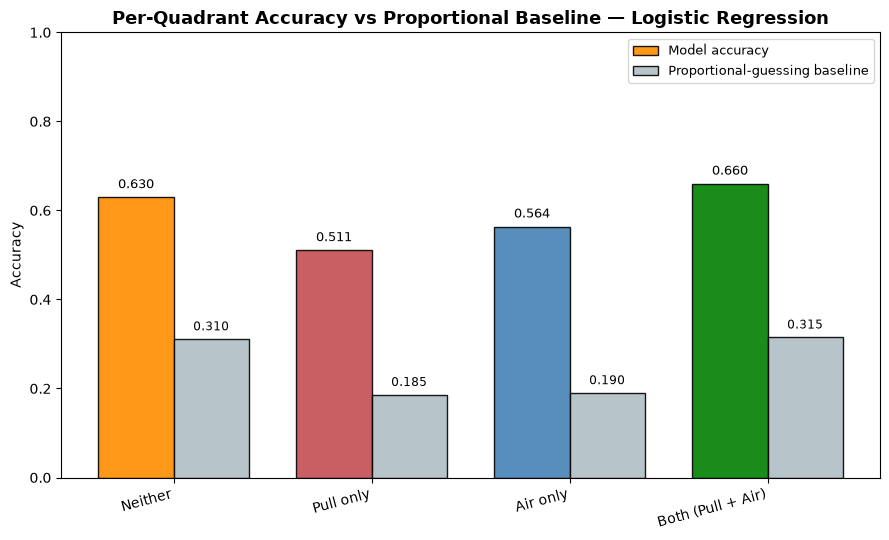

In [ ]:
# ── Visual ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(QUAD_ORDER)); w = 0.38
bars1 = ax.bar(x - w/2, acc_df, w, label="Model accuracy",
               color=[QUAD_COLORS[q] for q in QUAD_ORDER], alpha=0.9, edgecolor="black")
bars2 = ax.bar(x + w/2, quad_freq, w, label="Proportional-guessing baseline",
               color="#B0BEC5", alpha=0.9, edgecolor="black")

for b, v in zip(bars1, acc_df):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
for b, v in zip(bars2, quad_freq):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", fontsize=8.5)

ax.set_xticks(x); ax.set_xticklabels(QUAD_ORDER, rotation=15, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
ax.set_title("Per-Quadrant Accuracy vs Proportional Baseline — Logistic Regression",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

In [177]:
# ── Residualize each feature against bat speed, then compare by quadrant ───
CONTROL_FEATS_FOR_BS = [c for c in ["mean_tilt", "mean_aa", "mean_dir", "fb_swing_share",
                                    "mean_length", "o_swing_pct", "mean_depth",
                                    "k_pct", "bb_pct", "contact_rate", "barrel_rate",
                                    "mean_ev", "wOBA", "wOBAcon", "pull_air_pct"]
                       if c in batter_df.columns and c != "mean_bs"]

bs_ctrl_df = batter_df.dropna(subset=CONTROL_FEATS_FOR_BS + ["mean_bs", "quadrant"]).copy()
groups_bs = bs_ctrl_df["batter"].values
gkf_bs = GroupKFold(n_splits=min(CV_FOLDS, bs_ctrl_df["batter"].nunique()))

residuals = {}
for feat in CONTROL_FEATS_FOR_BS:
    X_bs = bs_ctrl_df[["mean_bs"]].values
    y_feat = bs_ctrl_df[feat].values
    pred = cross_val_predict(
        Pipeline([("s", StandardScaler()), ("m", LinearRegression())]),
        X_bs, y_feat, cv=gkf_bs, groups=groups_bs)
    residuals[feat] = y_feat - pred

resid_df = pd.DataFrame(residuals, index=bs_ctrl_df.index)
resid_df["quadrant"] = bs_ctrl_df["quadrant"].values

print(f"Residualized {len(CONTROL_FEATS_FOR_BS)} features against bat speed.")

Residualized 13 features against bat speed.


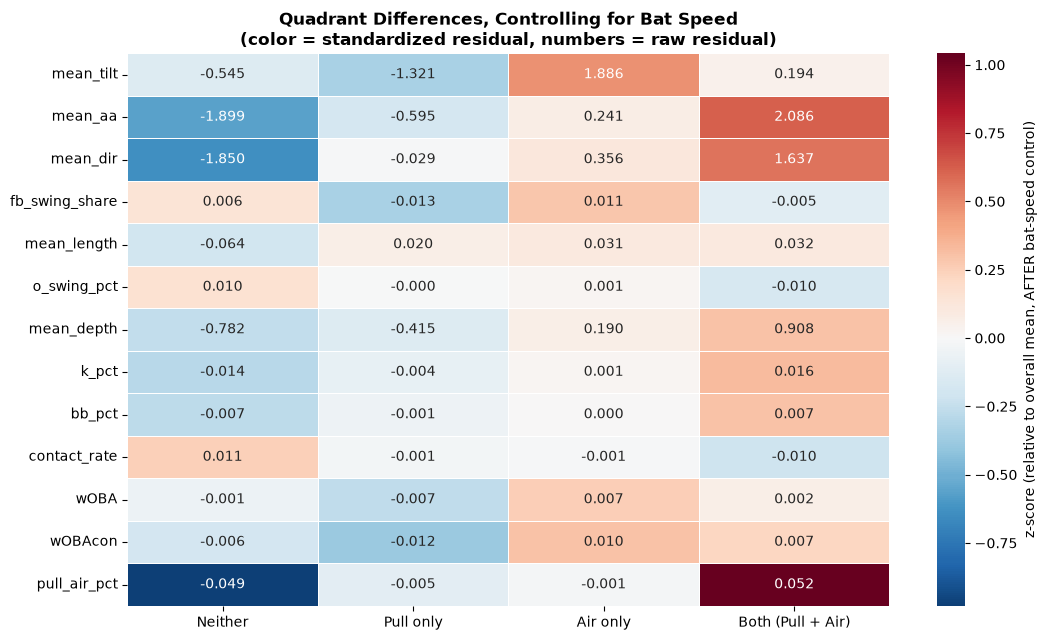

In [178]:
# ── Profile heatmap: quadrant differences AFTER removing bat-speed effects ─
resid_z = (resid_df[CONTROL_FEATS_FOR_BS] - resid_df[CONTROL_FEATS_FOR_BS].mean()) / \
          resid_df[CONTROL_FEATS_FOR_BS].std()
resid_means_z = resid_z.groupby(resid_df["quadrant"]).mean().reindex(QUAD_ORDER)
resid_means_raw = resid_df.groupby("quadrant")[CONTROL_FEATS_FOR_BS].mean().reindex(QUAD_ORDER)

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(resid_means_z.T.values.astype(float),
            annot=resid_means_raw.T.values.astype(float), fmt=".3f",
            cmap="RdBu_r", center=0, linewidths=0.5, linecolor="white", ax=ax,
            xticklabels=QUAD_ORDER, yticklabels=CONTROL_FEATS_FOR_BS,
            cbar_kws={"label": "z-score (relative to overall mean, AFTER bat-speed control)"})
ax.set_title("Quadrant Differences, Controlling for Bat Speed\n(color = standardized residual, numbers = raw residual)",
             fontsize=12, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

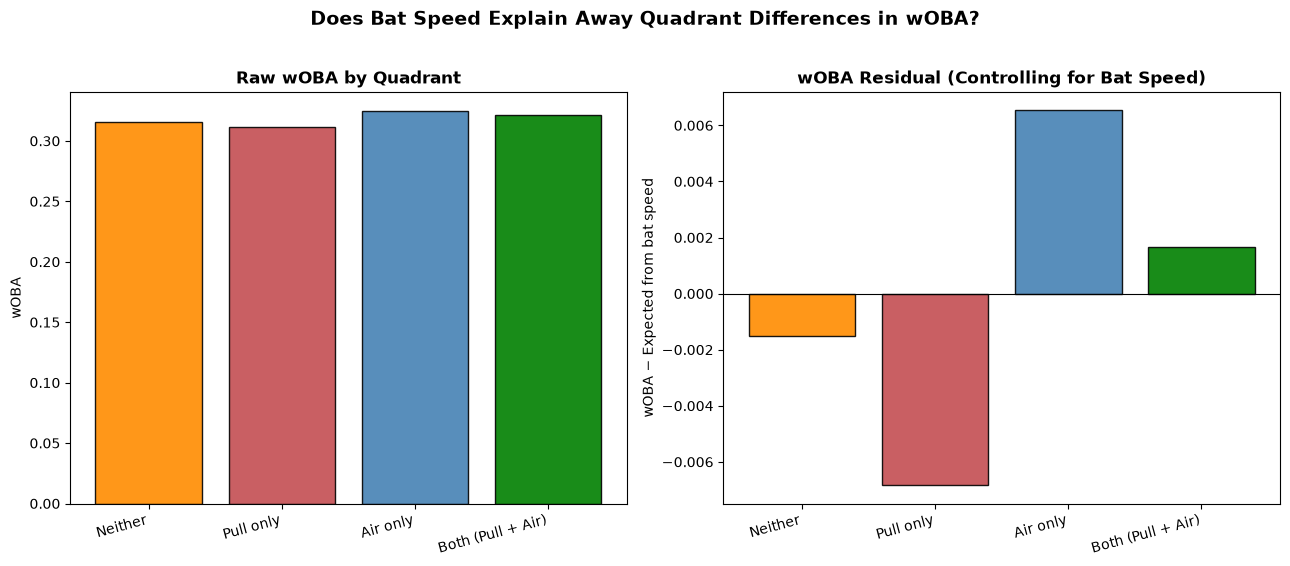

── wOBA by quadrant: raw vs bat-speed-controlled residual ──────────────
                   raw_wOBA  wOBA_residual
quadrant                                  
Neither              0.3157        -0.0015
Pull only            0.3118        -0.0068
Air only             0.3244         0.0065
Both (Pull + Air)    0.3211         0.0017


In [179]:
# ── Concrete outcome example: wOBA by quadrant, before vs after controlling ─
if "wOBA" in batter_df.columns:
    raw_woba_by_quad = batter_df.groupby("quadrant")["wOBA"].mean().reindex(QUAD_ORDER)
    resid_woba_by_quad = resid_df.groupby("quadrant")["wOBA"].mean().reindex(QUAD_ORDER)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    colors = [QUAD_COLORS[q] for q in QUAD_ORDER]

    axes[0].bar(QUAD_ORDER, raw_woba_by_quad, color=colors, alpha=0.9, edgecolor="black")
    axes[0].set_title("Raw wOBA by Quadrant", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("wOBA")
    axes[0].set_xticklabels(QUAD_ORDER, rotation=15, ha="right")

    axes[1].bar(QUAD_ORDER, resid_woba_by_quad, color=colors, alpha=0.9, edgecolor="black")
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set_title("wOBA Residual (Controlling for Bat Speed)", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("wOBA − Expected from bat speed")
    axes[1].set_xticklabels(QUAD_ORDER, rotation=15, ha="right")

    plt.suptitle("Does Bat Speed Explain Away Quadrant Differences in wOBA?",
                fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    print("── wOBA by quadrant: raw vs bat-speed-controlled residual ──────────────")
    print(pd.concat([raw_woba_by_quad.rename("raw_wOBA"),
                     resid_woba_by_quad.rename("wOBA_residual")], axis=1).round(4).to_string())

In [183]:
# ── Comprehensive quadrant strengths/weaknesses breakdown ──────────────────
ALL_PROFILE_FEATS = [c for c in [
   "mean_bs", "k_pct", "bb_pct", "contact_rate",
    "barrel_rate", "mean_ev", "hard_hit_rate", "pull_pct", "air_ball_pct",
    "pull_air_pct", "wOBA", "wOBAcon"
] if c in batter_df.columns]

print(f"Profiling {len(ALL_PROFILE_FEATS)} features: {ALL_PROFILE_FEATS}")

prof = batter_df.dropna(subset=ALL_PROFILE_FEATS + ["quadrant"]).copy()
prof[ALL_PROFILE_FEATS] = prof[ALL_PROFILE_FEATS].apply(pd.to_numeric, errors="coerce")
print(f"n = {len(prof)} hitters with complete profile data")

Profiling 9 features: ['mean_bs', 'k_pct', 'bb_pct', 'contact_rate', 'pull_pct', 'air_ball_pct', 'pull_air_pct', 'wOBA', 'wOBAcon']
n = 494 hitters with complete profile data


In [184]:
# ── Statistical test: is each quadrant's mean significantly different from
#    the REST of the population, for each feature? (one-vs-rest t-test) ────
from scipy.stats import ttest_ind

sig_results = []
for q in QUAD_ORDER:
    in_q = prof["quadrant"] == q
    for feat in ALL_PROFILE_FEATS:
        g_in = prof.loc[in_q, feat]
        g_out = prof.loc[~in_q, feat]
        t_stat, p_val = ttest_ind(g_in, g_out, equal_var=False)
        pooled_sd = np.sqrt(((len(g_in)-1)*g_in.var() + (len(g_out)-1)*g_out.var()) /
                            (len(g_in)+len(g_out)-2))
        cohens_d = (g_in.mean() - g_out.mean()) / pooled_sd if pooled_sd > 0 else np.nan
        sig_results.append({
            "quadrant": q, "feature": feat,
            "mean_in": g_in.mean(), "mean_rest": g_out.mean(),
            "cohens_d": cohens_d, "p_value": p_val,
            "significant": p_val < 0.05
        })

sig_df = pd.DataFrame(sig_results)
print(f"Computed one-vs-rest significance for {len(sig_df)} (quadrant, feature) pairs")

Computed one-vs-rest significance for 36 (quadrant, feature) pairs


In [185]:
# ── Extract top strengths and weaknesses per quadrant, SIGNIFICANT only ────
print("═" * 78)
print("QUADRANT PROFILES — Significant Strengths & Weaknesses (p < 0.05)")
print("═" * 78)

for q in QUAD_ORDER:
    q_data = sig_df[(sig_df["quadrant"] == q) & (sig_df["significant"])].copy()
    q_data = q_data.sort_values("cohens_d", ascending=False)

    strengths = q_data[q_data["cohens_d"] > 0].head(5)
    weaknesses = q_data[q_data["cohens_d"] < 0].sort_values("cohens_d").head(5)

    print(f"\n{'─' * 78}\n{q.upper()}  (n={(prof['quadrant']==q).sum()})\n{'─' * 78}")
    print("STRENGTHS (significantly ABOVE the rest of the population):")
    if len(strengths):
        for _, row in strengths.iterrows():
            print(f"  {row['feature']:<18} d={row['cohens_d']:+.3f}  "
                  f"(this quadrant: {row['mean_in']:.3f}  vs rest: {row['mean_rest']:.3f}, "
                  f"p={row['p_value']:.4f})")
    else:
        print("  (none reach significance)")

    print("\nWEAKNESSES (significantly BELOW the rest of the population):")
    if len(weaknesses):
        for _, row in weaknesses.iterrows():
            print(f"  {row['feature']:<18} d={row['cohens_d']:+.3f}  "
                  f"(this quadrant: {row['mean_in']:.3f}  vs rest: {row['mean_rest']:.3f}, "
                  f"p={row['p_value']:.4f})")
    else:
        print("  (none reach significance)")

══════════════════════════════════════════════════════════════════════════════
QUADRANT PROFILES — Significant Strengths & Weaknesses (p < 0.05)
══════════════════════════════════════════════════════════════════════════════

──────────────────────────────────────────────────────────────────────────────
NEITHER  (n=153)
──────────────────────────────────────────────────────────────────────────────
STRENGTHS (significantly ABOVE the rest of the population):
  contact_rate       d=+0.378  (this quadrant: 0.784  vs rest: 0.763, p=0.0002)

WEAKNESSES (significantly BELOW the rest of the population):
  pull_air_pct       d=-1.902  (this quadrant: 0.128  vs rest: 0.200, p=0.0000)
  air_ball_pct       d=-1.723  (this quadrant: 0.497  vs rest: 0.582, p=0.0000)
  pull_pct           d=-1.719  (this quadrant: 0.393  vs rest: 0.462, p=0.0000)
  k_pct              d=-0.438  (this quadrant: 0.207  vs rest: 0.230, p=0.0000)
  bb_pct             d=-0.419  (this quadrant: 0.072  vs rest: 0.082, p=0.0000